# Instalment payments: EDA and feature engineering

This notebook studies `installments_payments.csv`, the record of every payment made on the loans each applicant held with Home Credit before the current application, and turns it into features, one row per applicant.

It follows the method of `03_bureau_eda_features.ipynb` and `05_previous_application_eda_features.ipynb`. Those two tables raised the model's cross-validated ROC AUC from 0.7685 to 0.7779 and then to 0.7856, and its Kaggle private score from 0.7638 to 0.7753 and then to 0.7842.

## Why this table

Everything the model has learned so far about an applicant's history describes what was **applied for and granted**: how many credits, how much is owed, what the loans cost, when they end. Nothing yet says how the applicant **behaved**. This is the first table that does. It records, instalment by instalment, what was due and when, and what was paid and when. An applicant who has paid thirty instalments on time is a different risk from one who was late on ten of them, and until now the model could not tell them apart.

The bureau table had an equivalent, `bureau_balance`, which notebook 03 left out because it is supplied on different terms in train and test. So this is also the model's first look at repayment behaviour of any kind.

```
application (1 row per applicant)
   ├── bureau (credits at other lenders)                                    <- done, notebooks 03 and 04
   └── previous_application (earlier applications to Home Credit)           <- done, notebooks 05 and 06
          ├── installments_payments   (each payment made)                   <- this notebook
          ├── POS_CASH_balance        (monthly state of cash and point-of-sale loans)
          └── credit_card_balance     (monthly state of credit cards)
```

## Inputs

| File | Rows | One row is | Key |
|---|---:|---|---|
| `data/raw/installments_payments.csv` | about 13.6 million | One payment towards one instalment of an earlier loan | `SK_ID_PREV` for the loan, `SK_ID_CURR` for the applicant |
| `data/raw/previous_application.csv` | about 1.7 million | One earlier application | `SK_ID_PREV` |
| `data/processed/application_split.parquet` | 307,511 | The frozen development and holdout split | `SK_ID_CURR` |

## What this notebook does

| # | Stage | Question it answers |
|---|---|---|
| 1 | Structure and keys | What is one row, how do the tables link, and how much payment history does an applicant have? |
| 2 | Coverage and target | Do applicants with no payment history default at a different rate? Is coverage the same in train and test? |
| 3 | Column-by-column audit | Is each value believable, and is each column supplied on the same terms in train and test? |
| 4 | Time audit | Does any row describe something after the current application? |
| 5 | Row-level signal | Which kinds of payment behaviour relate to default? |
| 6 | Aggregation design | Which summaries per applicant are worth building? |
| 7 | Candidate features | Build them for train and test, and verify them by an independent calculation |
| 8 | Screening | Shift, redundancy and signal, and a first cut of the list |
| 9 | Save | Write the feature tables and verify them from disk |

Each stage ends with a findings cell and the decisions taken.

## Rules followed throughout

These are the rules of notebooks 03 and 05, unchanged.

- **The holdout stays closed.** Whenever this notebook looks at `TARGET`, it uses the 246,008 development applicants only. Holdout applicants get features, and their outcomes are never loaded.
- **A feature uses only the applicant's own rows.** No summary is computed across applicants.
- **Nothing is learned from the target here.** A feature that needs the target belongs inside the model pipeline, where it can be fitted on training folds.
- **Only information available at the application date is used.** Stage 4 checks every date.
- **Every column is audited twice:** is the value believable, and is the column supplied on the same terms in train and test?
- **Rare events are not judged by AUC alone.** A serious delay is rare, and may matter a great deal to the few applicants who have one.

## What is different about this table

- **It is a table of events, not of loans.** One loan has many rows, and one instalment can have several, when it was paid in parts. Before anything is summarised per applicant, it has to be decided what the unit of behaviour is: a row, an instalment, or a loan. Getting this wrong counts a single late instalment paid in three parts as three late payments.
- **Lateness has to be computed, and the computation has choices in it.** There is no "days late" column. It is the difference between two dates, and an instalment not yet paid has no payment date at all. An unpaid instalment is the most serious case and the easiest to drop by accident.
- **The time risk is sharper than before.** Each row carries a payment date. If the table was extracted after the current application, payments made after it would be in the file, and they would describe the future. Notebook 05 found that `previous_application` was recorded at the application date. That has to be established again here, not assumed.
- **It is large.** About 13.6 million rows, eight times the previous table. The feature code has to work in one pass over grouped data, and the independent check has to be on a sample.

## What this notebook produces

- Cleaning rules for `installments_payments`.
- A feature table, one row per applicant, for train and test, saved under `data/processed/`.
- A module under `src/features/` so the table can be rebuilt without the notebook.

## Out of scope

- Whether the features improve the model. That is the next notebook, on the same frozen folds.
- The contents of `POS_CASH_balance` and `credit_card_balance`.

## Stage 1: Structure and keys

What is in `installments_payments.csv`, what one row is, how the table links to the two tables above it, and how much payment history an applicant has.

No target is used in this stage.

In [1]:
import time
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score

pd.set_option('display.max_rows', 200)
pd.set_option('display.max_columns', 200)
pd.set_option('display.width', 220)

SEED = 42
RAW = '../data/raw'
PROCESSED = '../data/processed'

started = time.time()
inst = pd.read_csv(f'{RAW}/installments_payments.csv')
print(f"installments_payments.csv: {inst.shape[0]:,} rows, {inst.shape[1]} columns, {inst.memory_usage(deep=True).sum() / 1e6:,.0f} MB in memory, read in {time.time() - started:.1f} seconds")
inst.head(5)

installments_payments.csv: 13,605,401 rows, 8 columns, 871 MB in memory, read in 7.2 seconds


,SK_ID_PREV,SK_ID_CURR,NUM_INSTALMENT_VERSION,NUM_INSTALMENT_NUMBER,DAYS_INSTALMENT,DAYS_ENTRY_PAYMENT,AMT_INSTALMENT,AMT_PAYMENT
0,1054186,161674,1.0,6,-1180.0,-1187.0,6948.360,6948.360
1,1330831,151639,0.0,34,-2156.0,-2156.0,1716.525,1716.525
2,2085231,193053,2.0,1,-63.0,-63.0,25425.000,25425.000
3,2452527,199697,1.0,3,-2418.0,-2426.0,24350.130,24350.130
4,2714724,167756,1.0,2,-1383.0,-1366.0,2165.040,2160.585


### 1.1 Columns and types

There are eight columns. The descriptions come from `HomeCredit_columns_description.csv`.

In [2]:
COLUMN_GROUPS = {
    'keys': ['SK_ID_PREV', 'SK_ID_CURR'],
    'which instalment': ['NUM_INSTALMENT_VERSION', 'NUM_INSTALMENT_NUMBER'],
    'what was due': ['DAYS_INSTALMENT', 'AMT_INSTALMENT'],
    'what was paid': ['DAYS_ENTRY_PAYMENT', 'AMT_PAYMENT'],
}
group_of = {c: g for g, cols in COLUMN_GROUPS.items() for c in cols}
assert sorted(group_of) == sorted(inst.columns), set(inst.columns) ^ set(group_of)

descriptions = pd.read_csv(f'{RAW}/HomeCredit_columns_description.csv', encoding='latin-1')
described = descriptions[descriptions['Table'] == 'installments_payments.csv'].drop_duplicates('Row').set_index('Row')['Description']
overview = pd.DataFrame({
    'group': pd.Series(group_of),
    'dtype': inst.dtypes.astype(str),
    'missing': inst.isna().sum(),
    'missing_pct': inst.isna().mean() * 100,
    'distinct': inst.nunique(),
    'min': inst.min(),
    'median': inst.median(),
    'max': inst.max(),
}).loc[[c for cols in COLUMN_GROUPS.values() for c in cols]]
print(overview.to_string(float_format=lambda v: f'{v:,.3f}'))
print()
for c in overview.index:
    print(f"{c}: {described.get(c, 'no description')}")
whole = {c: bool((inst[c].dropna() % 1 == 0).all()) for c in ['NUM_INSTALMENT_VERSION', 'NUM_INSTALMENT_NUMBER', 'DAYS_INSTALMENT', 'DAYS_ENTRY_PAYMENT']}
print(f"\nwhole numbers only: {whole}")
both_missing = inst['DAYS_ENTRY_PAYMENT'].isna() & inst['AMT_PAYMENT'].isna()
print(f"rows with no payment date: {int(inst['DAYS_ENTRY_PAYMENT'].isna().sum()):,}; with no payment amount: {int(inst['AMT_PAYMENT'].isna().sum()):,}; with neither: {int(both_missing.sum()):,}")

                                   group    dtype  missing  missing_pct  distinct           min        median           max
SK_ID_PREV                          keys    int64        0        0.000    997752 1,000,001.000 1,896,520.000 2,843,499.000
SK_ID_CURR                          keys    int64        0        0.000    339587   100,001.000   278,685.000   456,255.000
NUM_INSTALMENT_VERSION  which instalment  float64        0        0.000        65         0.000         1.000       178.000
NUM_INSTALMENT_NUMBER   which instalment    int64        0        0.000       277         1.000         8.000       277.000
DAYS_INSTALMENT             what was due  float64        0        0.000      2922    -2,922.000      -818.000        -1.000
AMT_INSTALMENT              what was due  float64        0        0.000    902539         0.000     8,884.080 3,771,487.845
DAYS_ENTRY_PAYMENT         what was paid  float64     2905        0.021      3039    -4,921.000      -827.000        -1.000
AMT_PAYM


whole numbers only: {'NUM_INSTALMENT_VERSION': True, 'NUM_INSTALMENT_NUMBER': True, 'DAYS_INSTALMENT': True, 'DAYS_ENTRY_PAYMENT': True}
rows with no payment date: 2,905; with no payment amount: 2,905; with neither: 2,905


### 1.2 What is one row?

The table has no row identifier. A loan is `SK_ID_PREV`, and an instalment within it is numbered by `NUM_INSTALMENT_NUMBER`. `NUM_INSTALMENT_VERSION` says which version of the payment calendar the instalment belongs to, and the dictionary says a change of version means the calendar changed.

So the natural guess is that loan, version and number together identify an instalment, and that an instalment paid in parts appears as several rows. This section tests that guess.

In [3]:
key_checks = {
    'no missing value in either key': bool(inst[['SK_ID_PREV', 'SK_ID_CURR']].notna().all().all()),
    'no fully duplicated row': int(inst.duplicated().sum()) == 0,
    'every loan belongs to one applicant': int(inst.groupby('SK_ID_PREV')['SK_ID_CURR'].nunique().max()) == 1,
}
for name, ok in key_checks.items():
    print(f"{'PASS' if ok else 'FAIL'}  {name}")
print(f"fully duplicated rows: {int(inst.duplicated().sum()):,}")

LOAN, NUMBER, VERSION = 'SK_ID_PREV', 'NUM_INSTALMENT_NUMBER', 'NUM_INSTALMENT_VERSION'
levels = {
    'loan and instalment number': [LOAN, NUMBER],
    'loan, version and instalment number': [LOAN, VERSION, NUMBER],
    'loan, instalment number and due date': [LOAN, NUMBER, 'DAYS_INSTALMENT'],
    'loan, version, instalment number and due date': [LOAN, VERSION, NUMBER, 'DAYS_INSTALMENT'],
}
unit = {}
for label, cols in levels.items():
    sizes = inst.groupby(cols, sort=False).size()
    unit[label] = {'distinct': len(sizes), 'rows per unit, mean': sizes.mean(), 'units with more than one row (%)': (sizes > 1).mean() * 100, 'largest': int(sizes.max())}
print()
print(pd.DataFrame(unit).T.to_string(float_format=lambda v: f'{v:,.3f}'))

# when a loan-and-number has several rows, what differs between them?
per_number = inst.groupby([LOAN, NUMBER], sort=False).agg(rows=('AMT_PAYMENT', 'size'), versions=(VERSION, 'nunique'), due_dates=('DAYS_INSTALMENT', 'nunique'),
                                                           due_amounts=('AMT_INSTALMENT', 'nunique'), payment_dates=('DAYS_ENTRY_PAYMENT', 'nunique'),
                                                           paid=('AMT_PAYMENT', 'sum'), due_max=('AMT_INSTALMENT', 'max'), due_sum=('AMT_INSTALMENT', 'sum'))
several = per_number[per_number['rows'] > 1]
print(f"\ninstalments (loan and number) with more than one row: {len(several):,} of {len(per_number):,} ({len(several) / len(per_number):.2%})")
print(f"  of these: one version {(several['versions'] == 1).mean():.1%}; one due date {(several['due_dates'] == 1).mean():.1%}; one amount due {(several['due_amounts'] == 1).mean():.1%}; "
      f"more than one payment date {(several['payment_dates'] > 1).mean():.1%}")
same = several[(several['versions'] == 1) & (several['due_dates'] == 1)]
print(f"  where version and due date are the same on every row ({len(same):,}):")
print(f"     the payments add up to the amount due on ONE row (within 0.01): {(np.abs(same['paid'] - same['due_max']) < 0.01).mean():.1%}")
print(f"     the payments add up to the amounts due on ALL rows together:      {(np.abs(same['paid'] - same['due_sum']) < 0.01).mean():.1%}")
example_key = same[(same['rows'] == 3) & (same['due_amounts'] == 1)].index[0]
print('\nan instalment with three rows:')
print(inst[(inst[LOAN] == example_key[0]) & (inst[NUMBER] == example_key[1])].to_string(index=False))

# within one row, is the payment equal to what was due?
paid_row = inst['AMT_PAYMENT'].notna()
print(f"\nrows where the payment equals the amount due: {(np.abs(inst['AMT_PAYMENT'] - inst['AMT_INSTALMENT']) < 0.01)[paid_row].mean():.2%}; "
      f"less: {(inst['AMT_PAYMENT'] < inst['AMT_INSTALMENT'] - 0.01)[paid_row].mean():.2%}; more: {(inst['AMT_PAYMENT'] > inst['AMT_INSTALMENT'] + 0.01)[paid_row].mean():.2%}")
print(f"version values: {inst[VERSION].value_counts().head(8).to_dict()}")
versions_per_loan = inst.groupby(LOAN)[VERSION].nunique()
print(f"loans with one version of the calendar: {(versions_per_loan == 1).mean():.1%}; with version 0 anywhere: {inst.loc[inst[VERSION] == 0, LOAN].nunique() / inst[LOAN].nunique():.1%}")
print(f"file is sorted by applicant: {bool(inst['SK_ID_CURR'].is_monotonic_increasing)}; by loan: {bool(inst[LOAN].is_monotonic_increasing)}")

PASS  no missing value in either key
PASS  no fully duplicated row
PASS  every loan belongs to one applicant


fully duplicated rows: 0



                                                    distinct  rows per unit, mean  units with more than one row (%)  largest
loan and instalment number                    12,861,994.000                1.058                             5.681   12.000
loan, version and instalment number           12,951,918.000                1.050                             4.948   12.000
loan, instalment number and due date          12,862,309.000                1.058                             5.679   12.000
loan, version, instalment number and due date 12,951,918.000                1.050                             4.948   12.000



instalments (loan and number) with more than one row: 730,634 of 12,861,994 (5.68%)
  of these: one version 87.7%; one due date 100.0%; one amount due 87.7%; more than one payment date 87.6%
  where version and due date are the same on every row (640,737):
     the payments add up to the amount due on ONE row (within 0.01): 100.0%
     the payments add up to the amounts due on ALL rows together:      0.0%

an instalment with three rows:
 SK_ID_PREV  SK_ID_CURR  NUM_INSTALMENT_VERSION  NUM_INSTALMENT_NUMBER  DAYS_INSTALMENT  DAYS_ENTRY_PAYMENT  AMT_INSTALMENT  AMT_PAYMENT
    2270722      138158                     1.0                      4           -287.0              -283.0       35941.995    27000.000
    2270722      138158                     1.0                      4           -287.0              -272.0       35941.995     3811.050
    2270722      138158                     1.0                      4           -287.0              -304.0       35941.995     5130.945



rows where the payment equals the amount due: 89.16%; less: 9.52%; more: 1.32%
version values: {1.0: 8485004, 0.0: 4082498, 2.0: 620283, 3.0: 237063, 4.0: 55274, 5.0: 48404, 6.0: 17092, 7.0: 16771}


loans with one version of the calendar: 60.0%; with version 0 anywhere: 7.3%
file is sorted by applicant: False; by loan: False


### 1.3 Link to the application table

Which applicants have any payment on record? Only IDs are used here, no outcomes.

In [4]:
split = pd.read_parquet(f'{PROCESSED}/application_split.parquet')
TEST_IDS = pd.read_parquet(f'{PROCESSED}/application_test_features.parquet', columns=[]).index
assert split.index.is_unique and TEST_IDS.is_unique and len(split.index.intersection(TEST_IDS)) == 0
DEV_IDS, HOLDOUT_IDS = split.index[split['split'] == 'dev'], split.index[split['split'] == 'holdout']
TRAIN_IDS = split.index
assert (len(DEV_IDS), len(HOLDOUT_IDS), len(TEST_IDS)) == (246008, 61503, 48744)
PARTS = {'train: development': DEV_IDS, 'train: holdout': HOLDOUT_IDS, 'test': TEST_IDS}

part_of = pd.Series('neither file', index=pd.Index(inst['SK_ID_CURR'].unique(), name='SK_ID_CURR'))
for label, ids in PARTS.items():
    part_of[part_of.index.isin(ids)] = label
inst_part = inst['SK_ID_CURR'].map(part_of)
rows_per_applicant = inst.groupby('SK_ID_CURR').size()
loans_per_applicant = inst.groupby('SK_ID_CURR')[LOAN].nunique()

coverage = {}
for label, ids in PARTS.items():
    counts = rows_per_applicant.reindex(ids).fillna(0)
    coverage[label] = {'applicants': len(ids), 'with_a_payment_on_record': int((counts > 0).sum()), 'with_one_pct': (counts > 0).mean() * 100, 'rows': int((inst_part == label).sum()),
                       'rows_if_any_mean': counts[counts > 0].mean(), 'rows_if_any_median': counts[counts > 0].median(), 'loans_if_any_mean': loans_per_applicant.reindex(ids).dropna().mean()}
print(pd.DataFrame(coverage).T.to_string(float_format=lambda v: f'{v:,.2f}'))
orphan_rows = inst_part == 'neither file'
print(f"\napplicants in installments_payments that are in neither application file: {int((part_of == 'neither file').sum()):,}, holding {int(orphan_rows.sum()):,} rows ({orphan_rows.mean():.2%})")
print(f"applicants with a payment on record: train {TRAIN_IDS.isin(rows_per_applicant.index).mean():.2%}, test {TEST_IDS.isin(rows_per_applicant.index).mean():.2%}")

                    applicants  with_a_payment_on_record  with_one_pct         rows  rows_if_any_mean  rows_if_any_median  loans_if_any_mean
train: development  246,008.00                233,322.00         94.84 9,279,760.00             39.77               25.00               2.93
train: holdout       61,503.00                 58,321.00         94.83 2,311,832.00             39.64               25.00               2.92
test                 48,744.00                 47,944.00         98.36 2,013,809.00             42.00               26.00               3.01

applicants in installments_payments that are in neither application file: 0, holding 0 rows (0.00%)
applicants with a payment on record: train 94.84%, test 98.36%


### 1.4 Link to `previous_application`

Every payment belongs to a loan, and every loan followed an earlier application. So each `SK_ID_PREV` here should be an approved application in `previous_application`, with the same applicant. This section checks how far that holds, and which earlier applications have payments at all.

The second question is the one that removed `bureau_balance`. Notebook 05 ran the supply test on this table and it passed. It is run again here on the cleaned applications, because the features will depend on it.

In [5]:
import sys
sys.path.insert(0, '../src/features')
from previous_application import clean_previous

prev_raw = pd.read_csv(f'{RAW}/previous_application.csv')
prev = clean_previous(prev_raw)
print(f"previous_application: {len(prev_raw):,} rows, {len(prev):,} after notebook 05's cleaning rules")
prev_ids = prev.set_index('SK_ID_PREV')

loans = inst.groupby(LOAN).agg(applicant=('SK_ID_CURR', 'first'), rows=('AMT_PAYMENT', 'size'), instalments=(NUMBER, 'nunique'), first_due=('DAYS_INSTALMENT', 'min'), last_due=('DAYS_INSTALMENT', 'max'))
loans['in_prev_raw'] = loans.index.isin(prev_raw['SK_ID_PREV'])
loans['in_prev'] = loans.index.isin(prev_ids.index)
loans['part'] = loans['applicant'].map(part_of)
print(f"\nloans with payments: {len(loans):,}")
print(f"  found in previous_application (raw): {loans['in_prev_raw'].mean():.2%}; after cleaning: {loans['in_prev'].mean():.2%}")
print('  found, by part (%):', (loans.groupby('part')['in_prev'].mean() * 100).round(2).to_dict())
missing_loans = loans[~loans['in_prev']]
print(f"  not found: {len(missing_loans):,} loans, {int(missing_loans['rows'].sum()):,} rows ({missing_loans['rows'].sum() / len(inst):.2%} of rows), from {missing_loans['applicant'].nunique():,} applicants")
print(f"     median rows per loan: {missing_loans['rows'].median():.0f} not found, {loans.loc[loans['in_prev'], 'rows'].median():.0f} found; "
      f"median first due date: {missing_loans['first_due'].median():,.0f} days not found, {loans.loc[loans['in_prev'], 'first_due'].median():,.0f} found")
dropped_by_cleaning = loans['in_prev_raw'] & ~loans['in_prev']
print(f"     of these, in the raw table but removed by the cleaning rules: {int(dropped_by_cleaning.sum()):,}")

found = loans[loans['in_prev']].join(prev_ids[['SK_ID_CURR', 'NAME_CONTRACT_STATUS', 'NAME_CONTRACT_TYPE', 'DAYS_DECISION', 'CNT_PAYMENT', 'DAYS_FIRST_DUE']], how='left')
print(f"\nthe applicant recorded in the two tables is the same: {(found['applicant'] == found['SK_ID_CURR']).mean():.4%}")
print('status of the earlier application behind each loan with payments:', found['NAME_CONTRACT_STATUS'].value_counts().to_dict())
print('contract type:', found['NAME_CONTRACT_TYPE'].value_counts().to_dict())

# the other direction: which approved applications have payments on record?
approved = prev[prev['NAME_CONTRACT_STATUS'] == 'Approved'].copy()
approved['has_payments'] = approved['SK_ID_PREV'].isin(loans.index)
approved['part'] = None
for label, ids in PARTS.items():
    approved.loc[approved['SK_ID_CURR'].isin(ids), 'part'] = label
known = approved[approved['part'].notna()]
print(f"\napproved earlier applications of train and test applicants: {len(known):,}; with payments on record: {known['has_payments'].mean():.2%}")
print(pd.crosstab(known['NAME_CONTRACT_TYPE'], known['part'], values=known['has_payments'], aggfunc='mean').mul(100).round(2).to_string())
age = pd.cut(-known['DAYS_DECISION'] / 365.25, [0, 1, 2, 3, 4, 6, 8, 100], labels=['under 1 year', '1 to 2', '2 to 3', '3 to 4', '4 to 6', '6 to 8', 'over 8'])
print('\nshare of approved applications with payments on record, by how long ago the decision was (%):')
print(pd.crosstab(age, known['part'], values=known['has_payments'], aggfunc='mean').mul(100).round(2).to_string())
not_approved_with_payments = found[found['NAME_CONTRACT_STATUS'] != 'Approved']
print(f"\nloans with payments whose application is not marked approved: {len(not_approved_with_payments):,}")

# the supply test of notebook 03: per applicant, the share of approved applications with payments on record. Can that one number tell test from train?
share = known.groupby('SK_ID_CURR')['has_payments'].mean()
is_test = share.index.isin(TEST_IDS).astype(int)
supply_auc = roc_auc_score(is_test, share.values)
any_auc = roc_auc_score(is_test, (share.values > 0).astype(int))
print(f"\nsupply test, applicants with an approved earlier application ({len(share):,}): share with payments on record, train {share[is_test == 0].mean():.3f}, test {share[is_test == 1].mean():.3f}")
print(f"  AUC of telling test from train by that share: {max(supply_auc, 1 - supply_auc):.3f}; by whether any is on record: {max(any_auc, 1 - any_auc):.3f}   (0.50 = supplied on the same terms; bureau_balance scored 0.82)")

previous_application: 1,670,214 rows, 1,605,020 after notebook 05's cleaning rules



loans with payments: 997,752
  found in previous_application (raw): 96.11%; after cleaning: 96.10%
  found, by part (%): {'test': 95.74, 'train: development': 96.15, 'train: holdout': 96.2}
  not found: 38,905 loans, 1,251,434 rows (9.20% of rows), from 35,267 applicants
     median rows per loan: 7 not found, 10 found; median first due date: -2,908 days not found, -873 found
     of these, in the raw table but removed by the cleaning rules: 58



the applicant recorded in the two tables is the same: 100.0000%
status of the earlier application behind each loan with payments: {'Approved': 958847}
contract type: {'Consumer loans': 607990, 'Cash loans': 288377, 'Revolving loans': 62480}



approved earlier applications of train and test applicants: 1,036,647; with payments on record: 92.50%
part                 test  train: development  train: holdout
NAME_CONTRACT_TYPE                                           
Cash loans          92.34               92.27           92.31
Consumer loans      96.96               97.06           97.11
Revolving loans     59.86               64.64           64.87

share of approved applications with payments on record, by how long ago the decision was (%):


part            test  train: development  train: holdout
DAYS_DECISION                                           
under 1 year   83.00               81.55           81.68
1 to 2         88.79               92.49           92.57
2 to 3         92.76               94.41           94.60
3 to 4         94.48               95.13           95.04
4 to 6         97.14               98.01           98.01
6 to 8         97.88               97.76           97.81

loans with payments whose application is not marked approved: 0



supply test, applicants with an approved earlier application (337,698): share with payments on record, train 0.942, test 0.934
  AUC of telling test from train by that share: 0.513; by whether any is on record: 0.500   (0.50 = supplied on the same terms; bureau_balance scored 0.82)


### 1.5 How much payment history an applicant has

Rows, instalments and loans per applicant, and how far back the record goes.

applicants with at least one payment on record (train and test):
                          count   mean    std   min    5%    25%    50%    75%     95%     99%    max
rows                   339587.0  40.06  41.05  1.00  5.00  12.00  25.00  51.00  131.00  188.00  372.0
loans                  339587.0   2.94   2.05  1.00  1.00   1.00   2.00   4.00    7.00   10.00   26.0
instalments            339587.0  37.88  39.24  1.00  5.00  12.00  24.00  48.00  126.00  180.00  336.0
years_since_first_due  339587.0   4.35   2.51  0.01  0.79   1.96   4.23   6.79    7.96    7.99    8.0
years_since_last_due   339587.0   0.88   1.48  0.00  0.02   0.05   0.13   1.03    4.54    6.73    8.0

per loan:
                                 count   mean    std  min    5%   25%    50%   75%    95%     99%     max
rows                          997752.0  13.64  17.59  1.0  2.00  6.00  10.00  14.0  36.00  105.00  293.00
instalments                   997752.0  12.89  17.13  1.0  2.00  6.00   9.00  12.0  32.00  104.00  2


by contract type of the earlier application:
                     loans     rows  median_rows  median_instalments  largest  pct_of_rows
NAME_CONTRACT_TYPE                                                                        
Cash loans          288377  3777872         12.0                11.0      106        30.58
Consumer loans      607990  5581584          8.0                 8.0       96        45.18
Revolving loans      62480  2994511         37.0                36.0      293        24.24

earliest due date: 2,922 days before the current application (8.0 years); latest: -1
earliest payment date: 4,921 days before; latest: -1


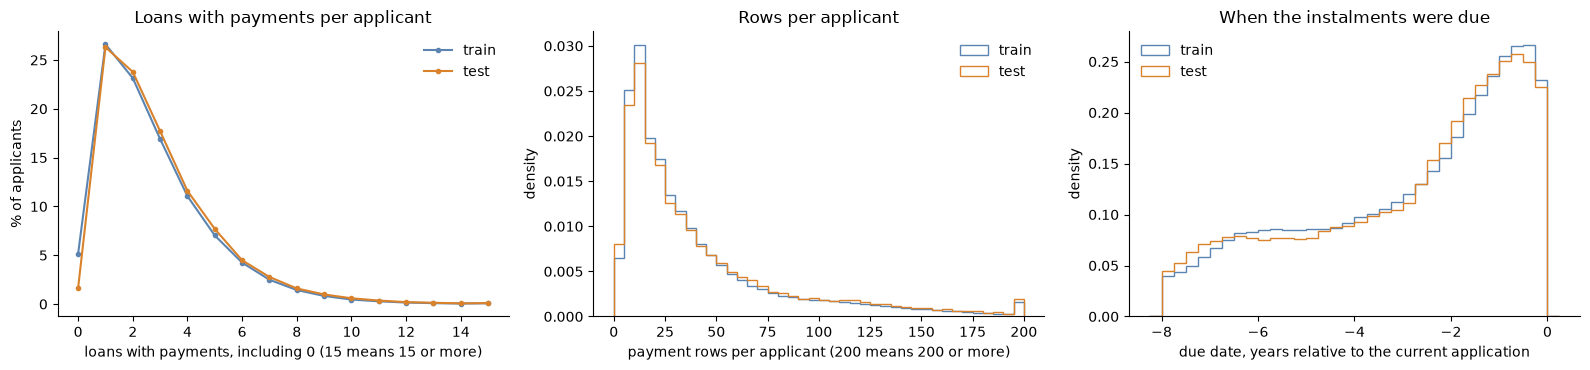

In [6]:
per_applicant = pd.DataFrame({'rows': rows_per_applicant, 'loans': loans_per_applicant,
                              'instalments': inst.drop_duplicates([LOAN, NUMBER]).groupby('SK_ID_CURR').size(),
                              'years_since_first_due': -inst.groupby('SK_ID_CURR')['DAYS_INSTALMENT'].min() / 365.25,
                              'years_since_last_due': -inst.groupby('SK_ID_CURR')['DAYS_INSTALMENT'].max() / 365.25})
known_applicants = per_applicant[per_applicant.index.isin(TRAIN_IDS) | per_applicant.index.isin(TEST_IDS)]
print('applicants with at least one payment on record (train and test):')
print(known_applicants.describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95, 0.99]).T.round(2).to_string())

print('\nper loan:')
print(loans[['rows', 'instalments']].assign(years_from_first_to_last_due=(loans['last_due'] - loans['first_due']) / 365.25).describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95, 0.99]).T.round(2).to_string())
by_type = found.groupby('NAME_CONTRACT_TYPE').agg(loans=('rows', 'size'), rows=('rows', 'sum'), median_rows=('rows', 'median'), median_instalments=('instalments', 'median'), largest=('rows', 'max'))
by_type['pct_of_rows'] = by_type['rows'] / by_type['rows'].sum() * 100
print('\nby contract type of the earlier application:')
print(by_type.round(2).to_string())

print(f"\nearliest due date: {-inst['DAYS_INSTALMENT'].min():,.0f} days before the current application ({-inst['DAYS_INSTALMENT'].min() / 365.25:.1f} years); latest: {inst['DAYS_INSTALMENT'].max():,.0f}")
print(f"earliest payment date: {-inst['DAYS_ENTRY_PAYMENT'].min():,.0f} days before; latest: {inst['DAYS_ENTRY_PAYMENT'].max():,.0f}")

fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
for label, ids, colour in [('train', TRAIN_IDS, '#5b84b1'), ('test', TEST_IDS, '#d9822b')]:
    values = per_applicant['loans'].reindex(ids).fillna(0).clip(upper=15).value_counts(normalize=True).sort_index() * 100
    axes[0].plot(values.index, values.values, marker='o', markersize=3, label=label, color=colour)
    axes[1].hist(per_applicant['rows'].reindex(ids).dropna().clip(upper=200), bins=np.arange(0, 205, 5), density=True, histtype='step', label=label, color=colour)
    axes[2].hist(inst.loc[inst['SK_ID_CURR'].isin(ids), 'DAYS_INSTALMENT'] / 365.25, bins=np.arange(-8.25, 0.26, 0.25), density=True, histtype='step', label=label, color=colour)
axes[0].set_xlabel('loans with payments, including 0 (15 means 15 or more)'); axes[0].set_ylabel('% of applicants'); axes[0].set_title('Loans with payments per applicant'); axes[0].legend(frameon=False)
axes[1].set_xlabel('payment rows per applicant (200 means 200 or more)'); axes[1].set_ylabel('density'); axes[1].set_title('Rows per applicant'); axes[1].legend(frameon=False)
axes[2].set_xlabel('due date, years relative to the current application'); axes[2].set_ylabel('density'); axes[2].set_title('When the instalments were due'); axes[2].legend(frameon=False)
sns.despine(); plt.tight_layout(); plt.show()

### Stage 1 findings

**The table**
- 13,605,401 rows and 8 columns: two keys, two columns that say which instalment, the date and amount due, and the date and amount paid.
- It is complete. The only missing values are the payment date and amount on 2,905 rows (0.02%), always both together. Those are instalments with no payment recorded.
- No row is fully duplicated, and every loan belongs to one applicant.

**One row is one payment towards one instalment**
- An instalment is identified by the loan and the instalment number. There are 12,861,994 of them, and 94.3% have one row.
- The other 5.7% have several rows, up to 12. Where the calendar version is the same on every row, the amount due is repeated on each row and the payments add up to it exactly, in 100.0% of cases. So these are instalments paid in parts, and the amount due must be counted once per instalment and not once per row.
- This settles the unit of behaviour. **Lateness and shortfall belong to the instalment, not to the row.** A feature that counted rows would count one late instalment paid in three parts as three.
- Within a single row, the payment equals the amount due 89.2% of the time, is less 9.5% and more 1.3%. Most of the "less" rows are parts of a split payment and say nothing about underpayment until they are added up.
- For 12% of the instalments with several rows, the rows carry different calendar versions and different amounts due. What that means is a question for stage 3.
- Calendar version 0 marks a credit card, by the dictionary. It is on 30% of rows and 7% of loans. Cards have long histories: a median of 37 rows a loan, against 12 for cash loans and 8 for consumer loans.

**Links**
- Every applicant in the table is in the train or the test file.
- Every loan with payments that is found in `previous_application` is an approved application, with the same applicant recorded in both tables.
- **3.9% of loans with payments are not in `previous_application` at all**, and they hold 9.2% of the rows. They are old: their first instalment was due a median of 2,908 days before the current application, against 873 for the rest. The likely reason is the eight-year window found in notebook 05. An application decided just over eight years ago is outside `previous_application`, while its later instalments are still inside this table's own eight years. The share is the same in train and test (96.2% and 95.7% found). These loans have payments but no known type or terms, and stage 3 decides what to do with them.

**Coverage**
- 94.8% of train applicants and 98.4% of test applicants have a payment on record. That is the same difference notebook 05 found for earlier applications (94.6% and 98.1%), so it comes from the table above and is not new.
- Of approved earlier applications, 92.5% have payments on record: 97% of consumer loans, 92% of cash loans, and only 60% to 65% of revolving loans. A card that was approved and never used has nothing to pay.
- Recent approvals have payments less often (82% within the last year), as expected when the first instalment may not have fallen due.

**Supplied on the same terms in train and test?**
- The supply test gives an AUC of **0.513** on the share of an applicant's approved applications that have payments, and 0.500 on whether any has. `bureau_balance` scored 0.82. The table passes.
- Two smaller differences are worth carrying forward. Revolving loans have payments for 59.9% of test applications and 64.6% of train ones, and approvals one to two years old for 88.8% against 92.5%. Neither is large enough to fail the test, and both point the same way as the shift in running loans that notebook 05 found. Stage 8 checks every feature for shift.

**How much history**
- An applicant with any payment history has a median of 25 rows over 2 loans, and 5% have more than 130 rows.
- The record goes back exactly 8.0 years (2,922 days), the same window as `previous_application`.
- **No due date and no payment date is on or after the day of the current application.** The latest of each is the day before. So the table looks cut at the application date, which is what the features need. That is an observation from two maxima and stage 4 tests it properly, because a table cut this way raises its own question: what happened to instalments that were due before the application and paid after it?
- One oddity for stage 3: the earliest payment date is 4,921 days before the application, although no instalment was due more than 2,922 days before.

**Decisions**
- The unit for payment behaviour is the instalment (loan and instalment number).
- The table goes forward. Stage 2 looks at coverage and outcomes.

## Stage 2: Coverage and target

Do applicants with no payment history default at a different rate? Does the amount of history matter? And how does this table sit beside the two kinds of history the model already has?

**This is the first stage that uses `TARGET`.** Only the 246,008 development applicants are used for anything involving outcomes.

This stage is about how much history there is, not about how the payments went. Whether late payment relates to default is stage 5, after the columns have been audited.

| Section | Question |
|---|---|
| 2.1 | Load the development outcomes |
| 2.2 | Default rate with and without a payment history |
| 2.3 | Default rate by how much history there is |
| 2.4 | Default rate by how recent and how long the history is |
| 2.5 | The three kinds of history together |
| 2.6 | Amount of history in train and test (no target) |

### 2.1 Load the development outcomes

In [7]:
y_dev = pd.read_parquet(f'{PROCESSED}/application_train_features.parquet', columns=['TARGET'])['TARGET'].loc[DEV_IDS]
assert len(y_dev) == 246008 and y_dev.index.equals(DEV_IDS) and len(y_dev.index.intersection(HOLDOUT_IDS)) == 0
BASE_RATE = y_dev.mean()
print(f"development applicants: {len(y_dev):,}; defaults {int(y_dev.sum()):,} ({BASE_RATE:.2%}); holdout outcomes loaded: 0")

def rate_table(groups):
    # default rate of development applicants by group, with a standard error. `groups` is a Series indexed by SK_ID_CURR.
    g = groups.reindex(DEV_IDS)
    t = pd.DataFrame({'applicants': y_dev.groupby(g, observed=True).size(), 'default_pct': y_dev.groupby(g, observed=True).mean() * 100})
    t['pct_of_applicants'] = t['applicants'] / len(y_dev) * 100
    t['standard_error'] = np.sqrt(t['default_pct'] * (100 - t['default_pct']) / t['applicants'])
    t['ratio_to_average'] = t['default_pct'] / (BASE_RATE * 100)
    return t[['applicants', 'pct_of_applicants', 'default_pct', 'standard_error', 'ratio_to_average']]

history = per_applicant.reindex(TRAIN_IDS.union(TEST_IDS))
has_payments = history['rows'].notna()

development applicants: 246,008; defaults 19,860 (8.07%); holdout outcomes loaded: 0


### 2.2 With and without a payment history

In [8]:
prev_train = pd.read_parquet(f'{PROCESSED}/previous_train_features.parquet', columns=['PREV_N_APPLICATIONS', 'PREV_N_APPROVED', 'PREV_N_REFUSED'])
bureau_train = pd.read_parquet(f'{PROCESSED}/bureau_train_features.parquet', columns=['BUREAU_N_CREDITS'])
assert prev_train.index.equals(TRAIN_IDS) and bureau_train.index.equals(TRAIN_IDS)

print(rate_table(has_payments.map({True: 'has a payment history', False: 'no payment history'})).to_string(float_format=lambda v: f'{v:,.2f}'))

kind = pd.Series('no earlier application', index=TRAIN_IDS)
kind[(prev_train['PREV_N_APPLICATIONS'] > 0).values] = 'earlier applications, none approved'
kind[(prev_train['PREV_N_APPROVED'] > 0).values] = 'an approved application, no payments on record'
kind[has_payments.reindex(TRAIN_IDS).values] = 'has a payment history'
print('\nwho the applicants without a payment history are:')
print(rate_table(kind).to_string(float_format=lambda v: f'{v:,.2f}'))
odd = has_payments.reindex(TRAIN_IDS).values & ~(prev_train['PREV_N_APPROVED'] > 0).values
print(f"\ntrain applicants with payments on record but no approved application in previous_application: {int(odd.sum()):,} ({odd.mean():.2%}) "
      '(their loans are the ones stage 1 could not find)')

                       applicants  pct_of_applicants  default_pct  standard_error  ratio_to_average
rows                                                                                               
has a payment history      233322              94.84         8.19            0.06              1.01
no payment history          12686               5.16         5.98            0.21              0.74

who the applicants without a payment history are:
                                                applicants  pct_of_applicants  default_pct  standard_error  ratio_to_average
an approved application, no payments on record         345               0.14         8.99            1.54              1.11
earlier applications, none approved                    400               0.16         7.75            1.34              0.96
has a payment history                               233322              94.84         8.19            0.06              1.01
no earlier application                           

### 2.3 By how much history there is

In [9]:
cut = lambda s, edges, labels: pd.cut(s, edges, labels=labels, right=True)
loans_band = cut(history['loans'], [0, 1, 2, 3, 5, 8, np.inf], ['1 loan', '2', '3', '4 to 5', '6 to 8', '9 or more'])
inst_band = cut(history['instalments'], [0, 6, 12, 24, 48, 96, np.inf], ['1 to 6', '7 to 12', '13 to 24', '25 to 48', '49 to 96', 'over 96'])
print('by number of loans with payments:')
print(rate_table(loans_band).to_string(float_format=lambda v: f'{v:,.2f}'))
print('\nby number of instalments on record:')
print(rate_table(inst_band).to_string(float_format=lambda v: f'{v:,.2f}'))

dev_history = history.reindex(DEV_IDS)
ok = dev_history['rows'].notna().values
for c in ['loans', 'instalments', 'rows']:
    a = roc_auc_score(y_dev.values[ok], dev_history[c].values[ok])
    print(f"AUC of the number of {c} alone, among applicants with a history: {max(a, 1 - a):.4f} ({'more history, more risk' if a > 0.5 else 'more history, less risk'})")

by number of loans with payments:


           applicants  pct_of_applicants  default_pct  standard_error  ratio_to_average
loans                                                                                  
1 loan          65403              26.59         9.47            0.11              1.17
2               56925              23.14         8.47            0.12              1.05
3               41614              16.92         7.79            0.13              0.97
4 to 5          44505              18.09         7.03            0.12              0.87
6 to 8          20120               8.18         6.77            0.18              0.84
9 or more        4755               1.93         7.38            0.38              0.91

by number of instalments on record:
             applicants  pct_of_applicants  default_pct  standard_error  ratio_to_average
instalments                                                                              
1 to 6            23644               9.61         8.62            0.18        

AUC of the number of instalments alone, among applicants with a history: 0.5264 (more history, less risk)
AUC of the number of rows alone, among applicants with a history: 0.5213 (more history, less risk)


### 2.4 By how recent and how long the history is

by when the most recent instalment was due:


                      applicants  pct_of_applicants  default_pct  standard_error  ratio_to_average
years_since_last_due                                                                              
within 30 days            101639              41.32         8.34            0.09              1.03
31 to 90                   26216              10.66         7.22            0.16              0.89
91 to 365                  46012              18.70         8.36            0.13              1.04
1 to 2 years               27814              11.31         8.26            0.17              1.02
2 to 4 years               16971               6.90         7.88            0.21              0.98
over 4 years               14670               5.96         8.53            0.23              1.06

by when the first instalment on record was due:


                         applicants  pct_of_applicants  default_pct  standard_error  ratio_to_average
years_since_first_due                                                                                
under 1 year                  20331               8.26        10.51            0.22              1.30
1 to 2                        39411              16.02        10.33            0.15              1.28
2 to 4                        51410              20.90         8.67            0.12              1.07
4 to 6                        42613              17.32         7.61            0.13              0.94
6 to 7.9                      56219              22.85         6.79            0.11              0.84
reaches the window edge       23338               9.49         5.90            0.15              0.73
AUC of years_since_last_due alone: 0.5032 (further back, less risk)
AUC of years_since_first_due alone: 0.5598 (further back, less risk)


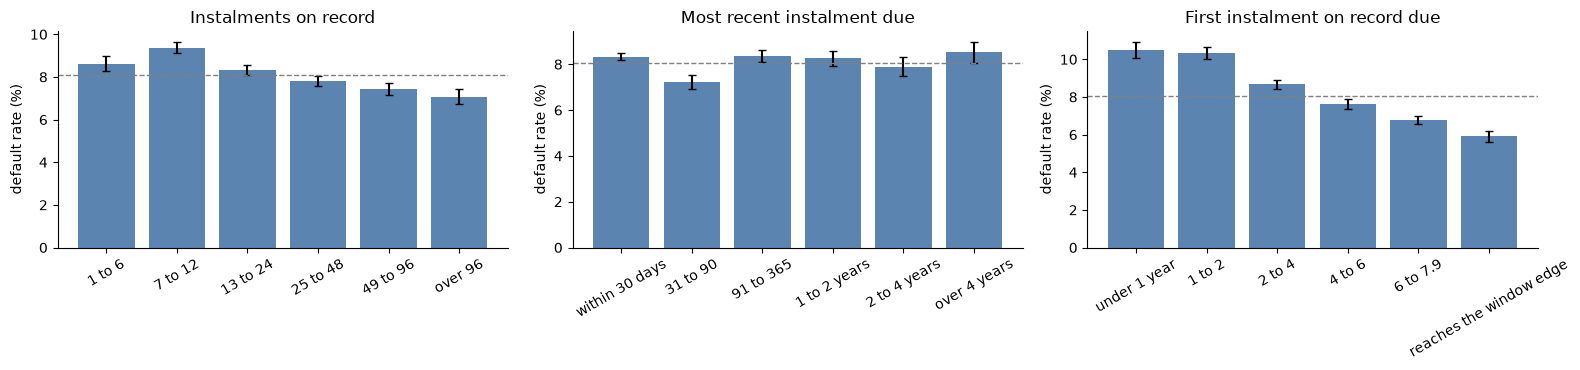

In [10]:
last_band = cut(history['years_since_last_due'] * 365.25, [-1, 30, 90, 365, 730, 1461, np.inf], ['within 30 days', '31 to 90', '91 to 365', '1 to 2 years', '2 to 4 years', 'over 4 years'])
first_band = cut(history['years_since_first_due'], [0, 1, 2, 4, 6, 7.9, np.inf], ['under 1 year', '1 to 2', '2 to 4', '4 to 6', '6 to 7.9', 'reaches the window edge'])
print('by when the most recent instalment was due:')
print(rate_table(last_band).to_string(float_format=lambda v: f'{v:,.2f}'))
print('\nby when the first instalment on record was due:')
print(rate_table(first_band).to_string(float_format=lambda v: f'{v:,.2f}'))
for c in ['years_since_last_due', 'years_since_first_due']:
    a = roc_auc_score(y_dev.values[ok], dev_history[c].values[ok])
    print(f"AUC of {c} alone: {max(a, 1 - a):.4f} ({'further back, more risk' if a > 0.5 else 'further back, less risk'})")

fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
for ax, band, title in [(axes[0], inst_band, 'Instalments on record'), (axes[1], last_band, 'Most recent instalment due'), (axes[2], first_band, 'First instalment on record due')]:
    t = rate_table(band)
    ax.bar(t.index.astype(str), t['default_pct'], yerr=2 * t['standard_error'], color='#5b84b1', capsize=3)
    ax.axhline(BASE_RATE * 100, color='grey', linestyle='--', linewidth=1)
    ax.set_title(title); ax.set_ylabel('default rate (%)'); ax.tick_params(axis='x', rotation=30)
sns.despine(); plt.tight_layout(); plt.show()

### 2.5 The three kinds of history together

The model already knows whether an applicant has a bureau record and an earlier application. Does knowing they have a payment history add anything to that?

In [11]:
three = pd.DataFrame({'bureau record': (bureau_train['BUREAU_N_CREDITS'] > 0).map({True: 'bureau', False: 'no bureau'}),
                      'earlier application': (prev_train['PREV_N_APPLICATIONS'] > 0).map({True: 'earlier application', False: 'no earlier application'}),
                      'payment history': has_payments.reindex(TRAIN_IDS).map({True: 'payments', False: 'no payments'})})
combined = three['bureau record'] + ' / ' + three['earlier application'] + ' / ' + three['payment history']
print(rate_table(combined).sort_values('applicants', ascending=False).to_string(float_format=lambda v: f'{v:,.2f}'))

with_prev = (prev_train['PREV_N_APPLICATIONS'] > 0)
inside = rate_table(has_payments.reindex(TRAIN_IDS).map({True: 'payments', False: 'no payments'}).where(with_prev))
print('\namong applicants who have an earlier application:')
print(inside.to_string(float_format=lambda v: f'{v:,.2f}'))
gap = inside.loc['no payments', 'default_pct'] - inside.loc['payments', 'default_pct']
gap_se = np.sqrt(inside.loc['no payments', 'standard_error'] ** 2 + inside.loc['payments', 'standard_error'] ** 2)
print(f"difference: {gap:+.2f} points (standard error {gap_se:.2f})")
no_pay = with_prev & ~has_payments.reindex(TRAIN_IDS)
print(f"\nthose with an earlier application and no payments: {(prev_train.loc[no_pay, 'PREV_N_APPROVED'] == 0).mean():.1%} have no approved application; "
      f"{(prev_train.loc[no_pay, 'PREV_N_REFUSED'] > 0).mean():.1%} have a refusal (among those with payments: {(prev_train.loc[with_prev & ~no_pay, 'PREV_N_REFUSED'] > 0).mean():.1%})")

                                                  applicants  pct_of_applicants  default_pct  standard_error  ratio_to_average
bureau / earlier application / payments               198938              80.87         7.84            0.06              0.97
no bureau / earlier application / payments             33151              13.48        10.28            0.17              1.27
bureau / no earlier application / no payments          10148               4.13         5.58            0.23              0.69
no bureau / no earlier application / no payments        1793               0.73         7.31            0.61              0.91
bureau / no earlier application / payments              1042               0.42         7.68            0.82              0.95
bureau / earlier application / no payments               636               0.26         7.70            1.06              0.95
no bureau / no earlier application / payments            191               0.08         7.33            1.89   

### 2.6 Amount of history in train and test

No target is used here. If test applicants have systematically more or less payment history, features that count it will be distributed differently in the test file.

In [12]:
def psi(a, b):
    a, b = np.clip(a, 1e-6, None), np.clip(b, 1e-6, None)
    return float(((a - b) * np.log(a / b)).sum())

bands = {'loans with payments': loans_band, 'instalments on record': inst_band, 'most recent instalment due': last_band, 'first instalment on record due': first_band}
summary = {}
for label, band in bands.items():
    shares = pd.DataFrame({'train': band.reindex(TRAIN_IDS).value_counts(normalize=True, dropna=True), 'test': band.reindex(TEST_IDS).value_counts(normalize=True, dropna=True)}).sort_index() * 100
    print(f"\n{label} (% of applicants with a payment history):")
    print(shares.round(2).T.to_string())
    column = {'loans with payments': 'loans', 'instalments on record': 'instalments', 'most recent instalment due': 'years_since_last_due', 'first instalment on record due': 'years_since_first_due'}[label]
    both = pd.concat([history[column].reindex(TRAIN_IDS).dropna(), history[column].reindex(TEST_IDS).dropna()])
    is_test = both.index.isin(TEST_IDS).astype(int)
    a = roc_auc_score(is_test, both.values)
    summary[label] = {'PSI': psi(shares['train'].values / 100, shares['test'].values / 100), 'shift AUC': max(a, 1 - a), 'median, train': history[column].reindex(TRAIN_IDS).median(), 'median, test': history[column].reindex(TEST_IDS).median()}
print()
print(pd.DataFrame(summary).T.to_string(float_format=lambda v: f'{v:.3f}'))
print(f"\nwith any payment history: train {has_payments.reindex(TRAIN_IDS).mean():.2%}, test {has_payments.reindex(TEST_IDS).mean():.2%}")


loans with payments (% of applicants with a payment history):
loans  1 loan      2      3  4 to 5  6 to 8  9 or more
train   28.05  24.40  17.82   19.06    8.61       2.05
test    26.75  24.18  18.00   19.60    9.00       2.47

instalments on record (% of applicants with a payment history):
instalments  1 to 6  7 to 12  13 to 24  25 to 48  49 to 96  over 96
train         10.16    19.09     23.00     23.68     14.66     9.40
test          10.61    17.57     22.04     23.12     16.08    10.59



most recent instalment due (% of applicants with a payment history):
years_since_last_due  within 30 days  31 to 90  91 to 365  1 to 2 years  2 to 4 years  over 4 years
train                          43.57     11.27      19.74         11.84          7.27          6.31
test                           45.40      8.73      19.40         13.66          6.48          6.33



first instalment on record due (% of applicants with a payment history):
years_since_first_due  under 1 year  1 to 2  2 to 4  4 to 6  6 to 7.9  reaches the window edge
train                          8.75   16.96   21.93   18.28      24.1                     9.99
test                           6.79   18.24   22.60   17.38      23.7                    11.29

                                 PSI  shift AUC  median, train  median, test
loans with payments            0.002      0.511          2.000         2.000
instalments on record          0.005      0.513         24.000        24.000
most recent instalment due     0.011      0.505          0.134         0.120
first instalment on record due 0.008      0.511          4.214         4.304

with any payment history: train 94.84%, test 98.36%


### Stage 2 findings

**Having a payment history is the same fact as having an earlier application**
- 94.8% of development applicants have a payment history and default at 8.19%. The 5.2% without one default at 5.98%.
- That gap is not about payments. Of the 12,686 applicants without a payment history, 11,941 have no earlier application at all, and they default at 5.84%, as notebook 05 found. Only 745 have an earlier application and no payments.
- Among applicants who do have an earlier application, those with and without payments default at 8.19% and 8.32%. The difference is 0.13 points with a standard error of 1.01, which is nothing.
- So whether a payment history exists adds nothing to what the model already knows. Whatever this table is worth will come from what the payments say, not from their presence.
- 2,012 train applicants (0.65%) have payments on record and no approved application in `previous_application`. Their loans are the old ones stage 1 could not find.

**More history goes with less risk, mildly**

| Loans with payments | Default rate | | Instalments on record | Default rate |
|---|---:|---|---|---:|
| 1 | 9.47% | | 7 to 12 | 9.38% |
| 2 | 8.47% | | 13 to 24 | 8.33% |
| 3 | 7.79% | | 25 to 48 | 7.80% |
| 4 to 5 | 7.03% | | 49 to 96 | 7.44% |
| 6 to 8 | 6.77% | | over 96 | 7.07% |

- Alone, the number of loans scores 0.536 and the number of instalments 0.526. An applicant who has been lent to repeatedly has passed several earlier approvals, so this is partly Home Credit's own selection again.
- The model already has the number of approved applications and of loans ended from notebook 05, so little of this will be new.

**How long the history goes back matters more than how recent it is**
- Applicants whose first instalment on record was due under two years ago default at 10.4%. Those whose record reaches the edge of the eight-year window default at 5.9%. Alone this scores 0.560.
- This is the length of the relationship, which notebook 05 measured from the first decision (`PREV_DAYS_SINCE_FIRST_DECISION`, kept in the model). It is the same fact seen through a different table, and stage 8 will test whether it is redundant.
- When the most recent instalment was due says almost nothing (0.503).

**Train and test have the same amount of history**
- For the four measures of amount and timing, PSI is between 0.002 and 0.011 and the shift AUC between 0.505 and 0.513. Nothing is flagged.
- The one difference remains the share with any history: 94.8% in train and 98.4% in test.

**What this stage did not look at**
- Whether payments were late or short. That needs the columns audited first.

**Decisions**
- No feature will be built for the mere presence of a payment history.
- Counts of loans and instalments are candidates of low priority, to be tested for redundancy with notebook 05's features.

## Stage 3: Column-by-column audit

What is wrong with each column, and what should be done about it before any feature is built?

As before, every column is asked two questions: is the value believable, and is it supplied on the same terms in train and test? This table needs a third, because its meaning lies in the difference between columns. A late payment is a payment date after a due date. A short payment is an amount paid below an amount due. So the audit has to look at the pairs as well as the columns.

**No target is used in this stage.**

| Section | What it covers |
|---|---|
| 3.1 | Instalments with no payment recorded |
| 3.2 | Amounts due and paid |
| 3.3 | Due dates and payment dates |
| 3.4 | Calendar versions, and credit cards |
| 3.5 | Instalment numbers: gaps and missing starts |
| 3.6 | Is each fact supplied equally in train and test? |
| 3.7 | The cleaning rules, as one function |

### 3.1 Instalments with no payment recorded

2,905 rows have an amount due and no payment. An unpaid instalment is the most serious thing this table can say about an applicant, so it matters what these rows are.

In [13]:
del prev_raw
loan_type = inst[LOAN].map(prev_ids['NAME_CONTRACT_TYPE']).fillna('not in previous_application')
inst_part = inst['SK_ID_CURR'].map(part_of)
unpaid = inst['DAYS_ENTRY_PAYMENT'].isna()
print(f"rows with no payment: {int(unpaid.sum()):,} ({unpaid.mean():.3%}), on {inst.loc[unpaid, LOAN].nunique():,} loans of {inst.loc[unpaid, 'SK_ID_CURR'].nunique():,} applicants")
print('by part (% of each part\'s rows):', (unpaid.groupby(inst_part).mean() * 100).round(4).to_dict())
print('by loan type (% of rows):', (unpaid.groupby(loan_type).mean() * 100).round(4).to_dict())

due_band = pd.cut(-inst['DAYS_INSTALMENT'], [0, 7, 30, 90, 365, 730, 3000], labels=['within 7 days', '8 to 30', '31 to 90', '91 to 365', '1 to 2 years', 'over 2 years'])
when = pd.DataFrame({'unpaid rows': due_band[unpaid].value_counts(), 'all rows': due_band.value_counts()})
when['unpaid_pct_of_band'] = when['unpaid rows'] / when['all rows'] * 100
when['share_of_unpaid_pct'] = when['unpaid rows'] / when['unpaid rows'].sum() * 100
print('\nby how long before the application the instalment was due:')
print(when.sort_index().round(4).to_string())

# is the unpaid row the only row of its instalment, and is it the last instalment on record for the loan?
keys = inst.loc[unpaid, [LOAN, NUMBER]].drop_duplicates()
same_instalment = inst.merge(keys, on=[LOAN, NUMBER])
rows_of = same_instalment.groupby([LOAN, NUMBER]).agg(rows=('AMT_INSTALMENT', 'size'), paid_rows=('AMT_PAYMENT', 'count'), due=('AMT_INSTALMENT', 'max'), paid=('AMT_PAYMENT', 'sum'))
print(f"\ninstalments with an unpaid row: {len(rows_of):,}; where it is the only row: {(rows_of['rows'] == 1).mean():.1%}; where other rows show a payment: {(rows_of['paid_rows'] > 0).mean():.1%}")
last_number = inst.groupby(LOAN)[NUMBER].max()
last_due = inst.groupby(LOAN)['DAYS_INSTALMENT'].max()
u = inst.loc[unpaid, [LOAN, NUMBER, 'DAYS_INSTALMENT', 'AMT_INSTALMENT']]
print(f"unpaid rows that are the last instalment number on record for their loan: {(u[NUMBER].values == last_number.reindex(u[LOAN]).values).mean():.1%}; "
      f"with the loan's latest due date: {(u['DAYS_INSTALMENT'].values == last_due.reindex(u[LOAN]).values).mean():.1%}")
per_loan_unpaid = unpaid.groupby(inst[LOAN]).sum()
print(f"unpaid rows per affected loan: {per_loan_unpaid[per_loan_unpaid > 0].describe(percentiles=[0.5, 0.9, 0.99]).round(1).to_dict()}")
print(f"amount due on unpaid rows: median {u['AMT_INSTALMENT'].median():,.0f}; on all rows {inst['AMT_INSTALMENT'].median():,.0f}; unpaid rows with an amount due of zero: {(u['AMT_INSTALMENT'] == 0).mean():.1%}")

rows with no payment: 2,905 (0.021%), on 1,344 loans of 1,249 applicants


by part (% of each part's rows): {'test': 0.016, 'train: development': 0.0225, 'train: holdout': 0.0213}


by loan type (% of rows): {'Cash loans': 0.0224, 'Consumer loans': 0.0057, 'Revolving loans': 0.0433, 'not in previous_application': 0.0352}



by how long before the application the instalment was due:
                 unpaid rows  all rows  unpaid_pct_of_band  share_of_unpaid_pct
DAYS_INSTALMENT                                                                
within 7 days            250     31296              0.7988               8.6059
8 to 30                  372    190526              0.1952              12.8055
31 to 90                 343    552431              0.0621              11.8072
91 to 365                406   2672007              0.0152              13.9759
1 to 2 years             208   2838839              0.0073               7.1601
over 2 years            1326   7320302              0.0181              45.6454



instalments with an unpaid row: 2,891; where it is the only row: 99.5%; where other rows show a payment: 0.0%


unpaid rows that are the last instalment number on record for their loan: 44.2%; with the loan's latest due date: 45.2%


unpaid rows per affected loan: {'count': 1344.0, 'mean': 2.2, 'std': 3.3, 'min': 1.0, '50%': 1.0, '90%': 4.0, '99%': 13.1, 'max': 57.0}
amount due on unpaid rows: median 109; on all rows 8,884; unpaid rows with an amount due of zero: 1.5%


The unpaid rows are concentrated in two places: the last week before the application, and more than two years back. Those may not be the same thing.

In [14]:
u = inst[unpaid]
recent, old = u['DAYS_INSTALMENT'] >= -30, u['DAYS_INSTALMENT'] < -730
kinds = pd.DataFrame({label: {'rows': int(m.sum()), 'on a card (version 0) %': (u.loc[m, VERSION] == 0).mean() * 100, 'median amount due': u.loc[m, 'AMT_INSTALMENT'].median(),
                              'amount due under 200 %': (u.loc[m, 'AMT_INSTALMENT'] < 200).mean() * 100, 'applicants': u.loc[m, 'SK_ID_CURR'].nunique()}
                      for label, m in [('due within 30 days of the application', recent), ('due 31 days to 2 years before', ~recent & ~old), ('due more than 2 years before', old)]}).T
print(kinds.to_string(float_format=lambda v: f'{v:,.1f}'))

# how many instalments are on record at all, by how close to the application they fell due?
close = pd.cut(-inst['DAYS_INSTALMENT'], [0, 5, 10, 15, 20, 25, 30, 60, 90], labels=['1 to 5', '6 to 10', '11 to 15', '16 to 20', '21 to 25', '26 to 30', '31 to 60', '61 to 90'])
per_day = (close.value_counts().sort_index() / pd.Series([5, 5, 5, 5, 5, 5, 30, 30], index=close.cat.categories)).round(0)
print('\nrows on record per day of due date, by days before the application:')
print(per_day.astype(int).to_string())

                                         rows  on a card (version 0) %  median amount due  amount due under 200 %  applicants
due within 30 days of the application   622.0                     29.6           11,249.5                    15.4       530.0
due 31 days to 2 years before           957.0                     29.9           14,179.2                    29.6       366.0
due more than 2 years before          1,326.0                     93.3               67.5                    92.8       472.0



rows on record per day of due date, by days before the application:
DAYS_INSTALMENT
1 to 5      3595
6 to 10     6762
11 to 15    7474
16 to 20    8063
21 to 25    8763
26 to 30    9707
31 to 60    9016
61 to 90    9399


### 3.2 Amounts due and paid

In [15]:
amounts = pd.DataFrame({c: inst[c].describe(percentiles=[0.001, 0.01, 0.25, 0.5, 0.75, 0.99, 0.999]) for c in ['AMT_INSTALMENT', 'AMT_PAYMENT']}).T
print(amounts.to_string(float_format=lambda v: f'{v:,.2f}'))
zero_due, zero_paid = inst['AMT_INSTALMENT'] == 0, inst['AMT_PAYMENT'] == 0
print(f"\nrows with an amount due of zero: {int(zero_due.sum()):,} ({zero_due.mean():.4%}); with a payment of zero: {int(zero_paid.sum()):,} ({zero_paid.mean():.4%}); both: {int((zero_due & zero_paid).sum()):,}")
print('amount due of zero, by loan type (% of rows):', (zero_due.groupby(loan_type).mean() * 100).round(4).to_dict())
tiny = (inst['AMT_INSTALMENT'] > 0) & (inst['AMT_INSTALMENT'] < 100)
print(f"amount due above zero and under 100: {int(tiny.sum()):,} ({tiny.mean():.3%}); by loan type (%): {(tiny.groupby(loan_type).mean() * 100).round(3).to_dict()}")
print(f"negative amounts: {int((inst[['AMT_INSTALMENT', 'AMT_PAYMENT']] < 0).any(axis=1).sum())}")

# the amount due on a loan's instalments: constant, or changing?
regular = inst[inst[VERSION] > 0]
per_loan_amount = regular.groupby(LOAN)['AMT_INSTALMENT'].agg(['nunique', 'median', 'max', 'size'])
print(f"\nloans other than cards: distinct amounts due per loan: median {per_loan_amount['nunique'].median():.0f}; exactly one amount {(per_loan_amount['nunique'] == 1).mean():.1%}; one or two {(per_loan_amount['nunique'] <= 2).mean():.1%}")
big = per_loan_amount['max'] > 3 * per_loan_amount['median']
print(f"loans where the largest amount due is more than three times the usual one: {big.mean():.1%} (an early repayment of the balance would look like this)")

# at the level of the instalment: was it paid in full?
g = inst.groupby([LOAN, NUMBER], sort=False)
instalment = pd.DataFrame({'rows': g.size(), 'versions': g[VERSION].nunique(), 'due_max': g['AMT_INSTALMENT'].max(), 'due_min': g['AMT_INSTALMENT'].min(),
                           'paid': g['AMT_PAYMENT'].sum(min_count=1), 'due_date': g['DAYS_INSTALMENT'].max(), 'due_dates': g['DAYS_INSTALMENT'].nunique(),
                           'first_payment': g['DAYS_ENTRY_PAYMENT'].min(), 'last_payment': g['DAYS_ENTRY_PAYMENT'].max(), 'version_min': g[VERSION].min()})
print(f"\ninstalments: {len(instalment):,}")
one_version = instalment['versions'] == 1
gap = (instalment['paid'].fillna(0) - instalment['due_max'])
status = pd.Series(np.select([instalment['paid'].isna(), gap.abs() < 0.01, gap < 0, gap > 0], ['no payment at all', 'paid exactly', 'paid less', 'paid more'], default='?'), index=instalment.index)
print('instalments with one calendar version, total paid against the amount due (%):')
print((status[one_version].value_counts(normalize=True) * 100).round(3).to_string())
short = one_version & (status == 'paid less')
print(f"\nwhere less was paid: share of the amount due that was paid, quartiles {(instalment.loc[short, 'paid'] / instalment.loc[short, 'due_max']).quantile([0.1, 0.25, 0.5, 0.75, 0.9]).round(3).to_dict()}")
print(f"   shortfall under 1.00 in money: {(-gap[short] < 1).mean():.1%}; under 1% of the amount due: {((-gap[short]) / instalment.loc[short, 'due_max'] < 0.01).mean():.1%}")
card_instalment = instalment['version_min'] == 0
print(f"   on cards (version 0): {(status[one_version & card_instalment] == 'paid less').mean():.2%} of instalments paid less; on other loans: {(status[one_version & ~card_instalment] == 'paid less').mean():.2%}")

                       count      mean       std  min  0.1%    1%      25%      50%       75%        99%      99.9%          max
AMT_INSTALMENT 13,605,401.00 17,050.91 50,570.25 0.00  0.45 13.28 4,226.09 8,884.08 16,710.21 146,068.70 790,314.34 3,771,487.85
AMT_PAYMENT    13,602,496.00 17,238.22 54,735.78 0.00  0.18  3.78 3,398.26 8,125.52 16,108.42 178,003.96 852,835.57 3,771,487.85

rows with an amount due of zero: 290 (0.0021%); with a payment of zero: 1,440 (0.0106%); both: 2


amount due of zero, by loan type (% of rows): {'Cash loans': 0.0003, 'Consumer loans': 0.0035, 'Revolving loans': 0.0009, 'not in previous_application': 0.0044}


amount due above zero and under 100: 409,404 (3.009%); by loan type (%): {'Cash loans': 0.018, 'Consumer loans': 0.016, 'Revolving loans': 9.941, 'not in previous_application': 8.797}
negative amounts: 0



loans other than cards: distinct amounts due per loan: median 2; exactly one amount 14.4%; one or two 92.3%
loans where the largest amount due is more than three times the usual one: 24.1% (an early repayment of the balance would look like this)



instalments: 12,861,994


instalments with one calendar version, total paid against the amount due (%):


paid exactly         99.953
paid less             0.023
no payment at all     0.023
paid more             0.002

where less was paid: share of the amount due that was paid, quartiles {0.1: 0.015, 0.25: 0.081, 0.5: 0.547, 0.75: 0.983, 0.9: 0.999}
   shortfall under 1.00 in money: 4.4%; under 1% of the amount due: 21.3%


   on cards (version 0): 0.02% of instalments paid less; on other loans: 0.02%


1,440 rows record a payment of exactly zero, with a payment date. What are they?

In [16]:
zero_rows = inst[zero_paid]
zero_instalments = instalment.reindex(pd.MultiIndex.from_frame(zero_rows[[LOAN, NUMBER]].drop_duplicates()))
print(f"rows with a payment of zero: {len(zero_rows):,}; on cards: {(zero_rows[VERSION] == 0).mean():.1%}")
print(f"their instalments: {len(zero_instalments):,}; with other rows as well: {(zero_instalments['rows'] > 1).mean():.2%}; whose other payments add up to the amount due exactly: {(np.abs(zero_instalments['paid'] - zero_instalments['due_max']) < 0.01).mean():.2%}")
print(f"instalments whose only payment is zero: {int((zero_instalments['paid'] == 0).sum())}")
example = zero_rows.iloc[0]
print('\none of them, with the rest of its instalment:')
print(inst[(inst[LOAN] == example[LOAN]) & (inst[NUMBER] == example[NUMBER])].to_string(index=False))

rows with a payment of zero: 1,440; on cards: 99.9%
their instalments: 1,438; with other rows as well: 99.86%; whose other payments add up to the amount due exactly: 100.00%
instalments whose only payment is zero: 2

one of them, with the rest of its instalment:
 SK_ID_PREV  SK_ID_CURR  NUM_INSTALMENT_VERSION  NUM_INSTALMENT_NUMBER  DAYS_INSTALMENT  DAYS_ENTRY_PAYMENT  AMT_INSTALMENT  AMT_PAYMENT
    1514613      197031                     0.0                     10          -2165.0             -2191.0          4500.0          0.0
    1514613      197031                     0.0                     10          -2165.0             -2163.0          4500.0       4500.0


### 3.3 Due dates and payment dates

Lateness is the payment date minus the due date. A positive number is a late payment.

In [17]:
days_late = inst['DAYS_ENTRY_PAYMENT'] - inst['DAYS_INSTALMENT']
print('payment date minus due date, per row (days; positive is late):')
print(days_late.describe(percentiles=[0.001, 0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99, 0.999]).round(1).to_string())
bands = pd.cut(days_late, [-np.inf, -365, -30, -1, 0, 5, 30, 90, 365, np.inf], labels=['over a year early', '31 to 365 early', '1 to 30 early', 'on the day', '1 to 5 late', '6 to 30 late', '31 to 90 late', '91 to 365 late', 'over a year late'])
table = pd.DataFrame({'rows': bands.value_counts().sort_index(), 'pct': bands.value_counts(normalize=True).sort_index() * 100})
for t in ['Cash loans', 'Consumer loans', 'Revolving loans', 'not in previous_application']:
    table[t] = bands[loan_type == t].value_counts(normalize=True).sort_index() * 100
print()
print(table.round(3).to_string())

very_early = days_late < -365
print(f"\nrows paid more than a year before the due date: {int(very_early.sum()):,}; on {inst.loc[very_early, LOAN].nunique():,} loans")
print(f"   their payment dates: {inst.loc[very_early, 'DAYS_ENTRY_PAYMENT'].describe()[['min', '50%', 'max']].round(0).to_dict()}; their due dates: {inst.loc[very_early, 'DAYS_INSTALMENT'].describe()[['min', '50%', 'max']].round(0).to_dict()}")
print(f"   payment dates earlier than the 8-year window (before day -2,922): {int((inst['DAYS_ENTRY_PAYMENT'] < -2922).sum()):,} rows; all of them more than a year early: {bool(very_early[inst['DAYS_ENTRY_PAYMENT'] < -2922].all())}")
example_loan = inst.loc[very_early, LOAN].value_counts().index[0]
print('\na loan with payments recorded long before the due dates (first 8 rows by instalment number):')
print(inst[inst[LOAN] == example_loan].sort_values([NUMBER, 'DAYS_ENTRY_PAYMENT']).head(8).to_string(index=False))

very_late = days_late > 365
print(f"\nrows paid more than a year after the due date: {int(very_late.sum()):,}; largest delay {days_late.max():,.0f} days")
print(f"due dates: earliest {inst['DAYS_INSTALMENT'].min():,.0f}, latest {inst['DAYS_INSTALMENT'].max():,.0f}; payment dates: earliest {inst['DAYS_ENTRY_PAYMENT'].min():,.0f}, latest {inst['DAYS_ENTRY_PAYMENT'].max():,.0f}")

# within a loan, are due dates a month apart?
ordered = instalment.reset_index().sort_values([LOAN, NUMBER])
step = ordered.groupby(LOAN)['due_date'].diff()
number_step = ordered.groupby(LOAN)[NUMBER].diff()
consecutive = number_step == 1
print(f"\ndays between the due dates of consecutive instalments: {step[consecutive].describe(percentiles=[0.01, 0.05, 0.5, 0.95, 0.99]).round(1).to_dict()}")
print(f"   between 28 and 31 days: {step[consecutive].between(28, 31).mean():.1%}; zero or negative: {(step[consecutive] <= 0).mean():.2%}")
is_card_loan = ordered[LOAN].map(instalment.groupby(level=0)['version_min'].min() == 0)
print(f"   between 28 and 31 days, cards: {step[consecutive & is_card_loan].between(28, 31).mean():.1%}; other loans: {step[consecutive & ~is_card_loan].between(28, 31).mean():.1%}")

payment date minus due date, per row (days; positive is late):


count    13602496.0
mean           -8.8
std            25.5
min         -3189.0
0.1%         -135.0
1%            -60.0
5%            -31.0
25%           -14.0
50%            -6.0
75%             0.0
95%             3.0
99%            18.0
99.9%          80.0
max          2884.0



                      rows     pct  Cash loans  Consumer loans  Revolving loans  not in previous_application
over a year early      396   0.003       0.005           0.004            0.000                        0.001
31 to 365 early     933831   6.865       7.770          10.688            0.712                        1.798
1 to 30 early      8375250  61.571      72.647          75.040           34.570                       32.646
on the day         3146350  23.131       8.002           5.420           59.784                       60.123
1 to 5 late         705134   5.184       8.234           4.940            2.934                        2.448
6 to 30 late        402893   2.962       3.123           3.553            1.814                        2.585
31 to 90 late        25904   0.190       0.163           0.247            0.105                        0.228
91 to 365 late        7852   0.058       0.052           0.072            0.038                        0.060
over a year late  

due dates: earliest -2,922, latest -1; payment dates: earliest -4,921, latest -1



days between the due dates of consecutive instalments: {'count': 11844036.0, 'mean': 27.0, 'std': 14.1, 'min': -1681.0, '1%': -19.0, '5%': -6.0, '50%': 30.0, '95%': 34.0, '99%': 48.0, 'max': 2852.0}


   between 28 and 31 days: 82.4%; zero or negative: 7.97%


   between 28 and 31 days, cards: 47.4%; other loans: 99.8%


### 3.4 Calendar versions, and credit cards

The dictionary says version 0 is a credit card, and that a change of version means the payment calendar changed. Two things need checking: that version 0 really is the revolving loans of `previous_application`, and what it means when one instalment carries more than one version.

In [18]:
print('rows by calendar version and loan type (% of each loan type\'s rows):')
version_band = pd.cut(inst[VERSION], [-1, 0, 1, 2, 5, 1000], labels=['0', '1', '2', '3 to 5', '6 or more'])
print((pd.crosstab(loan_type, version_band, normalize='index') * 100).round(2).to_string())
loan_versions = inst.groupby(LOAN)[VERSION].agg(['min', 'max', 'nunique'])
loan_versions['type'] = prev_ids['NAME_CONTRACT_TYPE'].reindex(loan_versions.index).fillna('not in previous_application').values
loan_versions['kind'] = np.select([loan_versions['max'] == 0, loan_versions['min'] == 0], ['version 0 only', 'version 0 and others'], default='no version 0')
print('\nloans by whether they use version 0 (%):')
print((pd.crosstab(loan_versions['type'], loan_versions['kind'], normalize='index') * 100).round(2).to_string())
IS_CARD_LOAN = loan_versions['min'] == 0
print(f"\nloans with version 0 anywhere: {int(IS_CARD_LOAN.sum()):,}; of these, revolving in previous_application: {(loan_versions.loc[IS_CARD_LOAN, 'type'] == 'Revolving loans').mean():.1%}; not found there: {(loan_versions.loc[IS_CARD_LOAN, 'type'] == 'not in previous_application').mean():.1%}")
print(f"revolving loans with payments that never use version 0: {((loan_versions['type'] == 'Revolving loans') & ~IS_CARD_LOAN).sum():,} of {(loan_versions['type'] == 'Revolving loans').sum():,}")

# on a card, what is the 'amount due'?
card_rows = inst[LOAN].map(IS_CARD_LOAN).values
print(f"\ncard rows: {int(card_rows.sum()):,} ({card_rows.mean():.1%} of rows)")
print(f"   payment equals the amount due: cards {(np.abs(inst['AMT_PAYMENT'] - inst['AMT_INSTALMENT']) < 0.01)[card_rows].mean():.1%}; other loans {(np.abs(inst['AMT_PAYMENT'] - inst['AMT_INSTALMENT']) < 0.01)[~card_rows].mean():.1%}")
print(f"   distinct amounts due per loan, median: cards {inst[card_rows].groupby(LOAN)['AMT_INSTALMENT'].nunique().median():.0f}; other loans {inst[~card_rows].groupby(LOAN)['AMT_INSTALMENT'].nunique().median():.0f}")
print(f"   paid on the due date or earlier: cards {(days_late <= 0)[card_rows & inst['DAYS_ENTRY_PAYMENT'].notna().values].mean():.1%}; other loans {(days_late <= 0)[~card_rows & inst['DAYS_ENTRY_PAYMENT'].notna().values].mean():.1%}")
print(f"   instalments with several rows: cards {(instalment.loc[card_instalment, 'rows'] > 1).mean():.2%}; other loans {(instalment.loc[~card_instalment, 'rows'] > 1).mean():.2%}")

# instalments carrying more than one version
mixed = instalment[instalment['versions'] > 1]
print(f"\ninstalments with more than one version: {len(mixed):,} ({len(mixed) / len(instalment):.2%}); with different amounts due on their rows: {(mixed['due_max'] != mixed['due_min']).mean():.1%}; on cards: {(mixed['version_min'] == 0).mean():.1%}")
mixed_rows = inst.merge(mixed.reset_index()[[LOAN, NUMBER]], on=[LOAN, NUMBER])
per_version = mixed_rows.groupby([LOAN, NUMBER, VERSION]).agg(due=('AMT_INSTALMENT', 'max'), paid=('AMT_PAYMENT', 'sum'), rows=('AMT_PAYMENT', 'size'))
print(f"   within one version of such an instalment, the payments equal that version's amount due: {(np.abs(per_version['paid'] - per_version['due']) < 0.01).mean():.1%}")
total = per_version.groupby(level=[0, 1]).agg(due=('due', 'sum'), paid=('paid', 'sum'))
print(f"   across the versions, total paid equals the sum of the versions' amounts due: {(np.abs(total['paid'] - total['due']) < 0.01).mean():.1%}")
example = mixed[(mixed['rows'] == 2) & (mixed['version_min'] > 0)].index[0]
print('\nan instalment with two versions, and its neighbours:')
print(inst[(inst[LOAN] == example[0]) & inst[NUMBER].between(example[1] - 1, example[1] + 1)].sort_values([NUMBER, VERSION]).to_string(index=False))
versions_changed = loan_versions.loc[~IS_CARD_LOAN, 'nunique'] > 1
print(f"\nloans other than cards whose calendar changed version at least once: {versions_changed.mean():.1%}")

rows by calendar version and loan type (% of each loan type's rows):


NUM_INSTALMENT_VERSION            0      1     2  3 to 5  6 or more
SK_ID_PREV                                                         
Cash loans                     0.00  82.43  8.70    7.18       1.69
Consumer loans                 0.00  93.42  5.11    1.24       0.23
Revolving loans              100.00   0.00  0.00    0.00       0.00
not in previous_application   86.94  12.52  0.52    0.02       0.00



loans by whether they use version 0 (%):
kind                         no version 0  version 0 only
type                                                     
Cash loans                         100.00            0.00
Consumer loans                     100.00            0.00
Revolving loans                      0.00          100.00
not in previous_application         73.79           26.21

loans with version 0 anywhere: 72,678; of these, revolving in previous_application: 86.0%; not found there: 14.0%
revolving loans with payments that never use version 0: 0 of 62,480



card rows: 4,082,498 (30.0% of rows)


   payment equals the amount due: cards 96.8%; other loans 85.8%


   distinct amounts due per loan, median: cards 15; other loans 2


   paid on the due date or earlier: cards 95.5%; other loans 89.9%


   instalments with several rows: cards 1.57%; other loans 7.55%

instalments with more than one version: 89,897 (0.70%); with different amounts due on their rows: 100.0%; on cards: 0.0%


   within one version of such an instalment, the payments equal that version's amount due: 0.3%
   across the versions, total paid equals the sum of the versions' amounts due: 0.3%

an instalment with two versions, and its neighbours:
 SK_ID_PREV  SK_ID_CURR  NUM_INSTALMENT_VERSION  NUM_INSTALMENT_NUMBER  DAYS_INSTALMENT  DAYS_ENTRY_PAYMENT  AMT_INSTALMENT  AMT_PAYMENT
    2085231      193053                     2.0                      1            -63.0               -63.0       25425.000    25425.000
    2085231      193053                     3.0                      1            -44.0               -21.0         631.035      631.035
    2085231      193053                     3.0                      2            -14.0               -21.0        8393.175     8393.175

loans other than cards whose calendar changed version at least once: 43.2%


The check above failed in an informative way. In an instalment with two versions, the payments match neither version's amount due, and not their sum either. The example suggests why: the two rows are two parts of what was due, and the **same payment is written on both**. If so, the amount due is the sum over the versions and the amount paid must be counted once, which is the reverse of an instalment paid in parts.

In [19]:
by_version = mixed_rows.groupby([LOAN, NUMBER, VERSION]).agg(due=('AMT_INSTALMENT', 'first'), due_values=('AMT_INSTALMENT', 'nunique'), paid=('AMT_PAYMENT', 'sum'), payments=('AMT_PAYMENT', 'count'))
across = by_version.groupby(level=[0, 1]).agg(due=('due', 'sum'), paid_first=('paid', 'first'), paid_low=('paid', 'min'), paid_high=('paid', 'max'), versions=('due', 'size'), payments=('payments', 'first'))
print(f"instalments with more than one version: {len(across):,}")
print(f"   one amount due within each version: {(by_version['due_values'] == 1).mean():.2%}")
print(f"   every version carries the same total of payments: {(np.abs(across['paid_high'] - across['paid_low']) < 0.01).mean():.2%}")
print(f"   that total, counted once, equals the sum of the versions' amounts due: {(np.abs(across['paid_first'] - across['due']) < 0.01).mean():.2%}")
print(f"   paid less than that sum: {(across['paid_first'] < across['due'] - 0.01).mean():.2%}; more: {(across['paid_first'] > across['due'] + 0.01).mean():.2%}")
print(f"   versions per such instalment: {across['versions'].value_counts().to_dict()}; payments per version: {across['payments'].value_counts().head(4).to_dict()}")
print(f"\nif the rows were simply added up, these {len(across):,} instalments would look overpaid by a factor of {(mixed['paid'] / across['due'].reindex(mixed.index)).median():.1f}")
key = across.index[3]
print('\nan example, with the instalment before it:')
print(inst[(inst[LOAN] == key[0]) & inst[NUMBER].between(key[1] - 1, key[1])].sort_values([NUMBER, VERSION]).to_string(index=False))

instalments with more than one version: 89,897
   one amount due within each version: 100.00%
   every version carries the same total of payments: 99.67%
   that total, counted once, equals the sum of the versions' amounts due: 99.65%
   paid less than that sum: 0.35%; more: 0.00%
   versions per such instalment: {2: 89870, 3: 27}; payments per version: {1: 89822, 3: 35, 2: 19, 0: 14}

if the rows were simply added up, these 89,897 instalments would look overpaid by a factor of 2.0

an example, with the instalment before it:
 SK_ID_PREV  SK_ID_CURR  NUM_INSTALMENT_VERSION  NUM_INSTALMENT_NUMBER  DAYS_INSTALMENT  DAYS_ENTRY_PAYMENT  AMT_INSTALMENT  AMT_PAYMENT
    1000109      413071                     1.0                      1           -346.0              -374.0        6121.035     6121.035
    1000109      413071                     1.0                      2           -316.0              -338.0        6121.035    21231.000
    1000109      413071                     2.0           

### 3.5 Instalment numbers: gaps and missing starts

If a loan's record starts at instalment 7, its first six instalments are outside the table, and "the share of this loan's instalments paid late" would be computed on a part of the loan. If numbers are skipped in the middle, something is missing that might be an unpaid instalment.

In [20]:
numbers = inst.groupby(LOAN)[NUMBER].agg(first='min', last='max', distinct='nunique')
numbers['expected'] = numbers['last'] - numbers['first'] + 1
numbers['gaps'] = numbers['expected'] - numbers['distinct']
numbers['card'] = IS_CARD_LOAN.reindex(numbers.index).values
numbers['first_due'] = inst.groupby(LOAN)['DAYS_INSTALMENT'].min()
numbers['last_due'] = inst.groupby(LOAN)['DAYS_INSTALMENT'].max()
for label, m in [('cards', numbers['card']), ('other loans', ~numbers['card'])]:
    n = numbers[m]
    print(f"{label} ({len(n):,} loans): start at instalment 1: {(n['first'] == 1).mean():.1%}; no number skipped: {(n['gaps'] == 0).mean():.1%}; "
          f"share of expected instalments missing: {n['gaps'].sum() / n['expected'].sum():.2%}")
late_start = numbers[(numbers['first'] > 1) & ~numbers['card']]
print(f"\nother loans that do not start at instalment 1: {len(late_start):,}; their first number, quartiles: {late_start['first'].quantile([0.25, 0.5, 0.75, 0.95]).to_dict()}")
print(f"   their first due date is within 60 days of the window edge (day -2,922): {(late_start['first_due'] < -2862).mean():.1%}; all other loans: {(numbers.loc[(numbers['first'] == 1) & ~numbers['card'], 'first_due'] < -2862).mean():.1%}")
print(f"   found in previous_application: {late_start.index.isin(prev_ids.index).mean():.1%} (loans that start at 1: {numbers[(numbers['first'] == 1) & ~numbers['card']].index.isin(prev_ids.index).mean():.1%})")
gappy = numbers[(numbers['gaps'] > 0) & ~numbers['card']]
print(f"\nother loans with a number skipped: {len(gappy):,}; numbers skipped per such loan, quartiles: {gappy['gaps'].quantile([0.5, 0.75, 0.95]).to_dict()}")

# against the planned number of payments in previous_application
plan = numbers.join(prev_ids[['CNT_PAYMENT', 'NAME_CONTRACT_TYPE', 'DAYS_LAST_DUE', 'DAYS_TERMINATION', 'DAYS_LAST_DUE_1ST_VERSION', 'DAYS_FIRST_DUE']], how='inner')
plan = plan[(plan['NAME_CONTRACT_TYPE'] != 'Revolving loans') & plan['CNT_PAYMENT'].notna()]
relation = np.select([plan['last'] == plan['CNT_PAYMENT'], plan['last'] < plan['CNT_PAYMENT'], plan['last'] > plan['CNT_PAYMENT']], ['equal to the plan', 'fewer than planned', 'more than planned'], default='?')
print(f"\ncash and consumer loans with a planned number of payments ({len(plan):,}): the last instalment number on record is")
print((pd.Series(relation).value_counts(normalize=True) * 100).round(2).to_string())
fewer = plan[plan['last'] < plan['CNT_PAYMENT']]
running = fewer['DAYS_TERMINATION'].isna() | (fewer['DAYS_TERMINATION'] > 0)
print(f"   of those with fewer than planned: marked as still running in previous_application {running.mean():.1%} (all such loans: {(plan['DAYS_TERMINATION'].isna() | (plan['DAYS_TERMINATION'] > 0)).mean():.1%}); "
      f"ended before the planned date {(fewer['DAYS_LAST_DUE'] < fewer['DAYS_LAST_DUE_1ST_VERSION']).mean():.1%}")
print(f"first due date here against DAYS_FIRST_DUE in previous_application (loans starting at instalment 1): equal for {(plan.loc[plan['first'] == 1, 'first_due'] == plan.loc[plan['first'] == 1, 'DAYS_FIRST_DUE']).mean():.1%}")

cards (72,678 loans): start at instalment 1: 88.6%; no number skipped: 87.6%; share of expected instalments missing: 0.23%
other loans (925,074 loans): start at instalment 1: 97.4%; no number skipped: 98.8%; share of expected instalments missing: 9.80%

other loans that do not start at instalment 1: 24,329; their first number, quartiles: {0.25: 3.0, 0.5: 5.0, 0.75: 8.0, 0.95: 10.0}
   their first due date is within 60 days of the window edge (day -2,922): 99.7%; all other loans: 0.8%
   found in previous_application: 0.0% (loans that start at 1: 99.5%)

other loans with a number skipped: 11,076; numbers skipped per such loan, quartiles: {0.5: 88.0, 0.75: 91.0, 0.95: 95.0}



cash and consumer loans with a planned number of payments (896,367): the last instalment number on record is
fewer than planned    55.89
equal to the plan     42.81
more than planned      1.30


   of those with fewer than planned: marked as still running in previous_application 26.9% (all such loans: 15.4%); ended before the planned date 73.3%
first due date here against DAYS_FIRST_DUE in previous_application (loans starting at instalment 1): equal for 99.9%


The loans with a skipped number skip about 90 of them at once. Their numbering jumps to 101 or above. No cash or consumer loan is planned for more than 84 payments, so these are not ordinary instalments.

In [21]:
not_card_rows = ~card_rows
high = not_card_rows & (inst[NUMBER] > 100).values
planned_max = prev_ids.loc[prev_ids['NAME_CONTRACT_TYPE'] != 'Revolving loans', 'CNT_PAYMENT'].max()
print(f"largest planned number of payments on a cash or consumer loan: {planned_max:.0f}")
print(f"rows numbered above 100 on loans other than cards: {int(high.sum()):,} ({high.mean():.3%} of rows), on {inst.loc[high, LOAN].nunique():,} loans; numbers used: {inst.loc[high, NUMBER].min()} to {inst.loc[high, NUMBER].max()}")
print(f"rows numbered 85 to 100 on such loans: {int((not_card_rows & inst[NUMBER].between(85, 100).values).sum()):,}")
h = inst[high]
ordinary = inst[not_card_rows & ~high]
compare = pd.DataFrame({'numbered above 100': {'median amount due': h['AMT_INSTALMENT'].median(), 'version 1 %': (h[VERSION] == 1).mean() * 100, 'paid after the due date %': (h['DAYS_ENTRY_PAYMENT'] > h['DAYS_INSTALMENT']).mean() * 100,
                                               'rows per loan, median': h.groupby(LOAN).size().median()},
                        'ordinary': {'median amount due': ordinary['AMT_INSTALMENT'].median(), 'version 1 %': (ordinary[VERSION] == 1).mean() * 100,
                                     'paid after the due date %': (ordinary['DAYS_ENTRY_PAYMENT'] > ordinary['DAYS_INSTALMENT']).mean() * 100, 'rows per loan, median': ordinary.groupby(LOAN).size().median()}})
print(compare.round(2).to_string())

# do they go with late payment on the ordinary instalments of the same loan?
loan_flags = pd.DataFrame({'has_high': pd.Series(high).groupby(inst[LOAN].values).any()})
late_rows = (inst['DAYS_ENTRY_PAYMENT'] - inst['DAYS_INSTALMENT'] > 5).values & not_card_rows & ~high
loan_flags['late_instalments'] = pd.Series(late_rows).groupby(inst[LOAN].values).sum()
loan_flags = loan_flags[~IS_CARD_LOAN.reindex(loan_flags.index).values]
print('\nloans other than cards: rows paid more than 5 days late on ordinary instalments, by whether the loan has a row numbered above 100:')
print(loan_flags.groupby('has_high')['late_instalments'].agg(loans='size', with_any_late_pct=lambda s: (s > 0).mean() * 100, mean_late_rows='mean').round(2).to_string())
when_in_loan = h.merge(numbers[['first_due', 'last_due']], left_on=LOAN, right_index=True)
position = (when_in_loan['DAYS_INSTALMENT'] - when_in_loan['first_due']) / (when_in_loan['last_due'] - when_in_loan['first_due']).replace(0, np.nan)
print(f"\nwhere in the loan's life they fall due (0 = first due date on record, 1 = last): quartiles {position.quantile([0.1, 0.25, 0.5, 0.75, 0.9]).round(2).to_dict()}")
print(f"loans with such rows, by type: {inst.loc[high, [LOAN]].drop_duplicates()[LOAN].map(prev_ids['NAME_CONTRACT_TYPE']).fillna('not in previous_application').value_counts().to_dict()}")

largest planned number of payments on a cash or consumer loan: 84
rows numbered above 100 on loans other than cards: 21,021 (0.155% of rows), on 11,080 loans; numbers used: 101 to 128
rows numbered 85 to 100 on such loans: 0


                           numbered above 100  ordinary
median amount due                     1350.00  11397.38
version 1 %                              0.00     89.30
paid after the due date %               91.21      9.93
rows per loan, median                    1.00      9.00



loans other than cards: rows paid more than 5 days late on ordinary instalments, by whether the loan has a row numbered above 100:
           loans  with_any_late_pct  mean_late_rows
has_high                                           
False     913994              13.26            0.32
True       11080              99.80            4.74

where in the loan's life they fall due (0 = first due date on record, 1 = last): quartiles {0.1: 0.22, 0.25: 0.41, 0.5: 0.68, 0.75: 0.9, 0.9: 1.0}


loans with such rows, by type: {'Consumer loans': 6738, 'Cash loans': 3988, 'not in previous_application': 354}


### 3.6 Is each fact supplied equally in train and test?

The supply test, as in notebooks 03 and 05. For each applicant, take the share of their rows (or instalments, or loans) for which a yes/no fact holds, and ask how well that one number tells a test applicant from a train applicant. An AUC of 0.50 means the fact is supplied on the same terms in both files. A real difference between the two groups of applicants would also move it, so a high value is a reason to look, not a verdict.

In [22]:
def supply(flag, by):
    # flag: one yes/no value per record; by: the applicant of each record
    share = pd.Series(np.asarray(flag, dtype=float)).groupby(np.asarray(by)).mean()
    share = share[share.index.isin(TRAIN_IDS) | share.index.isin(TEST_IDS)]
    is_test = share.index.isin(TEST_IDS).astype(int)
    a = roc_auc_score(is_test, share.values)
    return {'train_pct': share[is_test == 0].mean() * 100, 'test_pct': share[is_test == 1].mean() * 100, 'applicants_with_any_train_pct': (share[is_test == 0] > 0).mean() * 100,
            'applicants_with_any_test_pct': (share[is_test == 1] > 0).mean() * 100, 'auc': max(a, 1 - a)}

applicant_of_instalment = instalment.index.get_level_values(0).map(loans['applicant']).values
applicant_of_loan = loans['applicant'].reindex(numbers.index).values
late_instalment = (instalment['last_payment'] > instalment['due_date']).values
facts = {
    'row: no payment recorded': (unpaid.values, inst['SK_ID_CURR'].values),
    'row: amount due is zero': (zero_due.values, inst['SK_ID_CURR'].values),
    'row: paid more than a year before it was due': (very_early.values, inst['SK_ID_CURR'].values),
    'row: on a card (version 0)': (card_rows, inst['SK_ID_CURR'].values),
    'row: loan not in previous_application': ((loan_type == 'not in previous_application').values, inst['SK_ID_CURR'].values),
    'row: version above 1': ((inst[VERSION] > 1).values, inst['SK_ID_CURR'].values),
    'instalment: has several rows': ((instalment['rows'] > 1).values, applicant_of_instalment),
    'instalment: more than one version': ((instalment['versions'] > 1).values, applicant_of_instalment),
    'instalment: last payment after the due date': (late_instalment, applicant_of_instalment),
    'instalment: last payment over 30 days after': ((instalment['last_payment'] - instalment['due_date'] > 30).values, applicant_of_instalment),
    'instalment: total paid below the amount due': ((instalment['paid'].fillna(0) < instalment['due_max'] - 0.01).values, applicant_of_instalment),
    'instalment: paid before the due date': ((instalment['last_payment'] < instalment['due_date']).values, applicant_of_instalment),
    'loan: does not start at instalment 1': ((numbers['first'] > 1).values, applicant_of_loan),
    'loan: a number is skipped': ((numbers['gaps'] > 0).values, applicant_of_loan),
    'loan: last instalment due within 60 days of the application': ((numbers['last_due'] > -60).values, applicant_of_loan),
}
supply_table = pd.DataFrame({name: supply(*args) for name, args in facts.items()}).T
print(supply_table.sort_values('auc', ascending=False).to_string(float_format=lambda v: f'{v:,.3f}'))
print(f"\nfacts with an AUC of 0.55 or more: {list(supply_table.index[supply_table['auc'] >= 0.55])}")

                                                             train_pct  test_pct  applicants_with_any_train_pct  applicants_with_any_test_pct   auc
row: version above 1                                             9.451    11.303                         65.193                        69.227 0.531
instalment: last payment after the due date                      8.624     7.476                         53.147                        51.823 0.516
instalment: more than one version                                0.991     1.275                         12.799                        15.725 0.515
instalment: paid before the due date                            77.875    78.825                         99.582                        99.581 0.510
row: on a card (version 0)                                      12.761    13.562                         21.010                        23.102 0.509
instalment: last payment over 30 days after                      0.352     0.247                          6.494 

### 3.7 The cleaning rules, and one row per instalment

Stage 1 decided that payment behaviour belongs to the instalment. This section writes the rules found above as one function that cleans the rows, and a second that turns rows into instalments, with what was due and what was paid counted correctly in each of the three patterns: one row, a payment made in parts, and an amount due written in parts.

| # | Rule | Why |
|---|---|---|
| 1 | A payment of zero is treated as no payment | 3.2: such rows sit beside the real payments of the same instalment and carry a date that is not a payment |
| 2 | A row with no payment is dropped when its instalment has a payment on another row of the same calendar version | It would otherwise mark a paid instalment as partly unpaid. A row of a different version is a different part of the amount due and is kept |
| 3 | A loan is a card if any of its rows has calendar version 0 | 3.4: this matches the revolving loans of `previous_application` exactly, and also identifies cards that are not in that table |
| 4 | On loans other than cards, rows numbered above 100 are marked as extra charges and kept apart from the schedule | 3.5 |
| 5 | Within an instalment, the amount due is the sum of one amount per calendar version, and the amount paid is the total of payments in one version | 3.4: where versions differ, the same payments are repeated under each |

No row is removed for having an unusual value. Payments made years early or years late are kept as they are, and stage 6 decides how to summarise them.

In [23]:
CARD_VERSION, EXTRA_ABOVE = 0, 100

def clean_installments(raw):
    """Apply the cleaning rules to installments_payments rows. No outcome is used and nothing is estimated from the data."""
    df = raw.copy()
    # 1. a payment of zero is no payment
    zero = df['AMT_PAYMENT'] == 0
    df.loc[zero, ['AMT_PAYMENT', 'DAYS_ENTRY_PAYMENT']] = np.nan
    # 2. drop a row with no payment when the same instalment, in the same calendar version, has a payment on another row
    paid_rows = df['AMT_PAYMENT'].notna().groupby([df['SK_ID_PREV'], df['NUM_INSTALMENT_NUMBER'], df['NUM_INSTALMENT_VERSION']]).transform('sum')
    df = df[df['AMT_PAYMENT'].notna() | (paid_rows == 0)].copy()
    # 3. cards
    df['IS_CARD'] = (df['NUM_INSTALMENT_VERSION'] == CARD_VERSION).groupby(df['SK_ID_PREV']).transform('any')
    # 4. extra charges
    df['IS_EXTRA'] = ~df['IS_CARD'] & (df['NUM_INSTALMENT_NUMBER'] > EXTRA_ABOVE)
    return df.reset_index(drop=True)

def to_instalments(clean):
    """One row per instalment (loan and instalment number), from cleaned rows."""
    keys = ['SK_ID_PREV', 'NUM_INSTALMENT_NUMBER']
    by_version = clean.groupby(keys + ['NUM_INSTALMENT_VERSION'], sort=False).agg(
        SK_ID_CURR=('SK_ID_CURR', 'first'), IS_CARD=('IS_CARD', 'first'), IS_EXTRA=('IS_EXTRA', 'first'), DUE_DATE=('DAYS_INSTALMENT', 'max'), AMT_DUE=('AMT_INSTALMENT', 'max'),
        AMT_PAID=('AMT_PAYMENT', 'sum'), N_PAYMENTS=('AMT_PAYMENT', 'count'), FIRST_PAYMENT=('DAYS_ENTRY_PAYMENT', 'min'), LAST_PAYMENT=('DAYS_ENTRY_PAYMENT', 'max'))
    out = by_version.groupby(level=keys, sort=False).agg(
        SK_ID_CURR=('SK_ID_CURR', 'first'), IS_CARD=('IS_CARD', 'first'), IS_EXTRA=('IS_EXTRA', 'first'), DUE_DATE=('DUE_DATE', 'max'), N_VERSIONS=('AMT_DUE', 'size'), AMT_DUE=('AMT_DUE', 'sum'),
        AMT_PAID=('AMT_PAID', 'max'), N_PAYMENTS=('N_PAYMENTS', 'max'), FIRST_PAYMENT=('FIRST_PAYMENT', 'min'), LAST_PAYMENT=('LAST_PAYMENT', 'max'))
    out['UNPAID'] = out['N_PAYMENTS'] == 0
    out.loc[out['UNPAID'], 'AMT_PAID'] = 0.0
    return out

started = time.time()
clean = clean_installments(inst)
instalments = to_instalments(clean)
print(f"cleaned and collapsed in {time.time() - started:.0f} seconds")
print(f"rows: {len(inst):,} -> {len(clean):,} (dropped {len(inst) - len(clean):,}); payments of zero blanked: {int((inst['AMT_PAYMENT'] == 0).sum()):,}")
print(f"instalments: {len(instalments):,} on {instalments.index.get_level_values(0).nunique():,} loans of {instalments['SK_ID_CURR'].nunique():,} applicants")
print(f"   on cards {instalments['IS_CARD'].mean():.2%}; extra charges {instalments['IS_EXTRA'].mean():.3%}; with more than one version {(instalments['N_VERSIONS'] > 1).mean():.2%}; "
      f"paid in more than one payment {(instalments['N_PAYMENTS'] > 1).mean():.2%}; with no payment {instalments['UNPAID'].mean():.3%}")

gap = instalments['AMT_PAID'] - instalments['AMT_DUE']
balance = pd.Series(np.select([instalments['UNPAID'], gap.abs() < 0.01, gap < 0], ['no payment', 'paid exactly', 'paid less'], default='paid more'), index=instalments.index)
print('\ntotal paid against the amount due, all instalments (%):')
print((pd.crosstab(balance, np.where(instalments['N_VERSIONS'] > 1, 'several versions', 'one version'), normalize='columns') * 100).round(3).to_string())

card_of_loan = instalments.groupby(level=0)['IS_CARD'].first()
one = instalments['N_VERSIONS'] == 1
due_differs = (instalments.loc[one, 'AMT_DUE'] - instalment['due_max'].reindex(instalments.index)[one]).abs() > 0.01
print(f"\ninstalments with one version whose amount due differs from the largest amount on their raw rows: {int(due_differs.sum()):,}")
if due_differs.any():
    key = due_differs.index[due_differs][0]
    print('the raw rows of the first of them:')
    print(inst[(inst[LOAN] == key[0]) & (inst[NUMBER] == key[1])].to_string(index=False))
    was_mixed = instalment['versions'].reindex(due_differs.index[due_differs]) > 1
    print(f"of these, instalments that had several versions before cleaning: {was_mixed.mean():.1%}")

def same_result(a, b):
    a, b = a.sort_index(), b.sort_index()
    exact = ['SK_ID_CURR', 'IS_CARD', 'IS_EXTRA', 'DUE_DATE', 'N_VERSIONS', 'N_PAYMENTS', 'FIRST_PAYMENT', 'LAST_PAYMENT', 'UNPAID']
    return a.index.equals(b.index) and all(a[c].equals(b[c]) for c in exact) and np.allclose(a[['AMT_DUE', 'AMT_PAID']], b[['AMT_DUE', 'AMT_PAID']], rtol=0, atol=1e-6)
some_rows = inst[inst[LOAN].isin(np.random.default_rng(SEED).choice(inst[LOAN].unique(), 5000, replace=False))]
checks = {
    'no instalment is lost': len(instalments) == inst.groupby([LOAN, NUMBER]).ngroups,
    'every applicant is kept': instalments['SK_ID_CURR'].nunique() == inst['SK_ID_CURR'].nunique(),
    'total due, instalments with one version: equal to the amount on their rows': int(due_differs.sum()) == 0,
    'total paid, instalments with one version: equal to the sum of their rows': bool(np.allclose(instalments.loc[instalments['N_VERSIONS'] == 1, 'AMT_PAID'], instalment['paid'].fillna(0).reindex(instalments.index)[instalments['N_VERSIONS'] == 1])),
    'no payment of zero remains': not bool((clean['AMT_PAYMENT'] == 0).any()),
    'an unpaid instalment has no payment date': bool(instalments.loc[instalments['UNPAID'], 'LAST_PAYMENT'].isna().all()),
    'a paid instalment has one': bool(instalments.loc[~instalments['UNPAID'], 'LAST_PAYMENT'].notna().all()),
    'cards are exactly the loans with version 0': bool((card_of_loan == IS_CARD_LOAN.reindex(card_of_loan.index)).all()),
    'the result does not depend on the order of the rows (5,000 loans, shuffled; amounts to 1e-6, since a sum depends on the order of its terms in the last bits)': same_result(to_instalments(clean_installments(some_rows)), to_instalments(clean_installments(some_rows.sample(frac=1, random_state=SEED)))),
}
for name, ok in checks.items():
    print(f"{'PASS' if ok else 'FAIL'}  {name}")
assert all(checks.values())

instalments['DAYS_LATE'] = instalments['LAST_PAYMENT'] - instalments['DUE_DATE']
regular = ~instalments['IS_CARD'] & ~instalments['IS_EXTRA']
late_table = pd.DataFrame({label: {'instalments': int(m.sum()), 'completed after the due date %': (instalments.loc[m, 'DAYS_LATE'] > 0).mean() * 100, 'more than 5 days after %': (instalments.loc[m, 'DAYS_LATE'] > 5).mean() * 100,
                                   'more than 30 days after %': (instalments.loc[m, 'DAYS_LATE'] > 30).mean() * 100, 'paid less than due %': (balance[m] == 'paid less').mean() * 100, 'no payment %': instalments.loc[m, 'UNPAID'].mean() * 100,
                                   'paid in parts %': (instalments.loc[m, 'N_PAYMENTS'] > 1).mean() * 100}
                           for label, m in [('cash and consumer loans, schedule', regular), ('cards', instalments['IS_CARD']), ('extra charges', instalments['IS_EXTRA'])]}).T
print()
print(late_table.to_string(float_format=lambda v: f'{v:,.3f}'))

cleaned and collapsed in 21 seconds
rows: 13,605,401 -> 13,603,963 (dropped 1,438); payments of zero blanked: 1,440


instalments: 12,861,994 on 997,752 loans of 339,587 applicants
   on cards 31.24%; extra charges 0.148%; with more than one version 0.70%; paid in more than one payment 4.97%; with no payment 0.022%



total paid against the amount due, all instalments (%):


col_0         one version  several versions
row_0                                      
no payment          0.023             0.016
paid exactly       99.953            99.646
paid less           0.023             0.337
paid more           0.002             0.001



instalments with one version whose amount due differs from the largest amount on their raw rows: 0


PASS  no instalment is lost
PASS  every applicant is kept
PASS  total due, instalments with one version: equal to the amount on their rows
PASS  total paid, instalments with one version: equal to the sum of their rows
PASS  no payment of zero remains
PASS  an unpaid instalment has no payment date
PASS  a paid instalment has one
PASS  cards are exactly the loans with version 0
PASS  the result does not depend on the order of the rows (5,000 loans, shuffled; amounts to 1e-6, since a sum depends on the order of its terms in the last bits)



                                    instalments  completed after the due date %  more than 5 days after %  more than 30 days after %  paid less than due %  no payment %  paid in parts %
cash and consumer loans, schedule 8,825,111.000                          10.243                     3.784                      0.246                 0.026         0.012            6.528
cards                             4,017,833.000                           4.520                     1.998                      0.208                 0.021         0.042            1.536
extra charges                        19,050.000                          92.756                    73.365                     38.352                 0.520         0.892            8.194



### Stage 3 findings

**The columns are clean. The difficulty is in how rows combine.**
- No negative amount, no impossible date, and nothing missing except the payment on 2,905 rows.
- Summed naively, the rows give wrong answers in three different ways. Each is described below with the rule that corrects it.

**1. A payment can be written in parts, and so can an amount due**
- 5% of instalments were paid in more than one payment. The amount due is repeated on each row, and the payments add up to it.
- In 0.7% of instalments it is the other way round. The rows carry different calendar versions, each with a different part of what was due, and **the same payment is written on every row**. Counted once, the payment equals the sum of the parts in 99.65% of these cases.
- Adding up rows would make those 89,897 instalments look overpaid by a factor of 2.0. The first check I wrote for them failed for exactly this reason, and that is how the pattern was found.
- Rule: the amount due is summed over versions, and the amount paid is counted in one version only.
- With that rule, **99.95% of instalments are paid exactly in full.** Underpayment hardly exists in this table (0.03% of instalments). What varies between applicants is when they pay, not how much.

**2. Rows numbered above 100 are penalties, not instalments**
- 11,080 cash and consumer loans have rows numbered 101 to 128. No such loan is planned for more than 84 payments, and no row is numbered 85 to 100.
- These rows are small (median 1,350 against 11,397), never in calendar version 1, and 91% are paid after their due date.
- 99.8% of the loans that have one also have an ordinary instalment paid more than five days late. Among loans without one, 13% do.
- So they are charges raised after a late payment. The dictionary does not say so, and this reading rests on the pattern alone. They are kept apart from the schedule and treated as a fact of their own: **this applicant was charged for paying late.**
- They are also what looked like "skipped instalment numbers" in the first pass. Once they are set aside, the schedules are continuous.

**3. Version 0 is a credit card, and a card is a different kind of record**
- Every one of the 62,480 revolving loans in `previous_application` uses version 0 on all its rows, and no cash or consumer loan uses it at all. It also identifies 10,198 cards that are not in `previous_application`.
- On a card, the payment equals the "amount due" on 96.8% of rows, the amount changes from month to month, 10% of amounts are under 100, and 60% of payments fall exactly on the due date. Due dates are a month apart for only 47% of consecutive instalments, against 99.8% on other loans.
- So on a card the "amount due" looks like a record of what was paid, and lateness there means less. Cards are kept, and summarised separately from loans with a fixed schedule. `credit_card_balance` is the proper source for card behaviour and is for a later notebook.

**Instalments with no payment are two different things**

| Due | Rows | On a card | Median amount due |
|---|---:|---:|---:|
| Within 30 days of the application | 622 | 30% | 11,250 |
| 31 days to 2 years before | 957 | 30% | 14,179 |
| More than 2 years before | 1,326 | 93% | 68 |

- The old ones are small sums left on cards. The recent ones are real instalments that had fallen due and not been paid when the applicant applied.
- A payment of zero (1,440 rows, nearly all on cards) is not a payment. All but two sit beside the real payment of the same instalment.

**Timing**
- 68% of rows are paid before the due date and a further 23% on the day. The median payment is 6 days early.
- On cash and consumer loans, 10.2% of instalments are completed after the due date, 3.8% more than 5 days after, and 0.25% more than 30 days after.
- 392 rows are paid more than a year before they were due. They are loans repaid in full at once, with every remaining instalment given the same payment date. They are believable and are kept.
- The earliest payment date, 4,921 days back, is one of these. It is not a sign of a wider window.

**The window**
- 24,329 loans do not start at instalment 1. For 99.7% of them the first due date on record is within 60 days of the eight-year edge, and none is in `previous_application`. Their earlier instalments are outside the window. This is truncation and not missing data.
- More than half of cash and consumer loans (56%) have fewer instalments on record than were planned. Three quarters of those ended before the planned date, which is the early repayment notebook 05 found.

**Supplied on the same terms in train and test**
- Fifteen facts about rows, instalments and loans were tested. The highest supply AUC is 0.531 (rows with a calendar version above 1) and all the rest are 0.516 or below. Nothing is flagged.

**The cleaning rules**

| # | Rule |
|---|---|
| 1 | A payment of zero is treated as no payment |
| 2 | A row with no payment is dropped when the same instalment, in the same calendar version, has a payment on another row |
| 3 | A loan is a card if any of its rows has calendar version 0 |
| 4 | On loans other than cards, rows numbered above 100 are marked as extra charges |
| 5 | Within an instalment, the amount due is summed over calendar versions and the amount paid is taken from one |

- `clean_installments` applies rules 1 to 4 and `to_instalments` applies rule 5, giving 12,861,994 instalments from 13,605,401 rows. 1,438 rows are dropped, all of them payments of zero.
- Nine checks pass, including that no instalment or applicant is lost and that the result does not depend on the order of the rows.

**Two corrections made during this stage**
- Rule 2 at first dropped any row with no payment if the instalment had a payment anywhere. In one instalment that removed an unpaid part of the amount due, recorded under a different calendar version. A check on the amounts caught it, and the rule now looks within the version.
- The check for independence of row order at first demanded identical results to the last bit. A sum of payments depends on the order of its terms in the last bits, so it failed for a reason that has nothing to do with the rules. Amounts are now compared to 1e-6 and everything else exactly.

**Decisions**
- Behaviour is measured per instalment, after the collapse.
- Loans with a schedule, cards and penalty charges are three separate groups in everything that follows.


## Stage 4: Time audit

Does any row describe something that happened after the current application?

Every row here carries two dates, and one of them is the date of an event: a payment. If the table had been extracted some time after the application, it would hold payments made after it. A model trained on those would be reading the applicant's future behaviour, and behaviour just after taking a new loan is exactly what the target measures.

There is a second and quieter problem, which is the reverse of a leak. A table cut at the application date cannot show how a recent instalment ends. An instalment due three days before the application has had three days to be paid late. It cannot be recorded as sixty days late, however badly it goes. So the most recent behaviour, which should matter most, is the least completely observed.

| Section | Question |
|---|---|
| 4.1 | Is any date on or after the day of the application? |
| 4.2 | Was the table recorded at the application date, or before, or after? |
| 4.3 | What the cut hides: recent instalments |
| 4.4 | What the table never shows: instalments with no payment |
| 4.5 | Agreement with the dates in `previous_application` |
| 4.6 | A leak screen (development applicants only) |
| 4.7 | The preparation function |

Sections 4.1 to 4.5 use no target.

### 4.1 Is any date on or after the day of the application?

In [24]:
dates = pd.DataFrame({c: {'earliest': inst[c].min(), 'latest': inst[c].max(), 'on or after day 0': int((inst[c] >= 0).sum()), 'on day -1': int((inst[c] == -1).sum()), 'on day -2': int((inst[c] == -2).sum())}
                      for c in ['DAYS_INSTALMENT', 'DAYS_ENTRY_PAYMENT']}).T
print(dates.to_string(float_format=lambda v: f'{v:,.0f}'))
by_part = pd.DataFrame({label: {'latest due date': inst.loc[inst_part == label, 'DAYS_INSTALMENT'].max(), 'latest payment date': inst.loc[inst_part == label, 'DAYS_ENTRY_PAYMENT'].max()} for label in PARTS}).T
print()
print(by_part.to_string())
assert (inst['DAYS_INSTALMENT'] < 0).all() and (inst['DAYS_ENTRY_PAYMENT'].dropna() < 0).all()
print('\nno due date and no payment date is on or after the day of the application, in train or in test')

                    earliest  latest  on or after day 0  on day -1  on day -2
DAYS_INSTALMENT       -2,922      -1                  0          2        661
DAYS_ENTRY_PAYMENT    -4,921      -1                  0          2        394



                    latest due date  latest payment date
train: development             -1.0                 -1.0
train: holdout                 -2.0                 -2.0
test                           -1.0                 -1.0

no due date and no payment date is on or after the day of the application, in train or in test


### 4.2 Was the table recorded at the application date?

No date after day zero is necessary for a table recorded at the application date. It is not sufficient. A table recorded a month *before* the application would also pass, and so would one that had simply had later rows removed.

The test is the shape of the record just before day zero. If payments are recorded right up to the application, the number of payments per day should be level until the last day. If the record stops early, it falls away before that.

per day, relative to the average of days -45 to -31:
                  -30   -25   -20   -15   -12   -10   -8    -6    -5    -4    -3    -2   -1 
payments made    1.18  0.79  0.73  0.64  0.56  0.49  0.47  0.40  0.36  0.36  0.31  0.05  0.0
instalments due  1.18  1.03  0.99  0.91  0.86  0.82  0.81  0.76  0.73  0.73  0.61  0.08  0.0

average per day, days -45 to -31: {'payments made': 8466.0, 'instalments due': 8166.0}



payments made per day, relative to days -45 to -31, by file:
DAYS_ENTRY_PAYMENT   -20   -10   -5    -3    -2   -1 
train               0.72  0.49  0.35  0.31  0.05  0.0
test                0.79  0.49  0.40  0.32  0.05  0.0



applicants whose most recent payment was within 30 days of the application: 32.0%; within 7 days: 4.2%; on the day before: 0.00%


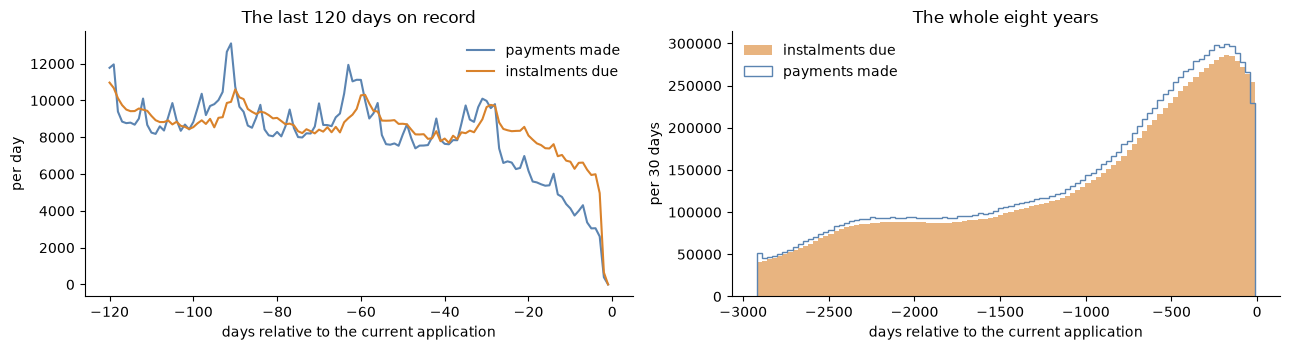

In [25]:
last_days = range(-45, 0)
per_day = pd.DataFrame({'payments made': inst['DAYS_ENTRY_PAYMENT'].value_counts().reindex(last_days).fillna(0).astype(int),
                        'instalments due': instalments['DUE_DATE'].value_counts().reindex(last_days).fillna(0).astype(int)})
level = per_day.loc[-45:-31].mean()
print('per day, relative to the average of days -45 to -31:')
shown = (per_day / level).loc[[-30, -25, -20, -15, -12, -10, -8, -6, -5, -4, -3, -2, -1]]
print(shown.round(2).T.to_string())
print(f"\naverage per day, days -45 to -31: {level.round(0).to_dict()}")

# the same by part: is the shape the same in train and test?
shape = {}
for label, ids in [('train', TRAIN_IDS), ('test', TEST_IDS)]:
    m = inst['SK_ID_CURR'].isin(ids)
    counts = inst.loc[m, 'DAYS_ENTRY_PAYMENT'].value_counts().reindex(last_days).fillna(0)
    shape[label] = (counts / counts.loc[-45:-31].mean()).loc[[-20, -10, -5, -3, -2, -1]]
print('\npayments made per day, relative to days -45 to -31, by file:')
print(pd.DataFrame(shape).round(2).T.to_string())

# the most recent payment of each applicant who has a loan that should still be paying
regular = ~instalments['IS_CARD'] & ~instalments['IS_EXTRA']
last_payment = instalments.groupby('SK_ID_CURR')['LAST_PAYMENT'].max()
print(f"\napplicants whose most recent payment was within 30 days of the application: {(last_payment > -31).mean():.1%}; within 7 days: {(last_payment > -8).mean():.1%}; on the day before: {(last_payment == -1).mean():.2%}")

fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
wide = range(-120, 0)
axes[0].plot(list(wide), inst['DAYS_ENTRY_PAYMENT'].value_counts().reindex(wide).fillna(0).values, color='#5b84b1', label='payments made')
axes[0].plot(list(wide), instalments['DUE_DATE'].value_counts().reindex(wide).fillna(0).values, color='#d9822b', label='instalments due')
axes[0].set_xlabel('days relative to the current application'); axes[0].set_ylabel('per day'); axes[0].set_title('The last 120 days on record'); axes[0].legend(frameon=False)
whole = np.arange(-2922, 0, 30)
axes[1].hist(instalments['DUE_DATE'], bins=whole, color='#d9822b', alpha=0.6, label='instalments due')
axes[1].hist(inst['DAYS_ENTRY_PAYMENT'].dropna().clip(lower=-2922), bins=whole, histtype='step', color='#5b84b1', label='payments made')
axes[1].set_xlabel('days relative to the current application'); axes[1].set_ylabel('per 30 days'); axes[1].set_title('The whole eight years'); axes[1].legend(frameon=False)
sns.despine(); plt.tight_layout(); plt.show()

### 4.3 What the cut hides: recent instalments

For an instalment that fell due *d* days before the application, a delay longer than *d* days cannot have been recorded. This section measures how much of the picture is lost for recent instalments, by comparing them with older ones, whose story is complete.

In [26]:
sched = instalments[regular]
age_band = pd.cut(-sched['DUE_DATE'], [0, 5, 10, 20, 30, 60, 90, 180, 365, 3000], labels=['1 to 5 days', '6 to 10', '11 to 20', '21 to 30', '31 to 60', '61 to 90', '91 to 180', '181 to 365', 'over a year'])
late = sched['LAST_PAYMENT'] - sched['DUE_DATE']
censor = pd.DataFrame({'instalments': age_band.value_counts().sort_index(),
                       'per day of due date': age_band.value_counts().sort_index() / np.array([5, 5, 10, 10, 30, 30, 90, 185, 2557]),
                       'completed before or on the due date %': (late <= 0).groupby(age_band, observed=True).mean() * 100,
                       'completed 1 to 5 days late %': late.between(1, 5).groupby(age_band, observed=True).mean() * 100,
                       'completed 6 to 30 days late %': late.between(6, 30).groupby(age_band, observed=True).mean() * 100,
                       'completed over 30 days late %': (late > 30).groupby(age_band, observed=True).mean() * 100,
                       'on record with no payment %': sched['UNPAID'].groupby(age_band, observed=True).mean() * 100})
print('cash and consumer loans, schedule instalments, by how long before the application they fell due:')
print(censor.to_string(float_format=lambda v: f'{v:,.2f}'))
settled = censor.loc['over a year']
print(f"\namong instalments due over a year before, {settled['completed 6 to 30 days late %'] + settled['completed over 30 days late %']:.2f}% were completed more than 5 days late. "
      f"Among those due in the last 5 days that figure is {censor.loc['1 to 5 days', 'completed 6 to 30 days late %'] + censor.loc['1 to 5 days', 'completed over 30 days late %']:.2f}%, because it cannot be otherwise.")
expected_rate = censor.loc['31 to 60':'61 to 90', 'per day of due date'].mean()
print(f"instalments on record per day of due date: {expected_rate:,.0f} for due dates 31 to 90 days back, {censor.loc['1 to 5 days', 'per day of due date']:,.0f} for the last 5 days "
      f"({censor.loc['1 to 5 days', 'per day of due date'] / expected_rate:.0%}), {censor.loc['6 to 10', 'per day of due date']:,.0f} for days 6 to 10 ({censor.loc['6 to 10', 'per day of due date'] / expected_rate:.0%})")

cash and consumer loans, schedule instalments, by how long before the application they fell due:
             instalments  per day of due date  completed before or on the due date %  completed 1 to 5 days late %  completed 6 to 30 days late %  completed over 30 days late %  on record with no payment %
DUE_DATE                                                                                                                                                                                                     
1 to 5 days        10920             2,184.00                                  95.03                          4.20                           0.00                           0.00                         0.77
6 to 10            20381             4,076.20                                  91.88                          7.51                           0.33                           0.00                         0.27
11 to 20           44968             4,496.80                                  

### 4.4 What the table never shows: instalments with no payment

Stage 3 found that almost every instalment on record has a payment, and that instalments due in the last few days are thin on the ground. Both fit one explanation: a row exists because a payment was made. An instalment that has fallen due and has not been paid mostly has no row at all.

If that is right, an applicant who has stopped paying a loan does not show as a string of unpaid instalments. They show as a loan whose record simply stops. This section looks for those loans, using `previous_application` to say which loans were still running and how many payments were planned.

In [27]:
loan_side = sched.groupby(level=0).agg(applicant=('SK_ID_CURR', 'first'), last_number=('DUE_DATE', 'size'), last_due=('DUE_DATE', 'max'), first_due=('DUE_DATE', 'min'))
loan_side['last_number'] = sched.reset_index().groupby('SK_ID_PREV')['NUM_INSTALMENT_NUMBER'].max()
open_column = 'TERMINATION_OPEN' if 'TERMINATION_OPEN' in prev_ids.columns else None
print('columns of the cleaned previous_application used here:', [c for c in ['CNT_PAYMENT', 'DAYS_TERMINATION', 'DAYS_LAST_DUE', 'TERMINATION_OPEN', 'LAST_DUE_OPEN', 'DAYS_LAST_DUE_1ST_VERSION'] if c in prev_ids.columns])
known_loans = loan_side.join(prev_ids[[c for c in ['CNT_PAYMENT', 'DAYS_TERMINATION', 'DAYS_LAST_DUE', 'TERMINATION_OPEN', 'LAST_DUE_OPEN', 'DAYS_LAST_DUE_1ST_VERSION'] if c in prev_ids.columns]], how='inner')
known_loans = known_loans[known_loans['CNT_PAYMENT'].notna()]
running = known_loans[open_column].astype(bool) if open_column else known_loans['DAYS_TERMINATION'].isna()
print(f"\ncash and consumer loans with payments and a planned number of payments: {len(known_loans):,}; marked as still running at the application: {running.mean():.1%}")

r = known_loans[running].copy()
r['remaining'] = r['CNT_PAYMENT'] - r['last_number']
r['next_due'] = r['last_due'] + 30                                    # stage 3: due dates are a month apart for 99.8% of these loans
r['days_overdue'] = -r['next_due']                                    # how long before the application the next instalment should have fallen due
overdue_band = pd.cut(r['days_overdue'], [-np.inf, 0, 5, 15, 30, 60, 120, np.inf], labels=['not yet due', '1 to 5 days', '6 to 15', '16 to 30', '31 to 60', '61 to 120', 'over 120'])
print(f"running loans: {len(r):,}; with instalments still to come according to the plan: {(r['remaining'] > 0).mean():.1%}")
owing = r[r['remaining'] > 0]
print('\nrunning loans with instalments still to come: when the next instalment after the last one on record should have fallen due')
table = pd.DataFrame({'loans': overdue_band[owing.index].value_counts().sort_index(), 'pct': overdue_band[owing.index].value_counts(normalize=True).sort_index() * 100})
print(table.round(2).to_string())
missed = owing['days_overdue'] > 15
print(f"\nrunning loans whose next instalment fell due more than 15 days before the application and is not on record: {int(missed.sum()):,} ({missed.mean():.1%} of running loans with instalments to come), "
      f"held by {owing.loc[missed, 'applicant'].nunique():,} applicants")
print(f"   more than 60 days before: {int((owing['days_overdue'] > 60).sum()):,} loans, {owing.loc[owing['days_overdue'] > 60, 'applicant'].nunique():,} applicants")
ended = known_loans[~running]
print(f"\nfor comparison, loans marked as ended ({len(ended):,}): the last instalment on record against the end date in previous_application")
if 'DAYS_LAST_DUE' in ended.columns:
    difference = ended['last_due'] - ended['DAYS_LAST_DUE']
    print(f"   last due date on record equals DAYS_LAST_DUE: {(difference == 0).mean():.1%}; within 31 days: {(difference.abs() <= 31).mean():.1%}; earlier by more than 31 days: {(difference < -31).mean():.1%}")
supply_missed = supply(missed.values, owing['applicant'].values)
print(f"\nsupply test for 'next instalment missing for more than 15 days', per applicant with such a running loan: train {supply_missed['train_pct']:.2f}%, test {supply_missed['test_pct']:.2f}%, AUC {supply_missed['auc']:.3f}")

columns of the cleaned previous_application used here: ['CNT_PAYMENT', 'DAYS_TERMINATION', 'DAYS_LAST_DUE', 'TERMINATION_OPEN', 'LAST_DUE_OPEN', 'DAYS_LAST_DUE_1ST_VERSION']



cash and consumer loans with payments and a planned number of payments: 896,367; marked as still running at the application: 15.4%
running loans: 138,106; with instalments still to come according to the plan: 98.2%

running loans with instalments still to come: when the next instalment after the last one on record should have fallen due
               loans    pct
days_overdue               
not yet due   116241  85.74
1 to 5 days    12143   8.96
6 to 15         3306   2.44
16 to 30        2703   1.99
31 to 60         883   0.65
61 to 120        137   0.10
over 120         164   0.12

running loans whose next instalment fell due more than 15 days before the application and is not on record: 3,887 (2.9% of running loans with instalments to come), held by 3,743 applicants
   more than 60 days before: 301 loans, 254 applicants

for comparison, loans marked as ended (758,261): the last instalment on record against the end date in previous_application
   last due date on record equals DAYS

### 4.5 Agreement with the dates in `previous_application`

Notebook 05 established that `previous_application` describes the state of each loan at the application date. If this table was recorded at the same moment, the two should agree on when loans started and ended.

In [28]:
both = loan_side.join(prev_ids[[c for c in ['DAYS_DECISION', 'DAYS_FIRST_DUE', 'DAYS_LAST_DUE', 'DAYS_TERMINATION', 'NAME_CONTRACT_TYPE'] if c in prev_ids.columns]], how='inner')
last_pay = sched.groupby(level=0)['LAST_PAYMENT'].max().reindex(both.index)
first_pay = sched.groupby(level=0)['FIRST_PAYMENT'].min().reindex(both.index)
agreement = {
    'the first instalment is due after the decision on the application': (both['first_due'] > both['DAYS_DECISION']).mean(),
    'no payment is dated before the decision': (first_pay >= both['DAYS_DECISION']).mean(),
    'first due date equals DAYS_FIRST_DUE (loans that start at instalment 1)': (both['first_due'] == both['DAYS_FIRST_DUE'])[both['DAYS_FIRST_DUE'].notna()].mean(),
    'ended loans: last payment is on or before the termination date': (last_pay <= both['DAYS_TERMINATION'])[both['DAYS_TERMINATION'].notna()].mean(),
    'ended loans: no instalment is due after the termination date': (both['last_due'] <= both['DAYS_TERMINATION'])[both['DAYS_TERMINATION'].notna()].mean(),
}
for name, share in agreement.items():
    print(f"{share:8.2%}  {name}")
after_end = (last_pay - both['DAYS_TERMINATION'])[both['DAYS_TERMINATION'].notna()]
print(f"\nended loans whose last payment is after the termination date: {(after_end > 0).mean():.2%}; by how many days, quartiles: {after_end[after_end > 0].quantile([0.25, 0.5, 0.75, 0.95]).round(0).to_dict()}")
before_decision = (first_pay - both['DAYS_DECISION'])
print(f"loans with a payment dated before the decision: {int((before_decision < 0).sum()):,}; by how many days, quartiles: {before_decision[before_decision < 0].quantile([0.05, 0.25, 0.5]).round(0).to_dict()}")

 100.00%  the first instalment is due after the decision on the application
  99.94%  no payment is dated before the decision
 100.00%  first due date equals DAYS_FIRST_DUE (loans that start at instalment 1)
 100.00%  ended loans: last payment is on or before the termination date
 100.00%  ended loans: no instalment is due after the termination date

ended loans whose last payment is after the termination date: 0.00%; by how many days, quartiles: {0.25: nan, 0.5: nan, 0.75: nan, 0.95: nan}
loans with a payment dated before the decision: 456; by how many days, quartiles: {0.05: -242.0, 0.25: -55.0, 0.5: -22.0}


### 4.6 A leak screen

The last check is the blunt one used in notebooks 03 and 05. If any fact about the dates gave away the outcome, it would show as a score far above anything a legitimate feature reaches. The strongest single features in the model score about 0.64 alone.

Development applicants only.

In [29]:
g = instalments.groupby('SK_ID_CURR')
screen = pd.DataFrame({
    'days since the most recent payment': -g['LAST_PAYMENT'].max(),
    'days since the most recent due date': -g['DUE_DATE'].max(),
    'payments made in the last 30 days': (instalments['LAST_PAYMENT'] > -31).groupby(instalments['SK_ID_CURR']).sum(),
    'instalments due in the last 30 days': (instalments['DUE_DATE'] > -31).groupby(instalments['SK_ID_CURR']).sum(),
    'instalments due in the last 5 days': (instalments['DUE_DATE'] > -6).groupby(instalments['SK_ID_CURR']).sum(),
    'instalments with no payment, due in the last 30 days': (instalments['UNPAID'] & (instalments['DUE_DATE'] > -31)).groupby(instalments['SK_ID_CURR']).sum(),
    'instalments with no payment, any time': g['UNPAID'].sum(),
    'gap between last due date and last payment': g['DUE_DATE'].max() - g['LAST_PAYMENT'].max(),
    'running loans whose next instalment is missing for over 15 days': missed.groupby(owing['applicant']).sum().reindex(g.size().index).fillna(0),
}).reindex(DEV_IDS)
rows = {}
for c in screen.columns:
    ok = screen[c].notna().values
    a = roc_auc_score(y_dev.values[ok], screen[c].values[ok])
    positive = (screen[c] > 0)
    rows[c] = {'applicants_with_a_value': int(ok.sum()), 'auc_alone': max(a, 1 - a), 'higher_means': 'more risk' if a > 0.5 else 'less risk',
               'applicants_above_zero_pct': positive[ok].mean() * 100, 'default_pct_above_zero': y_dev[positive.values].mean() * 100, 'default_pct_at_zero_or_below': y_dev[ok & ~positive.values].mean() * 100}
screen_table = pd.DataFrame(rows).T
print(screen_table.to_string(float_format=lambda v: f'{v:,.3f}'))
print(f"\nhighest score alone: {screen_table['auc_alone'].max():.3f} ({screen_table['auc_alone'].astype(float).idxmax()}); for comparison the strongest features in the model score about 0.64 alone")

                                                                applicants_with_a_value auc_alone higher_means applicants_above_zero_pct default_pct_above_zero default_pct_at_zero_or_below
days since the most recent payment                                               233317     0.510    less risk                   100.000                  8.187                          NaN
days since the most recent due date                                              233322     0.503    less risk                   100.000                  8.187                          NaN
payments made in the last 30 days                                                233322     0.520    more risk                    31.759                  8.864                        7.871
instalments due in the last 30 days                                              233322     0.514    more risk                    43.562                  8.338                        8.069
instalments due in the last 5 days                     

### 4.7 The preparation function

The cleaning function of stage 3 and the collapse to instalments stay as they are. This function adds the time rule and the two quantities every later stage needs.

In [30]:
def prepare_instalments(raw):
    """Clean the rows, collapse them to instalments, enforce the time rule, and add the derived columns."""
    assert (raw['DAYS_INSTALMENT'] < 0).all() and (raw['DAYS_ENTRY_PAYMENT'].dropna() < 0).all(), 'a date on or after the application'
    out = to_instalments(clean_installments(raw))
    out['DAYS_LATE'] = out['LAST_PAYMENT'] - out['DUE_DATE']          # completion date minus due date; positive is late; missing when nothing was paid
    out['DAYS_OBSERVED'] = -out['DUE_DATE']                           # how long before the application it fell due: no delay longer than this can be on record
    out['SHORTFALL'] = (out['AMT_DUE'] - out['AMT_PAID']).clip(lower=0)
    return out

started = time.time()
prepared = prepare_instalments(inst)
print(f"prepared in {time.time() - started:.0f} seconds: {len(prepared):,} instalments, {prepared.shape[1]} columns: {list(prepared.columns)}")
time_checks = {
    'no due date or payment date on or after day 0': bool((prepared['DUE_DATE'] < 0).all() and (prepared['LAST_PAYMENT'].dropna() < 0).all()),
    'a recorded delay is never longer than the time available for it': bool((prepared['DAYS_LATE'].dropna() < prepared.loc[prepared['DAYS_LATE'].notna(), 'DAYS_OBSERVED']).all()),
    'the same instalments as stage 3': prepared.index.equals(instalments.index),
    'a function of the raw rows only: the same result from a fresh read of 5,000 loans': same_result(prepare_instalments(some_rows)[list(instalments.columns.drop('DAYS_LATE', errors='ignore'))],
                                                                                                    prepared.loc[prepared.index.get_level_values(0).isin(some_rows[LOAN].unique()), list(instalments.columns.drop('DAYS_LATE', errors='ignore'))]),
}
for name, ok in time_checks.items():
    print(f"{'PASS' if ok else 'FAIL'}  {name}")
assert all(time_checks.values())

prepared in 26 seconds: 12,861,994 instalments, 14 columns: ['SK_ID_CURR', 'IS_CARD', 'IS_EXTRA', 'DUE_DATE', 'N_VERSIONS', 'AMT_DUE', 'AMT_PAID', 'N_PAYMENTS', 'FIRST_PAYMENT', 'LAST_PAYMENT', 'UNPAID', 'DAYS_LATE', 'DAYS_OBSERVED', 'SHORTFALL']


PASS  no due date or payment date on or after day 0
PASS  a recorded delay is never longer than the time available for it
PASS  the same instalments as stage 3
PASS  a function of the raw rows only: the same result from a fresh read of 5,000 loans


### Stage 4 findings

**Nothing in the table is dated on or after the application**
- Of 13.6 million due dates and payment dates, none is on day zero or later, in train or in test. The preparation function now refuses any table where one is.

**The record thins out before the application and all but stops two days before it**

| Days before the application | 30 | 20 | 10 | 5 | 3 | 2 | 1 |
|---|---:|---:|---:|---:|---:|---:|---:|
| Payments made, relative to the usual rate | 1.18 | 0.73 | 0.49 | 0.36 | 0.31 | 0.05 | 0.00 |
| Instalments due, relative to the usual rate | 1.18 | 0.99 | 0.82 | 0.73 | 0.61 | 0.08 | 0.00 |

- A table recorded on the day of the application, with every payment up to it, would hold level until the last day. This one does not. Only two rows in the whole table are dated the day before.
- Two things together explain the shape. First, **a row exists only when both of its dates are before the application.** Most instalments are paid early, by a median of 6 days, so a payment made ten days before the application is often for an instalment due after it, and that row is not here. That is why payments thin out sooner than due dates. Second, an instalment that has fallen due and has not been paid mostly has no row, which thins the due dates in the last few days.
- The near-absence of the last two days suggests the record was also closed a day or two before the application. I cannot separate that from the first two effects, and it does not matter for safety: all three mean less information, never information from afterwards.
- The shape is the same in train and test (0.49 and 0.49 at ten days, 0.31 and 0.32 at three).
- So the answer to the question of this stage is that the table holds nothing from after the application, and somewhat less than everything from just before it.

**What the cut hides**

| Instalment fell due | Completed over 30 days late | Completed 6 to 30 days late | On record with no payment |
|---|---:|---:|---:|
| 1 to 5 days before | 0.00% | 0.00% | 0.77% |
| 11 to 20 days before | 0.00% | 1.01% | 0.23% |
| 31 to 60 days before | 0.05% | 0.83% | 0.11% |
| 181 to 365 days before | 0.04% | 1.80% | 0.01% |
| Over a year before | 0.31% | 4.21% | 0.00% |

- A delay cannot be recorded as longer than the time there was for it. An instalment due five days before the application is never "30 days late" here, however it ended. Any feature that counts long delays has to say over which instalments it could have seen one. `DAYS_OBSERVED` is carried on every instalment for that purpose.
- There is a second pattern in this table that is not about the cut. Delays of 6 to 30 days were 4.2% of instalments more than a year back and are 1% to 2% in the last year, where a 30-day delay is fully observable. The applicants in this file were all approved for a new loan, and a lender is less likely to approve someone who has just been paying late. So recent lateness is rare here partly because those who had it are not in the file. Stage 5 looks at whether the lateness that remains still says something.

**A hypothesis that did not hold**
- I expected an applicant who had stopped paying to show as a running loan whose record simply stops. `previous_application` marks 138,106 of these loans as still running, and for 3,887 of them the next instalment fell due more than 15 days before the application and is not on record.
- Those applicants default at 6.1%, against 8.2% for the rest. They are safer, not riskier. Whatever these loans are, they are not loans in arrears. More likely the loan was settled and the status in the other table was not updated.
- The fact is also twice as common in train as in test (3.3% of such applicants against 1.3%). No feature will be built from it.

**Instalments with no payment are rare and serious**

| | Applicants | Default rate |
|---|---:|---:|
| An instalment due in the last 30 days, on record with no payment | 0.16% | 29.3% |
| An instalment with no payment at any time | 0.37% | 18.4% |
| Everyone else | | 8.2% |

- After stage 3 I was inclined to leave unpaid instalments out, because they are 0.02% of rows and many are small sums on old cards. That would have been the mistake this project has now made four times: judging a rare event by how rare it is. Applicants with a recent unpaid instalment default at more than three times the average.
- As a score it is nothing (0.502), which is the usual sign of a rare event. Stage 6 builds it, with the old card remnants kept out by an amount threshold fixed without reference to outcomes.

**Agreement with `previous_application`**
- The first due date equals `DAYS_FIRST_DUE` for 100.0% of loans that start at instalment 1. For ended loans, the last due date on record equals `DAYS_LAST_DUE` for 100.0%, and no payment or instalment falls after the termination date.
- 456 loans (0.06%) have a payment dated before the decision on their application. They are left as they are.
- The two tables describe the same loans at the same moment.

**Leak screen**
- Nine facts about dates were scored alone on the development applicants. The highest is 0.539 (the gap between the last due date and the last payment). The strongest features in the model score about 0.64. Nothing looks like a leak.

**Decisions**
- `prepare_instalments` is the single entry point: it checks the dates, cleans, collapses to instalments, and adds the delay, the time available to observe it, and the shortfall.
- Long delays are counted only over instalments old enough to show one.
- Recent unpaid instalments are a candidate feature. The stopped-record idea is dropped.

## Stage 5: Signal

Which kinds of payment behaviour relate to default, and in what shape?

Each applicant's instalments are summarised in the simplest way that answers one question at a time, and the default rate is read off by band. As in notebooks 03 and 05, this stage describes and does not select. No feature is chosen here by its score.

Only the 233,322 development applicants with a payment history are used. Loans with a schedule, cards, and penalty charges are kept apart throughout.

| Section | Question |
|---|---|
| 5.1 | Set-up |
| 5.2 | Paying late: how often, and how badly |
| 5.3 | Paying early |
| 5.4 | Penalty charges, unpaid instalments, and paying in parts |
| 5.5 | Does the age of the behaviour change what it says? |
| 5.6 | Cards |
| 5.7 | Amounts: what is paid each month, and early repayment |
| 5.8 | Is any of this new, or do the external scores and the model's own features already hold it? |

### 5.1 Set-up

In [31]:
dev = prepared[prepared['SK_ID_CURR'].isin(DEV_IDS)]
sched_dev = dev[~dev['IS_CARD'] & ~dev['IS_EXTRA']]
card_dev = dev[dev['IS_CARD']]
extra_dev = dev[dev['IS_EXTRA']]
print(f"development instalments: {len(dev):,} of {dev['SK_ID_CURR'].nunique():,} applicants; on loans with a schedule {len(sched_dev):,} ({sched_dev['SK_ID_CURR'].nunique():,} applicants); "
      f"on cards {len(card_dev):,} ({card_dev['SK_ID_CURR'].nunique():,}); penalty charges {len(extra_dev):,} ({extra_dev['SK_ID_CURR'].nunique():,})")

def band_rates(values, edges, labels, title=None):
    # default rate of development applicants by band of a per-applicant value; applicants without a value are left out
    table = rate_table(pd.cut(values, edges, labels=labels))
    if title:
        print(title)
    print(table.to_string(float_format=lambda v: f'{v:,.2f}'))
    return table

def auc_alone(values):
    v = values.reindex(DEV_IDS)
    ok = v.notna().values
    a = roc_auc_score(y_dev.values[ok], v.values[ok])
    return max(a, 1 - a), ('more risk' if a > 0.5 else 'less risk'), int(ok.sum())

signal = {}
def record(name, values):
    a, direction, n = auc_alone(values)
    signal[name] = {'applicants': n, 'auc_alone': a, 'higher_means': direction}
    print(f"   {name}: AUC alone {a:.4f} (higher means {direction}), {n:,} applicants\n")

development instalments: 8,767,148 of 233,322 applicants; on loans with a schedule 6,022,473 (231,105 applicants); on cards 2,730,948 (49,110); penalty charges 13,727 (7,246)


### 5.2 Paying late

Three ways of measuring the same thing: what share of an applicant's instalments were completed late, how long the worst delay was, and how many were seriously late. Long delays are counted only over instalments that fell due early enough to show one.

In [32]:
by = sched_dev['SK_ID_CURR']
late = sched_dev['DAYS_LATE']
share_late = (late > 0).groupby(by).mean()
share_late5 = (late > 5).groupby(by).mean()
band_rates(share_late * 100, [-1, 0, 5, 10, 20, 40, 100], ['never late', 'up to 5%', '5 to 10%', '10 to 20%', '20 to 40%', 'over 40%'], 'by share of instalments completed after the due date:')
record('share of instalments completed late', share_late)
band_rates(share_late5 * 100, [-1, 0, 5, 10, 20, 100], ['none', 'up to 5%', '5 to 10%', '10 to 20%', 'over 20%'], 'by share completed more than 5 days late:')
record('share completed more than 5 days late', share_late5)

worst = late.groupby(by).max()
band_rates(worst, [-np.inf, 0, 5, 15, 30, 60, 120, np.inf], ['never late', '1 to 5 days', '6 to 15', '16 to 30', '31 to 60', '61 to 120', 'over 120'], 'by the longest delay on any instalment:')
record('longest delay', worst)

old_enough = sched_dev['DAYS_OBSERVED'] > 30
n30 = ((late > 30) & old_enough).groupby(by).sum()
band_rates(n30.where(old_enough.groupby(by).any()), [-1, 0, 1, 2, 5, np.inf], ['none', '1', '2', '3 to 5', '6 or more'], 'by number of instalments completed more than 30 days late (among instalments due over 30 days before the application):')
record('instalments over 30 days late', n30.where(old_enough.groupby(by).any()))

mean_late = late.clip(lower=0).groupby(by).mean()
record('average days late, counting an on-time payment as zero', mean_late)

by share of instalments completed after the due date:
            applicants  pct_of_applicants  default_pct  standard_error  ratio_to_average
DAYS_LATE                                                                               
never late      117305              47.68         6.99            0.07              0.87
up to 5%         21533               8.75         6.46            0.17              0.80
5 to 10%         25983              10.56         8.39            0.17              1.04
10 to 20%        29505              11.99         9.59            0.17              1.19
20 to 40%        24712              10.05        10.65            0.20              1.32
over 40%         12067               4.91        13.34            0.31              1.65
   share of instalments completed late: AUC alone 0.5583 (higher means more risk), 231,105 applicants

by share completed more than 5 days late:
           applicants  pct_of_applicants  default_pct  standard_error  ratio_to_average
D

by the longest delay on any instalment:
             applicants  pct_of_applicants  default_pct  standard_error  ratio_to_average
DAYS_LATE                                                                                
never late       117300              47.68         6.99            0.07              0.87
1 to 5 days       46882              19.06         8.41            0.13              1.04
6 to 15           34302              13.94         9.90            0.16              1.23
16 to 30          21579               8.77        10.44            0.21              1.29
31 to 60           6722               2.73        10.44            0.37              1.29
61 to 120           795               0.32         9.43            1.04              1.17
over 120           3520               1.43         7.84            0.45              0.97
   longest delay: AUC alone 0.5431 (higher means more risk), 231,100 applicants



by number of instalments completed more than 30 days late (among instalments due over 30 days before the application):
           applicants  pct_of_applicants  default_pct  standard_error  ratio_to_average
none           219937              89.40         8.08            0.06              1.00
1                8513               3.46         9.21            0.31              1.14
2                1518               0.62        10.47            0.79              1.30
3 to 5            903               0.37        11.18            1.05              1.39
6 or more         103               0.04         8.74            2.78              1.08
   instalments over 30 days late: AUC alone 0.5045 (higher means more risk), 230,974 applicants



   average days late, counting an on-time payment as zero: AUC alone 0.5546 (higher means more risk), 231,100 applicants



### 5.3 Paying early

Most instalments are paid before they are due. Is the margin itself informative?

In [33]:
days_early = (-late).clip(lower=0, upper=60)
mean_early = days_early.groupby(by).mean()
band_rates(mean_early, [-1, 1, 3, 6, 10, 15, 25, 61], ['under 1 day', '1 to 3', '3 to 6', '6 to 10', '10 to 15', '15 to 25', 'over 25'], 'by average number of days paid before the due date (capped at 60):')
record('average days paid early', mean_early)
share_on_day = (late == 0).groupby(by).mean()
band_rates(share_on_day * 100, [-1, 0, 10, 30, 60, 100], ['never', 'up to 10%', '10 to 30%', '30 to 60%', 'over 60%'], 'by share of instalments paid exactly on the due date:')
record('share paid on the due date', share_on_day)
spread = late.groupby(by).std()
record('variation in timing (standard deviation of days late)', spread)

by average number of days paid before the due date (capped at 60):
             applicants  pct_of_applicants  default_pct  standard_error  ratio_to_average
DAYS_LATE                                                                                
under 1 day        3618               1.47        11.17            0.52              1.38
1 to 3            12294               5.00        11.14            0.28              1.38
3 to 6            34618              14.07         9.27            0.16              1.15
6 to 10           57002              23.17         8.31            0.12              1.03
10 to 15          58218              23.67         7.68            0.11              0.95
15 to 25          48145              19.57         7.02            0.12              0.87
over 25           17205               6.99         7.37            0.20              0.91
   average days paid early: AUC alone 0.5376 (higher means less risk), 231,100 applicants



by share of instalments paid exactly on the due date:
           applicants  pct_of_applicants  default_pct  standard_error  ratio_to_average
DAYS_LATE                                                                              
never          119783              48.69         8.17            0.08              1.01
up to 10%       59557              24.21         8.06            0.11              1.00
10 to 30%       41533              16.88         8.35            0.14              1.03
30 to 60%        8419               3.42         7.60            0.29              0.94
over 60%         1813               0.74         8.11            0.64              1.00
   share paid on the due date: AUC alone 0.5015 (higher means more risk), 231,105 applicants



   variation in timing (standard deviation of days late): AUC alone 0.5033 (higher means more risk), 230,304 applicants



### 5.4 Penalty charges, unpaid instalments, and paying in parts

In [34]:
applicants = pd.Index(dev['SK_ID_CURR'].unique())
n_extra = extra_dev.groupby('SK_ID_CURR').size().reindex(applicants).fillna(0)
band_rates(n_extra, [-1, 0, 1, 2, 4, np.inf], ['none', '1', '2', '3 to 4', '5 or more'], 'by number of penalty charges (rows numbered above 100):')
record('penalty charges', n_extra)
last_extra = (-extra_dev.groupby('SK_ID_CURR')['DUE_DATE'].max())
band_rates(last_extra, [0, 365, 730, 1461, 3000], ['within a year', '1 to 2 years', '2 to 4 years', 'over 4 years'], 'among applicants with a penalty charge, by when the most recent fell due:')

# unpaid instalments: recent, and of real size
UNPAID_MIN_AMOUNT = 200                 # fixed from stage 3 without outcomes: 93% of unpaid amounts over two years old are below it, and 85% of recent ones are above
unpaid_real = dev['UNPAID'] & (dev['AMT_DUE'] >= UNPAID_MIN_AMOUNT)
any_unpaid = unpaid_real.groupby(dev['SK_ID_CURR']).any().reindex(applicants, fill_value=False).astype(bool)
recent_unpaid = (unpaid_real & (dev['DAYS_OBSERVED'] <= 30)).groupby(dev['SK_ID_CURR']).any().reindex(applicants, fill_value=False).astype(bool)
older_unpaid = (unpaid_real & (dev['DAYS_OBSERVED'] > 30)).groupby(dev['SK_ID_CURR']).any().reindex(applicants, fill_value=False).astype(bool)
small_unpaid = (dev['UNPAID'] & (dev['AMT_DUE'] < UNPAID_MIN_AMOUNT)).groupby(dev['SK_ID_CURR']).any().reindex(applicants, fill_value=False).astype(bool)
kind = pd.Series('none', index=applicants)
kind[small_unpaid.values] = 'only amounts under 200'
kind[older_unpaid.values] = 'of 200 or more, due over 30 days before'
kind[recent_unpaid.values] = 'of 200 or more, due within 30 days'
print('by whether an instalment is on record with no payment:')
print(rate_table(kind).to_string(float_format=lambda v: f'{v:,.2f}'))
print()

share_parts = (sched_dev['N_PAYMENTS'] > 1).groupby(by).mean()
band_rates(share_parts * 100, [-1, 0, 5, 15, 30, 100], ['never', 'up to 5%', '5 to 15%', '15 to 30%', 'over 30%'], 'by share of instalments paid in more than one payment:')
record('share of instalments paid in parts', share_parts)
short = (sched_dev['SHORTFALL'] > 0.01) & ~sched_dev['UNPAID']
any_short = short.groupby(by).any()
print('by whether any instalment was paid less than was due:')
print(rate_table(any_short.map({True: 'yes', False: 'no'})).to_string(float_format=lambda v: f'{v:,.2f}'))

by number of penalty charges (rows numbered above 100):
           applicants  pct_of_applicants  default_pct  standard_error  ratio_to_average
none           226076              91.90         7.96            0.06              0.99
1                4475               1.82        13.07            0.50              1.62
2                1378               0.56        15.97            0.99              1.98
3 to 4            922               0.37        19.52            1.31              2.42
5 or more         471               0.19        23.78            1.96              2.95
   penalty charges: AUC alone 0.5145 (higher means more risk), 233,322 applicants

among applicants with a penalty charge, by when the most recent fell due:
               applicants  pct_of_applicants  default_pct  standard_error  ratio_to_average
DUE_DATE                                                                                   
within a year        1003               0.41        26.92            1.40  

by whether an instalment is on record with no payment:
                                         applicants  pct_of_applicants  default_pct  standard_error  ratio_to_average
none                                         232460              94.49         8.15            0.06              1.01
of 200 or more, due over 30 days before         111               0.05        18.02            3.65              2.23
of 200 or more, due within 30 days              320               0.13        29.69            2.55              3.68
only amounts under 200                          431               0.18        10.21            1.46              1.26



by share of instalments paid in more than one payment:
            applicants  pct_of_applicants  default_pct  standard_error  ratio_to_average
N_PAYMENTS                                                                              
never           141499              57.52         7.20            0.07              0.89
up to 5%         23503               9.55         7.00            0.17              0.87
5 to 15%         35046              14.25         9.49            0.16              1.18
15 to 30%        19972               8.12        10.93            0.22              1.35
over 30%         11085               4.51        13.55            0.33              1.68
   share of instalments paid in parts: AUC alone 0.5511 (higher means more risk), 231,105 applicants



by whether any instalment was paid less than was due:
     applicants  pct_of_applicants  default_pct  standard_error  ratio_to_average
no       229593              93.33         8.10            0.06              1.00
yes        1512               0.61        16.01            0.94              1.98


### 5.5 Does the age of the behaviour change what it says?

Stage 4 found that recent lateness is rarer than old lateness among these applicants, probably because a lender is less willing to approve someone who has just paid late. If that is the reason, the recent lateness that did get through might say more, or less, than old lateness does.

In [35]:
windows = {'last 6 months': sched_dev['DAYS_OBSERVED'] <= 183, '6 to 12 months back': sched_dev['DAYS_OBSERVED'].between(184, 365), '1 to 2 years back': sched_dev['DAYS_OBSERVED'].between(366, 730),
           '2 to 4 years back': sched_dev['DAYS_OBSERVED'].between(731, 1461), 'over 4 years back': sched_dev['DAYS_OBSERVED'] > 1461}
rows = {}
for label, w in windows.items():
    n = w.groupby(by).sum()
    had = n[n > 0].index
    any_late5 = ((late > 5) & w).groupby(by).any().reindex(had)
    y = y_dev.reindex(had)
    share = ((late > 5) & w).groupby(by).sum().reindex(had) / n.reindex(had)
    a = roc_auc_score(y.values, share.values)
    rows[label] = {'applicants with an instalment due then': len(had), 'instalments late by over 5 days %': ((late > 5) & w).sum() / w.sum() * 100, 'applicants with one %': any_late5.mean() * 100,
                   'default % with one': y[any_late5.values].mean() * 100, 'default % without': y[~any_late5.values].mean() * 100,
                   'ratio': y[any_late5.values].mean() / y[~any_late5.values].mean(), 'auc of the share alone': max(a, 1 - a)}
age_table = pd.DataFrame(rows).T
print('instalments completed more than 5 days late, by when they fell due:')
print(age_table.to_string(float_format=lambda v: f'{v:,.3f}'))

# the direction of travel: is the applicant paying later or earlier than they used to?
recent_w, older_w = sched_dev['DAYS_OBSERVED'] <= 365, sched_dev['DAYS_OBSERVED'] > 365
recent_mean = late.clip(-60, 60).where(recent_w).groupby(by).mean()
older_mean = late.clip(-60, 60).where(older_w).groupby(by).mean()
trend = (recent_mean - older_mean).dropna()
print(f"\napplicants with instalments in both the last year and before it: {len(trend):,}")
band_rates(trend, [-np.inf, -10, -3, 3, 10, np.inf], ['over 10 days earlier', '3 to 10 earlier', 'about the same', '3 to 10 later', 'over 10 days later'], 'by change in average timing, last year against earlier (days; later means paying later than before):')
record('change in timing, last year against earlier', trend)
record('average timing in the last year (days late, negative is early)', recent_mean)
record('average timing before the last year', older_mean)

instalments completed more than 5 days late, by when they fell due:
                     applicants with an instalment due then  instalments late by over 5 days %  applicants with one %  default % with one  default % without  ratio  auc of the share alone
last 6 months                                   126,814.000                              1.216                  4.500              15.437              7.349  2.101                   0.525
6 to 12 months back                             144,574.000                              1.919                  6.153              14.930              7.600  1.965                   0.529
1 to 2 years back                               153,281.000                              2.333                  9.466              13.790              7.466  1.847                   0.538
2 to 4 years back                               127,976.000                              3.943                 17.866              10.269              6.889  1.491                 


applicants with instalments in both the last year and before it: 140,145
by change in average timing, last year against earlier (days; later means paying later than before):
                      applicants  pct_of_applicants  default_pct  standard_error  ratio_to_average
DAYS_LATE                                                                                         
over 10 days earlier       19799               8.05         7.13            0.18              0.88
3 to 10 earlier            25217              10.25         7.03            0.16              0.87
about the same             43647              17.74         7.56            0.13              0.94
3 to 10 later              35365              14.38         8.34            0.15              1.03
over 10 days later         16117               6.55         8.77            0.22              1.09
   change in timing, last year against earlier: AUC alone 0.5244 (higher means more risk), 140,145 applicants

   average timing in 

### 5.6 Cards

Stage 3 found that a card's "amount due" looks like a record of what was paid, so lateness on a card may mean less than on a loan with a schedule.

In [36]:
cby = card_dev['SK_ID_CURR']
has_card = pd.Series(applicants.isin(cby.unique()), index=applicants)
print(rate_table(has_card.map({True: 'has card payments on record', False: 'none'})).to_string(float_format=lambda v: f'{v:,.2f}'))
card_late = (card_dev['DAYS_LATE'] > 5).groupby(cby).mean()
band_rates(card_late * 100, [-1, 0, 5, 15, 100], ['none', 'up to 5%', '5 to 15%', 'over 15%'], '\namong applicants with card payments, by share of card instalments completed more than 5 days late:')
record('cards: share completed more than 5 days late', card_late)
n_card = card_dev.groupby(cby).size()
band_rates(n_card, [0, 6, 12, 24, 48, np.inf], ['1 to 6', '7 to 12', '13 to 24', '25 to 48', 'over 48'], 'by number of card instalments on record:')
record('cards: instalments on record', n_card)
recent_card = (card_dev['DAYS_OBSERVED'] <= 90).groupby(cby).any()
print('among applicants with card payments, by whether one fell due in the last 90 days:')
print(rate_table(recent_card.map({True: 'yes', False: 'no'})).to_string(float_format=lambda v: f'{v:,.2f}'))
card_amount = card_dev['AMT_PAID'].where(card_dev['DAYS_OBSERVED'] <= 365).groupby(cby).mean()
record('cards: average payment in the last year', card_amount)

                             applicants  pct_of_applicants  default_pct  standard_error  ratio_to_average
has card payments on record       49110              19.96        10.07            0.14              1.25
none                             184212              74.88         7.68            0.06              0.95

among applicants with card payments, by share of card instalments completed more than 5 days late:
           applicants  pct_of_applicants  default_pct  standard_error  ratio_to_average
DAYS_LATE                                                                              
none            32306              13.13         9.91            0.17              1.23
up to 5%        10919               4.44         8.78            0.27              1.09
5 to 15%         4677               1.90        13.04            0.49              1.62
over 15%         1208               0.49        14.57            1.02              1.80
   cards: share completed more than 5 days late: AUC a

by number of card instalments on record:
          applicants  pct_of_applicants  default_pct  standard_error  ratio_to_average
1 to 6          2031               0.83        10.49            0.68              1.30
7 to 12         3097               1.26        15.37            0.65              1.90
13 to 24        9945               4.04        14.16            0.35              1.75
25 to 48       10947               4.45        11.03            0.30              1.37
over 48        23090               9.39         7.10            0.17              0.88
   cards: instalments on record: AUC alone 0.5953 (higher means less risk), 49,110 applicants

among applicants with card payments, by whether one fell due in the last 90 days:
               applicants  pct_of_applicants  default_pct  standard_error  ratio_to_average
DAYS_OBSERVED                                                                              
no                   8209               3.34         7.21            0.29   

   cards: average payment in the last year: AUC alone 0.5332 (higher means more risk), 44,965 applicants



### 5.7 Amounts

What the applicant has been paying each month, and whether loans were ended with one large payment.

In [37]:
last_year = sched_dev['DAYS_OBSERVED'] <= 365
paid_last_year = sched_dev['AMT_PAID'].where(last_year).groupby(by).sum(min_count=1)
band = pd.qcut(paid_last_year, 5, labels=['lowest fifth', 'second', 'middle', 'fourth', 'highest fifth'])
print('by total paid on loans with a schedule in the last year (fifths of those with any):')
print(rate_table(band).to_string(float_format=lambda v: f'{v:,.2f}'))
record('total paid in the last year', paid_last_year)
typical = sched_dev['AMT_DUE'].groupby(by).median()
record('typical instalment (median amount due)', typical)

# a loan ended by one payment much larger than its usual instalment
loan_keys = [sched_dev['SK_ID_CURR'], sched_dev.index.get_level_values(0)]
usual = sched_dev['AMT_DUE'].groupby(loan_keys).transform('median')
large = sched_dev['AMT_DUE'] > 3 * usual
loan_large = large.groupby(loan_keys).any()
share_large = loan_large.groupby(level=0).mean()
band_rates(share_large * 100, [-1, 0, 34, 67, 100], ['no loan', 'up to a third', 'a third to two thirds', 'over two thirds'], '\nby share of loans that include an instalment over three times the usual one (an early repayment of the balance):')
record('share of loans with a large final payment', share_large)
versions = (sched_dev['N_VERSIONS'] > 1).groupby(by).mean()
record('share of instalments with the amount due written in parts', versions)

by total paid on loans with a schedule in the last year (fifths of those with any):
               applicants  pct_of_applicants  default_pct  standard_error  ratio_to_average
AMT_PAID                                                                                   
lowest fifth        32112              13.05         9.68            0.17              1.20
second              32112              13.05         8.28            0.15              1.03
middle              32112              13.05         7.46            0.15              0.92
fourth              32112              13.05         7.49            0.15              0.93
highest fifth       32112              13.05         7.35            0.15              0.91
   total paid in the last year: AUC alone 0.5322 (higher means less risk), 160,560 applicants



   typical instalment (median amount due): AUC alone 0.5442 (higher means less risk), 231,105 applicants




by share of loans that include an instalment over three times the usual one (an early repayment of the balance):
                       applicants  pct_of_applicants  default_pct  standard_error  ratio_to_average
AMT_DUE                                                                                            
no loan                    134004              54.47         8.18            0.07              1.01
up to a third               36087              14.67         6.84            0.13              0.85
a third to two thirds       38490              15.65         8.34            0.14              1.03
over two thirds             22524               9.16         9.75            0.20              1.21
   share of loans with a large final payment: AUC alone 0.5070 (higher means more risk), 231,105 applicants



   share of instalments with the amount due written in parts: AUC alone 0.5159 (higher means less risk), 231,105 applicants



### 5.8 Is any of this new?

A relationship with default says little about what a feature adds to a model that already knows a great deal. Notebook 05 called refusals the clearest signal in its table, and they added almost nothing. So before anything is built, the strongest of the behaviours above are looked at beside what the model already has: the external scores, and the features from `previous_application` that are closest to them.

In [38]:
app = pd.read_parquet(f'{PROCESSED}/application_train_features.parquet', columns=['EXT_MEAN']).loc[DEV_IDS]
prev_feats = pd.read_parquet(f'{PROCESSED}/previous_train_features.parquet').loc[DEV_IDS]
candidates = {'share of instalments completed late': share_late, 'share completed more than 5 days late': share_late5, 'longest delay': worst, 'average days paid early': mean_early,
              'penalty charges': n_extra, 'share of instalments paid in parts': share_parts, 'average timing in the last year (days late, negative is early)': recent_mean,
              'share of loans with a large final payment': share_large, 'total paid in the last year': paid_last_year}
ext_third = pd.qcut(app['EXT_MEAN'], 3, labels=['low scores', 'middle', 'high scores'])
rows = {}
for name, values in candidates.items():
    v = values.reindex(DEV_IDS)
    ok = v.notna() & app['EXT_MEAN'].notna()
    within = []
    for third in ext_third.cat.categories:
        m = (ok & (ext_third == third)).values
        a = roc_auc_score(y_dev.values[m], v.values[m])
        within.append(a)
    overall = roc_auc_score(y_dev.values[ok.values], v.values[ok.values])
    flip = lambda a: a if overall > 0.5 else 1 - a
    closest = prev_feats.corrwith(v, method='spearman').abs().sort_values(ascending=False)
    rows[name] = {'auc_alone': flip(overall), 'within low scores': flip(within[0]), 'within middle': flip(within[1]), 'within high scores': flip(within[2]),
                  'rank correlation with EXT_MEAN': v[ok].corr(app.loc[ok, 'EXT_MEAN'], method='spearman'), 'closest feature already in the table': closest.index[0].replace('PREV_', ''), 'its rank correlation': closest.iloc[0]}
novelty = pd.DataFrame(rows).T
print(novelty.to_string(float_format=lambda v: f'{v:,.3f}'))

print('\nall the summaries of this stage, by score alone:')
print(pd.DataFrame(signal).T.sort_values('auc_alone', ascending=False).to_string(float_format=lambda v: f'{v:,.4f}'))

                                                               auc_alone within low scores within middle within high scores rank correlation with EXT_MEAN closest feature already in the table its rank correlation
share of instalments completed late                                0.558             0.538         0.558              0.567                         -0.077            DAYS_SINCE_FIRST_DECISION                0.291
share completed more than 5 days late                              0.543             0.529         0.542              0.553                         -0.061            DAYS_SINCE_FIRST_DECISION                0.305
longest delay                                                      0.543             0.527         0.543              0.563                         -0.049            DAYS_SINCE_FIRST_DECISION                0.444
average days paid early                                            0.538             0.529         0.540              0.541                         

### Stage 5 findings

**How an applicant paid earlier loans relates to default, and it is information the model does not have**

| Share of instalments completed late | Applicants | Default rate |
|---|---:|---:|
| Never late | 48% | 7.0% |
| Up to 5% | 9% | 6.5% |
| 10 to 20% | 12% | 9.6% |
| 20 to 40% | 10% | 10.7% |
| Over 40% | 5% | 13.3% |

- Alone, the share of instalments completed late scores 0.558. That is modest. What matters more is the last table of this stage: its rank correlation with the external scores is -0.08, and its closest relative among the 41 features from `previous_application` correlates at 0.29. Within each third of applicants by external score it still scores 0.54 to 0.57.
- Compare refusals in notebook 05, which looked stronger alone and turned out to be something the model already knew. This looks like the opposite case. That is a reason for hope and not a result. Only notebook 08 can say what it adds.
- Half of all applicants have never completed an instalment late, so half of them are indistinguishable on this measure.

**How late matters less than how often, and very long delays mean nothing**
- By the longest delay on any instalment, the default rate rises from 7.0% (never) to 10.4% (16 to 60 days) and then falls back: 9.4% at 61 to 120 days and 7.8% beyond 120.
- A delay of four months or more is not the mark of the worst payers. These are few (1.4% of applicants), mostly old, and may be late entries in the record as much as late payments. An average that includes them is dominated by them, so the averages built in stage 6 cap each delay.
- Counting instalments more than 30 days late adds little (0.505 alone). Only 4.5% of applicants have one.

**Paying early is the other half of the picture**
- Applicants who pay on average less than three days before the due date default at 11.1%. Those who pay 15 to 25 days early default at 7.0%. Alone this scores 0.538.
- So the timing of ordinary, on-time payments carries information, not only the late ones. Paying exactly on the due date says nothing (0.502), and neither does how variable the timing is (0.503).

**Paying in parts is a sign of strain**
- Applicants who never split an instalment default at 7.2%, and those who split more than 30% of them at 13.6%. Alone it scores 0.551, nearly as much as lateness.
- Paying less than was due, on any instalment, is rare (0.6% of applicants) and goes with a default rate of 16.0%.

**Three rare events, all strong**

| Event | Applicants | Default rate |
|---|---:|---:|
| A penalty charge that fell due within the last year | 0.4% | 26.9% |
| A penalty charge one to two years ago | 0.6% | 22.0% |
| Five or more penalty charges | 0.2% | 23.8% |
| An instalment of 200 or more, due within 30 days, with no payment | 0.13% | 29.7% |
| The same, due more than 30 days before | 0.05% | 18.0% |
| No payment only on amounts under 200 | 0.18% | 10.2% |

- These are the highest default rates of any group found in this project so far, three to four times the average. As scores they are nothing (penalty charges 0.515), because they speak for so few. They are built in stage 6 and judged in stage 8 by rate ratios.
- The amount threshold of 200 was fixed in stage 3 from the amounts alone. The table shows it separates what it was meant to: unpaid amounts under 200 carry a default rate of 10.2%, close to the average.
- A penalty more than four years old says nothing (8.1%).

**Recent behaviour says more than old behaviour**

| Instalment fell due | Applicants with one over 5 days late | Default with | Default without | Ratio |
|---|---:|---:|---:|---:|
| Last 6 months | 4.5% | 15.4% | 7.3% | 2.10 |
| 6 to 12 months back | 6.2% | 14.9% | 7.6% | 1.97 |
| 1 to 2 years back | 9.5% | 13.8% | 7.5% | 1.85 |
| 2 to 4 years back | 17.9% | 10.3% | 6.9% | 1.49 |
| Over 4 years back | 30.8% | 7.8% | 6.6% | 1.18 |

- This answers the question stage 4 left open. Recent lateness is rare among these applicants, and where it got through it is the stronger signal: twice the default rate, against 1.2 times for lateness more than four years old.
- So features over all history blur a signal that is concentrated in the last year or two. Stage 6 builds both, over all history and over the last twelve months.
- Whether an applicant is paying later than they used to adds a little (0.524).

**Cards**
- Applicants with card payments on record default at 10.1% against 7.7% for the rest.
- The strongest single summary in this stage is among them: the number of card instalments on record scores 0.595. A long card history is safe (7.1% with over 48 instalments) and a short one is not (15.4% with 7 to 12). It is the length of a relationship again, and applies to one applicant in five.
- A card with an instalment in the last 90 days goes with 10.6%, against 7.2% for a card that has gone quiet.
- Lateness on cards carries signal but less than on loans (0.516), as stage 3 expected.

**Amounts add less**
- Applicants who paid the least in the last year default more (9.7% against 7.4%), and so do those with smaller typical instalments (0.544). This is close to what the model has: the total paid in the last year correlates at 0.74 with the average credit of earlier loans.
- Ending loans with one large payment says little overall (0.507), with no clear direction.

**A caution on all of this**
- Every figure here comes from one look at the development outcomes, feature by feature. Notebooks 04 and 06 both showed how far that is from what a feature adds to the model. The list in stage 6 is built from what the behaviour means, and this stage's scores are used to describe it, not to rank it.

**Decisions for stage 6**
- Build lateness three ways (how often, how much on average with a cap, the worst case), over all history and over the last twelve months.
- Build earliness, payment in parts, and the timing of the most recent instalment.
- Build the three rare events as counts, with recency.
- Summarise cards separately, with their length of history.
- Keep amounts to a few features.

## Stage 6: Aggregation design

Which summaries per applicant are worth building?

The approach is that of notebooks 03 and 05: a short list in which each feature is there for a reason found in stages 2 to 5.

**Design rules, and where each comes from**

| Rule | From |
|---|---|
| Behaviour is measured per instalment, after the collapse of stage 3, never per row | Stages 1 and 3 |
| Loans with a schedule, cards and penalty charges are summarised separately | Stage 3 |
| A delay counts from the due date to the day the instalment was completed | Stage 3 |
| Averages of timing cap each instalment at 60 days early or late | Stage 5: delays beyond 120 days do not mark worse payers and would dominate an average |
| A count of long delays is taken only over instalments that fell due long enough ago to show one | Stage 4 |
| Recent behaviour gets its own features, over the last twelve months | Stage 5 |
| An instalment with no payment counts only if 200 or more was due | Stages 3 and 5 |
| An instalment with no payment is not counted as late. It is counted as unpaid | Its delay is unknown, not zero |
| "Most recent" means the latest due date, with ties broken by the higher loan ID and then the higher instalment number | A fixed rule is needed |
| Applicants with no payment history get a loan count of 0 and missing values everywhere else | Stage 2 |
| No feature uses the target, another applicant's rows, or a number estimated from the data | The rules of this notebook |

All the constants are fixed here, by reasoning from stages 3 to 5. None is tuned.

| Section | What it does |
|---|---|
| 6.1 | The feature list |
| 6.2 | The function that builds it |
| 6.3 | Design test: does the unit matter? Rows against instalments |
| 6.4 | The window for recent behaviour, shown and not chosen |
| 6.5 | A first look at every feature |

### 6.1 The feature list

Thirty-three candidates in seven families. All names carry the prefix `INST_` in the saved table.

| Family | Feature | What it is |
|---|---|---|
| **Volume** | `N_LOANS` | Loans with a payment on record, of any kind. 0 when there is no history |
| | `N_INSTALMENTS` | Instalments on loans with a schedule |
| | `DAYS_SINCE_FIRST_DUE` | How far back the record goes |
| | `DAYS_SINCE_LAST_PAYMENT` | Days from the most recent payment to the application |
| | `N_PAYMENTS_30D` | Instalments paid in the last 30 days |
| **Lateness** | `SHARE_LATE` | Share of schedule instalments completed after the due date |
| | `SHARE_LATE_5D` | Share completed more than 5 days after |
| | `MEAN_DAYS_LATE` | Average delay, with on-time payments as zero and each delay capped at 60 |
| | `MAX_DAYS_LATE` | The longest delay |
| | `N_LATE_30D` | Instalments completed more than 30 days late, among those due more than 30 days before the application |
| | `MEAN_DAYS_EARLY` | Average days paid before the due date, with late payments as zero, capped at 60 |
| **Recent behaviour** | `SHARE_LATE_5D_12M` | Share completed more than 5 days late, among instalments due in the last 12 months |
| | `MEAN_TIMING_12M` | Average timing in the last 12 months, in days, negative for early, capped at 60 either way |
| | `TIMING_CHANGE` | That average minus the same average over earlier instalments |
| | `N_LATE_5D_6M` | Instalments due in the last 6 months and completed more than 5 days late |
| | `DAYS_SINCE_LAST_LATE_5D` | Days since an instalment last fell due that was completed more than 5 days late |
| | `LAST_TIMING` | Timing of the most recent schedule instalment |
| **Parts and shortfall** | `SHARE_PAID_IN_PARTS` | Share of schedule instalments paid in more than one payment |
| | `SHARE_PAID_IN_PARTS_12M` | The same over the last 12 months |
| | `N_SHORT` | Instalments paid, but for less than was due |
| **Unpaid** | `N_UNPAID_RECENT` | Instalments of 200 or more with no payment, due within 30 days of the application |
| | `N_UNPAID_OLDER` | The same, due more than 30 days before |
| **Penalties** | `N_PENALTIES` | Penalty charges (rows numbered above 100) |
| | `N_PENALTIES_24M` | Those that fell due in the last 24 months |
| | `DAYS_SINCE_LAST_PENALTY` | Days since the most recent fell due |
| **Cards** | `CARD_N_INSTALMENTS` | Card instalments on record |
| | `CARD_SHARE_LATE_5D` | Share of them completed more than 5 days late |
| | `CARD_ACTIVE_90D` | 1 if a card instalment fell due in the last 90 days |
| | `CARD_MEAN_PAYMENT_12M` | Average card payment in the last 12 months |
| **Amounts** | `PAID_12M` | Total paid on schedule loans in the last 12 months |
| | `MEDIAN_AMT_DUE` | The typical instalment |
| | `SHARE_LOANS_LARGE_PAYMENT` | Share of schedule loans with an instalment over three times that loan's usual one |
| | `SHARE_SPLIT_DUE` | Share of schedule instalments whose amount due is written in parts |

### 6.2 The function

In [39]:
import gc
# The audit of stages 3 to 5 left many large intermediate tables in memory. From here on only the cleaned rows and the prepared instalments are needed.
for name in ['inst', 'instalments', 'instalment', 'mixed_rows', 'mixed', 'per_number', 'several', 'same', 'ordered', 'step', 'number_step', 'days_late', 'bands', 'loan_type', 'inst_part', 'due_band',
             'close', 'version_band', 'zero_due', 'zero_paid', 'tiny', 'very_early', 'very_late', 'unpaid', 'card_rows', 'high', 'late_rows', 'not_card_rows', 'regular', 'sched', 'age_band',
             'dev', 'sched_dev', 'card_dev', 'extra_dev', 'by', 'late', 'cby', 'usual', 'large', 'loan_keys', 'windows', 'recent_w', 'older_w', 'old_enough', 'short', 'unpaid_real', 'last_year',
             'days_early', 'by_version', 'per_version', 'same_instalment', 'u', 'h', 'ordinary', 'is_card_loan', 'consecutive', 'g', 'screen', 'facts', 'applicant_of_instalment', 'late_instalment',
             'when_in_loan', 'position', 'card_instalment', 'one_version', 'gap', 'status', 'balance', 'zero_rows', 'rows_of', 'keys', 'w', 'prev']:
    globals().pop(name, None)
gc.collect()

LATE_DAYS, LONG_LATE_DAYS, TIMING_CAP = 5, 30, 60
RECENT_DAYS, HALF_YEAR_DAYS, PENALTY_RECENT_DAYS = 365, 183, 730
UNPAID_RECENT_DAYS, CARD_ACTIVE_DAYS, PAYMENTS_WINDOW_DAYS, LARGE_PAYMENT_FACTOR = 30, 90, 30, 3
assert UNPAID_MIN_AMOUNT == 200                    # fixed in stage 5 from the amounts alone
FEATURE_FAMILY = {
    'N_LOANS': 'volume', 'N_INSTALMENTS': 'volume', 'DAYS_SINCE_FIRST_DUE': 'volume', 'DAYS_SINCE_LAST_PAYMENT': 'volume', 'N_PAYMENTS_30D': 'volume',
    'SHARE_LATE': 'lateness', 'SHARE_LATE_5D': 'lateness', 'MEAN_DAYS_LATE': 'lateness', 'MAX_DAYS_LATE': 'lateness', 'N_LATE_30D': 'lateness', 'MEAN_DAYS_EARLY': 'lateness',
    'SHARE_LATE_5D_12M': 'recent behaviour', 'MEAN_TIMING_12M': 'recent behaviour', 'TIMING_CHANGE': 'recent behaviour', 'N_LATE_5D_6M': 'recent behaviour',
    'DAYS_SINCE_LAST_LATE_5D': 'recent behaviour', 'LAST_TIMING': 'recent behaviour',
    'SHARE_PAID_IN_PARTS': 'parts and shortfall', 'SHARE_PAID_IN_PARTS_12M': 'parts and shortfall', 'N_SHORT': 'parts and shortfall',
    'N_UNPAID_RECENT': 'unpaid', 'N_UNPAID_OLDER': 'unpaid',
    'N_PENALTIES': 'penalties', 'N_PENALTIES_24M': 'penalties', 'DAYS_SINCE_LAST_PENALTY': 'penalties',
    'CARD_N_INSTALMENTS': 'cards', 'CARD_SHARE_LATE_5D': 'cards', 'CARD_ACTIVE_90D': 'cards', 'CARD_MEAN_PAYMENT_12M': 'cards',
    'PAID_12M': 'amounts', 'MEDIAN_AMT_DUE': 'amounts', 'SHARE_LOANS_LARGE_PAYMENT': 'amounts', 'SHARE_SPLIT_DUE': 'amounts',
}
FEATURES = list(FEATURE_FAMILY)
assert len(FEATURES) == 33

def build_instalment_features(prepared, ids):
    """One row per applicant in `ids`, from prepared instalments. Uses the applicant's own instalments only, no outcome, and no number estimated from the data."""
    p = prepared.reset_index()
    who = p['SK_ID_CURR']
    late, seen = p['DAYS_LATE'], p['DAYS_OBSERVED']
    is_sched = ~p['IS_CARD'] & ~p['IS_EXTRA']
    recent = seen <= RECENT_DAYS
    total = lambda flag: flag.groupby(who).sum()
    mean_where = lambda values, flag: values.where(flag).groupby(who).mean()
    f = pd.DataFrame(index=pd.Index(sorted(who.unique()), name='SK_ID_CURR'))

    # volume
    f['N_LOANS'] = p.groupby('SK_ID_CURR')['SK_ID_PREV'].nunique()
    f['N_INSTALMENTS'] = total(is_sched)
    f['DAYS_SINCE_FIRST_DUE'] = seen.groupby(who).max()
    f['DAYS_SINCE_LAST_PAYMENT'] = -p['LAST_PAYMENT'].groupby(who).max()
    f['N_PAYMENTS_30D'] = total(p['LAST_PAYMENT'] > -(PAYMENTS_WINDOW_DAYS + 1))

    # lateness, on loans with a schedule. An instalment with no payment has no delay and is counted under 'unpaid'.
    n_sched = f['N_INSTALMENTS'].where(f['N_INSTALMENTS'] > 0)
    f['SHARE_LATE'] = total(is_sched & (late > 0)) / n_sched
    f['SHARE_LATE_5D'] = total(is_sched & (late > LATE_DAYS)) / n_sched
    f['MEAN_DAYS_LATE'] = mean_where(late.clip(lower=0, upper=TIMING_CAP), is_sched)
    f['MAX_DAYS_LATE'] = late.where(is_sched).groupby(who).max().clip(lower=0)
    old_enough = is_sched & (seen > LONG_LATE_DAYS)
    f['N_LATE_30D'] = total(old_enough & (late > LONG_LATE_DAYS)).where(total(old_enough) > 0)
    f['MEAN_DAYS_EARLY'] = mean_where((-late).clip(lower=0, upper=TIMING_CAP), is_sched)

    # recent behaviour
    n_recent = total(is_sched & recent)
    f['SHARE_LATE_5D_12M'] = total(is_sched & recent & (late > LATE_DAYS)) / n_recent.where(n_recent > 0)
    capped = late.clip(lower=-TIMING_CAP, upper=TIMING_CAP)
    f['MEAN_TIMING_12M'] = mean_where(capped, is_sched & recent)
    f['TIMING_CHANGE'] = f['MEAN_TIMING_12M'] - mean_where(capped, is_sched & ~recent)
    f['N_LATE_5D_6M'] = total(is_sched & (seen <= HALF_YEAR_DAYS) & (late > LATE_DAYS)).where(f['N_INSTALMENTS'] > 0)
    f['DAYS_SINCE_LAST_LATE_5D'] = seen.where(is_sched & (late > LATE_DAYS)).groupby(who).min()
    last = p[is_sched].sort_values(['SK_ID_CURR', 'DUE_DATE', 'SK_ID_PREV', 'NUM_INSTALMENT_NUMBER']).groupby('SK_ID_CURR').tail(1).set_index('SK_ID_CURR')
    f['LAST_TIMING'] = last['DAYS_LATE']

    # parts and shortfall
    parts = is_sched & (p['N_PAYMENTS'] > 1)
    f['SHARE_PAID_IN_PARTS'] = total(parts) / n_sched
    f['SHARE_PAID_IN_PARTS_12M'] = total(parts & recent) / n_recent.where(n_recent > 0)
    f['N_SHORT'] = total(is_sched & ~p['UNPAID'] & (p['SHORTFALL'] > 0.01)).where(f['N_INSTALMENTS'] > 0)

    # unpaid: schedule loans and cards, amounts of UNPAID_MIN_AMOUNT or more
    unpaid = ~p['IS_EXTRA'] & p['UNPAID'] & (p['AMT_DUE'] >= UNPAID_MIN_AMOUNT)
    f['N_UNPAID_RECENT'] = total(unpaid & (seen <= UNPAID_RECENT_DAYS))
    f['N_UNPAID_OLDER'] = total(unpaid & (seen > UNPAID_RECENT_DAYS))

    # penalties
    f['N_PENALTIES'] = total(p['IS_EXTRA'])
    f['N_PENALTIES_24M'] = total(p['IS_EXTRA'] & (seen <= PENALTY_RECENT_DAYS))
    f['DAYS_SINCE_LAST_PENALTY'] = seen.where(p['IS_EXTRA']).groupby(who).min()

    # cards
    f['CARD_N_INSTALMENTS'] = total(p['IS_CARD'])
    n_card = f['CARD_N_INSTALMENTS'].where(f['CARD_N_INSTALMENTS'] > 0)
    f['CARD_SHARE_LATE_5D'] = total(p['IS_CARD'] & (late > LATE_DAYS)) / n_card
    f['CARD_ACTIVE_90D'] = (total(p['IS_CARD'] & (seen <= CARD_ACTIVE_DAYS)) > 0).astype(float)
    f['CARD_MEAN_PAYMENT_12M'] = mean_where(p['AMT_PAID'], p['IS_CARD'] & recent)

    # amounts
    f['PAID_12M'] = p['AMT_PAID'].where(is_sched & recent).groupby(who).sum(min_count=1)
    f['MEDIAN_AMT_DUE'] = p['AMT_DUE'].where(is_sched).groupby(who).median()
    s = p[is_sched]
    usual = s.groupby('SK_ID_PREV')['AMT_DUE'].transform('median')
    loan_large = (s['AMT_DUE'] > LARGE_PAYMENT_FACTOR * usual).groupby([s['SK_ID_CURR'], s['SK_ID_PREV']]).any()
    f['SHARE_LOANS_LARGE_PAYMENT'] = loan_large.groupby(level=0).mean()
    f['SHARE_SPLIT_DUE'] = total(is_sched & (p['N_VERSIONS'] > 1)) / n_sched

    out = f[FEATURES].astype(float).reindex(pd.Index(ids, name='SK_ID_CURR'))
    out['N_LOANS'] = out['N_LOANS'].fillna(0)
    return out

started = time.time()
ALL_IDS = TRAIN_IDS.append(TEST_IDS)
features = build_instalment_features(prepared, ALL_IDS)
print(f"built in {time.time() - started:.0f} seconds: {features.shape[0]:,} applicants, {features.shape[1]} features")
no_history = features['N_LOANS'] == 0
print(f"applicants with no payment history: {int(no_history.sum()):,}; every other feature missing for them: {bool(features.loc[no_history, FEATURES[1:]].isna().all().all())}")
print(f"infinite values: {int(np.isinf(features.to_numpy()).sum())}")
assert features.index.equals(ALL_IDS) and not np.isinf(features.to_numpy()).any()

built in 26 seconds: 356,255 applicants, 33 features
applicants with no payment history: 16,668; every other feature missing for them: True
infinite values: 0


### 6.3 Design test: does the unit matter?

Stage 1 argued that behaviour belongs to the instalment and not to the row. This section measures what the choice is worth, by building the two most obvious features both ways.

It also looks at a feature that is common in published solutions to this competition: the average, over rows, of the payment divided by the amount due. Stage 3 found that instalments are almost always paid in full, so on its face that ratio should be 1 for nearly everyone.

In [40]:
c = clean[clean['SK_ID_CURR'].isin(DEV_IDS) & ~clean['IS_CARD'] & ~clean['IS_EXTRA']]
row_late = c['DAYS_ENTRY_PAYMENT'] - c['DAYS_INSTALMENT']
by_row = pd.DataFrame({'share of rows paid late': (row_late > 0).groupby(c['SK_ID_CURR']).mean(),
                       'share of rows paid more than 5 days late': (row_late > LATE_DAYS).groupby(c['SK_ID_CURR']).mean(),
                       'average over rows of payment divided by amount due': (c['AMT_PAYMENT'] / c['AMT_INSTALMENT'].where(c['AMT_INSTALMENT'] > 0)).groupby(c['SK_ID_CURR']).mean()})
dev_features = features.reindex(DEV_IDS)
pairs = [('share of rows paid late', 'SHARE_LATE'), ('share of rows paid more than 5 days late', 'SHARE_LATE_5D')]
for row_name, feature in pairs:
    a_row, _, n = auc_alone(by_row[row_name])
    a_inst, _, _ = auc_alone(dev_features[feature])
    both = pd.concat([by_row[row_name], dev_features[feature]], axis=1).dropna()
    differ = (both.iloc[:, 0] - both.iloc[:, 1]).abs() > 1e-9
    print(f"{feature}: per instalment {a_inst:.4f}; per row {a_row:.4f}; rank correlation {both.corr(method='spearman').iloc[0, 1]:.4f}; applicants for whom the two differ {differ.mean():.1%}; "
          f"average difference where they do {(both.iloc[:, 0] - both.iloc[:, 1])[differ].mean():+.4f}")

ratio = by_row['average over rows of payment divided by amount due']
a_ratio, direction, n = auc_alone(ratio)
print(f"\naverage over rows of payment / amount due: {n:,} applicants; exactly 1 for {(np.abs(ratio - 1) < 1e-9).mean():.1%}; below 1 for {(ratio < 1 - 1e-9).mean():.1%}; above 1 for {(ratio > 1 + 1e-9).mean():.1%}")
print(f"   AUC alone {a_ratio:.4f} (higher means {direction})")
relations = pd.concat([ratio.rename('ratio'), dev_features[['SHARE_PAID_IN_PARTS', 'SHARE_SPLIT_DUE', 'N_SHORT', 'N_UNPAID_RECENT']]], axis=1).dropna()
print('   rank correlation with:', relations.corr(method='spearman')['ratio'].drop('ratio').round(3).to_dict())
never_split = dev_features['SHARE_PAID_IN_PARTS'].reindex(ratio.index) == 0
print(f"   among applicants who never paid an instalment in parts, the ratio is below 1 for {(ratio[never_split] < 1 - 1e-9).mean():.2%}")

SHARE_LATE: per instalment 0.5583; per row 0.5577; rank correlation 0.9989; applicants for whom the two differ 40.2%; average difference where they do -0.0300
SHARE_LATE_5D: per instalment 0.5428; per row 0.5427; rank correlation 0.9997; applicants for whom the two differ 26.5%; average difference where they do -0.0251

average over rows of payment / amount due: 231,098 applicants; exactly 1 for 53.8%; below 1 for 34.6%; above 1 for 11.6%
   AUC alone 0.5566 (higher means less risk)


   rank correlation with: {'SHARE_PAID_IN_PARTS': -0.787, 'SHARE_SPLIT_DUE': 0.546, 'N_SHORT': -0.064, 'N_UNPAID_RECENT': -0.02}
   among applicants who never paid an instalment in parts, the ratio is below 1 for 0.27%


### 6.4 The window for recent behaviour

The features for recent behaviour use twelve months. That was fixed by reasoning: stage 5 showed lateness within the last two years carrying about twice the default rate, and twelve months is long enough for 160,000 development applicants to have an instalment in it.

The table below shows other windows for the record. **It is not used to choose.** Picking the window that scores best here would be selecting on the development outcomes.

In [41]:
p_dev = prepared[prepared['SK_ID_CURR'].isin(DEV_IDS) & ~prepared['IS_CARD'] & ~prepared['IS_EXTRA']]
rows = {}
for label, days in [('3 months', 91), ('6 months', 183), ('12 months (used)', 365), ('24 months', 730), ('all history', 10_000)]:
    w = p_dev['DAYS_OBSERVED'] <= days
    n = w.groupby(p_dev['SK_ID_CURR']).sum()
    share = ((p_dev['DAYS_LATE'] > LATE_DAYS) & w).groupby(p_dev['SK_ID_CURR']).sum() / n.where(n > 0)
    a, direction, covered = auc_alone(share)
    rows[label] = {'applicants with an instalment in the window': covered, 'pct of development applicants': covered / len(DEV_IDS) * 100, 'with a late one %': (share > 0).sum() / covered * 100, 'auc of the share alone': a}
print(pd.DataFrame(rows).T.to_string(float_format=lambda v: f'{v:,.3f}'))

                  applicants with an instalment in the window  pct of development applicants  with a late one %  auc of the share alone
3 months                                          105,543.000                         42.902              2.411                   0.517
6 months                                          126,814.000                         51.549              4.500                   0.525
12 months (used)                                  160,560.000                         65.266              7.917                   0.538
24 months                                         194,194.000                         78.938             11.993                   0.549
all history                                       231,105.000                         93.942             28.956                   0.543


### 6.5 A first look at every feature

Coverage, the share of zeros, and each feature's score alone on the development applicants. For features that are mostly zero, the default rate above zero is shown beside the rate at zero, because a score says little about them.

In [42]:
train_f, test_f = features.reindex(TRAIN_IDS), features.reindex(TEST_IDS)
rows = {}
for name in FEATURES:
    v = dev_features[name]
    ok = v.notna().values
    a = roc_auc_score(y_dev.values[ok], v.values[ok]) if v[ok].nunique() > 1 else 0.5
    positive = (v > 0).values
    rows[name] = {'family': FEATURE_FAMILY[name], 'has_a_value_pct': train_f[name].notna().mean() * 100, 'zero_pct_of_those': (train_f[name] == 0).sum() / max(train_f[name].notna().sum(), 1) * 100,
                  'median': train_f[name].median(), 'p99': train_f[name].quantile(0.99), 'auc_alone': max(a, 1 - a), 'higher_means': 'more risk' if a > 0.5 else 'less risk',
                  'default_pct_above_zero': y_dev.values[ok & positive].mean() * 100 if (ok & positive).any() else np.nan,
                  'default_pct_at_zero': y_dev.values[ok & ~positive].mean() * 100 if (ok & ~positive).any() else np.nan,
                  'test_has_a_value_pct': test_f[name].notna().mean() * 100}
first_look = pd.DataFrame(rows).T
print(first_look.to_string(float_format=lambda v: f'{v:,.3f}'))
rare = first_look.index[(first_look['zero_pct_of_those'].astype(float) >= 90)]
print(f"\nfeatures that are zero for at least 90% of applicants with a value ({len(rare)}): {list(rare)}")
print('for these, the default rate above zero against the rate at zero:')
print((first_look.loc[rare, 'default_pct_above_zero'].astype(float) / first_look.loc[rare, 'default_pct_at_zero'].astype(float)).round(2).to_string())

                                        family has_a_value_pct zero_pct_of_those      median           p99 auc_alone higher_means default_pct_above_zero default_pct_at_zero test_has_a_value_pct
N_LOANS                                 volume         100.000             5.160       2.000        10.000     0.526    less risk                  8.187               5.983              100.000
N_INSTALMENTS                           volume          94.840             0.947      19.000       105.000     0.544    less risk                  8.152              11.773               98.359
DAYS_SINCE_FIRST_DUE                    volume          94.840             0.000   1,539.000     2,920.000     0.560    less risk                  8.187                 NaN               98.359
DAYS_SINCE_LAST_PAYMENT                 volume          94.837             0.000      66.000     2,455.660     0.510    less risk                  8.187                 NaN               98.357
N_PAYMENTS_30D                

### Stage 6 findings

**33 candidate features are built**, for all 356,255 train and test applicants, in 25 seconds from the prepared instalments. The 16,668 applicants with no payment history have a loan count of 0 and every other feature missing.

**The unit matters for correctness and hardly at all for signal**
- Stage 1 argued that lateness must be counted per instalment and not per row. Built both ways, the share of late instalments scores 0.5583 per instalment and 0.5577 per row, with a rank correlation of 0.999.
- The two differ for 40% of applicants, by 0.03 on average. So counting rows gives a wrong number for four applicants in ten, and the wrong number ranks them almost identically.
- I made more of this in stage 1 than the result supports. The instalment is still the right unit: the features mean what their names say, and the amounts (below) cannot be computed any other way. But a model built on rows would have lost nothing measurable on this feature.

**A well-known feature turns out to be something else**
- Published solutions to this competition often use the average, over rows, of the payment divided by the amount due, read as "how much of what was owed got paid". Stage 3 found that 99.95% of instalments are paid exactly in full, so that ratio should be 1 for nearly everyone.
- It is below 1 for 35% of applicants, and it scores 0.557 alone. But it is not measuring underpayment. Its rank correlation with the share of instalments paid in parts is -0.79. Among applicants who never split a payment, it is below 1 for 0.27%.
- A split payment puts two rows under one instalment, each with a payment smaller than the amount due, and the average of the row ratios falls. So the feature works, for a reason other than the one given for it. `SHARE_PAID_IN_PARTS` says the same thing under its own name.

**The window, shown and not chosen**

| Window | Development applicants with an instalment in it | AUC of the late share alone |
|---|---:|---:|
| 3 months | 43% | 0.517 |
| 6 months | 52% | 0.525 |
| 12 months (used) | 65% | 0.538 |
| 24 months | 79% | 0.549 |
| All history | 94% | 0.543 |

- Twenty-four months scores a little higher than the twelve fixed in advance. The window stays at twelve. Moving it now would be a choice made on these outcomes, and the difference is small.
- The pattern is worth noting. Stage 5 found recent lateness the stronger signal per case, yet the shorter the window, the lower the score, because fewer applicants have anything in it. A sharper signal about fewer people is not a better feature by this measure.

**First look**

| Feature | Has a value | Alone | Note |
|---|---:|---:|---|
| `DAYS_SINCE_LAST_PENALTY` | 3% | 0.656 | Among the few with a penalty |
| `DAYS_SINCE_LAST_LATE_5D` | 27% | 0.600 | Among those ever late by over 5 days |
| `DAYS_SINCE_FIRST_DUE` | 95% | 0.560 | Length of the record. Likely redundant with notebook 05 |
| `SHARE_LATE` | 94% | 0.558 | |
| `SHARE_PAID_IN_PARTS_12M` | 65% | 0.557 | |
| `MEAN_DAYS_LATE` | 94% | 0.555 | |
| `SHARE_PAID_IN_PARTS` | 94% | 0.551 | |
| `MEAN_TIMING_12M` | 65% | 0.547 | |

- The two highest scores are conditional: they are computed only among applicants who have the event, and say how long ago it was. The model will see them as missing for everyone else.
- Eight features are zero for at least 90% of applicants with a value. For these the score says little and the ratio of default rates says more:

| Feature | Default rate above zero against the rate at zero |
|---|---:|
| `N_UNPAID_RECENT` | 3.70 |
| `N_UNPAID_OLDER` | 3.53 |
| `N_PENALTIES_24M` | 2.99 |
| `SHARE_LATE_5D_12M` | 2.01 |
| `N_SHORT` | 1.98 |
| `N_LATE_5D_6M` | 1.94 |
| `N_PENALTIES` | 1.90 |
| `N_LATE_30D` | 1.18 |

- Coverage is a little higher in test for every feature, as it is for the table as a whole.

**A run that failed**
- The first run of this stage ended with the notebook's process stopping at the feature cell. The machine has 16 GB and the audit had left many copies of a 13.6-million-row table in memory. The stage now begins by discarding them. No result was affected, because none had been produced.

**Decisions**
- All 33 go to stage 7 for verification. Nothing is dropped on this stage's scores.

## Stage 7: Candidate features

Build the 33 features for every train and test applicant, and prove that they are what they claim to be.

The checks are those of notebooks 03 and 05. They matter more here, because this table needed more rules than either of those: five cleaning rules, three patterns of rows within an instalment, and three kinds of loan. A feature table that is subtly wrong still trains a model.

**No target is used anywhere in this stage.**

| Section | Check |
|---|---|
| 7.1 | Build from the raw file in one pass, and confirm it reproduces stage 6 |
| 7.2 | Rebuild the features a second way, one applicant at a time with plain loops from the raw rows, and compare |
| 7.3 | Rules every row must obey |
| 7.4 | An applicant's features depend on that applicant's rows only |
| 7.5 | The finished tables, aligned to the application tables |

### 7.1 From the raw file in one pass

In [43]:
stage6_features = features.copy()
for name in ['clean', 'prepared', 'features', 'p_dev', 'c', 'by_row', 'dev_features', 'train_f', 'test_f']:
    globals().pop(name, None)
gc.collect()

started = time.time()
raw = pd.read_csv(f'{RAW}/installments_payments.csv')
prepared = prepare_instalments(raw)
features = build_instalment_features(prepared, ALL_IDS)
print(f"raw file to features in {time.time() - started:.0f} seconds: {len(raw):,} rows -> {len(prepared):,} instalments -> {features.shape[0]:,} applicants x {features.shape[1]} features")

def same_table(a, b, tolerance=1e-9):
    if not (a.index.equals(b.index) and list(a.columns) == list(b.columns)):
        return False
    x, y = a.to_numpy(dtype=float), b.to_numpy(dtype=float)
    return bool(((np.isnan(x) & np.isnan(y)) | (np.abs(x - y) <= tolerance * np.maximum(1, np.abs(y)))).all())

print(f"identical to the table built in stage 6: {same_table(features, stage6_features)}")
assert same_table(features, stage6_features)
del stage6_features

raw file to features in 54 seconds: 13,605,401 rows -> 12,861,994 instalments -> 356,255 applicants x 33 features
identical to the table built in stage 6: True


### 7.2 An independent rebuild

The function in 6.2 works on whole columns at once. This second version shares none of that code. It takes the raw rows of one applicant as plain records, applies the five rules of stage 3 with loops and dictionaries, and computes each feature from its definition in 6.1.

If the two agree, a mistake would have to have been made the same way twice, in two different styles of code.

The sample is 300 applicants drawn at random, plus up to 40 each of the kinds most likely to expose a mistake: applicants with penalty charges, with unpaid instalments, with cards, with amounts due written in parts, and with a shortfall.

In [44]:
import statistics

def slow_features(rows):
    """The 33 features of one applicant, from that applicant's raw rows as plain records. Written independently of build_instalment_features."""
    nan = float('nan')
    # rule 1: a payment of zero is no payment
    records = []
    for r in rows:
        payment, paid_on = r['AMT_PAYMENT'], r['DAYS_ENTRY_PAYMENT']
        if payment != payment or payment == 0:
            payment, paid_on = None, None
        records.append({'loan': int(r['SK_ID_PREV']), 'number': int(r['NUM_INSTALMENT_NUMBER']), 'version': r['NUM_INSTALMENT_VERSION'], 'due_on': r['DAYS_INSTALMENT'],
                        'due': r['AMT_INSTALMENT'], 'paid_on': paid_on, 'payment': payment})
    card_loans = {r['loan'] for r in records if r['version'] == 0}                      # rule 3
    by_version = {}
    for r in records:
        by_version.setdefault((r['loan'], r['number'], r['version']), []).append(r)
    instalments = {}
    for (loan, number, version), group in by_version.items():
        with_payment = [r for r in group if r['payment'] is not None]
        kept = with_payment if with_payment else group                                   # rule 2
        part = {'due': max(r['due'] for r in kept), 'due_on': max(r['due_on'] for r in kept), 'paid': sum(r['payment'] for r in with_payment), 'payments': len(with_payment),
                'paid_days': [r['paid_on'] for r in with_payment]}
        instalments.setdefault((loan, number), []).append(part)
    items = []
    for (loan, number), parts in instalments.items():
        paid_days = [d for part in parts for d in part['paid_days']]
        item = {'loan': loan, 'number': number, 'card': loan in card_loans, 'extra': loan not in card_loans and number > 100,                 # rule 4
                'due_on': max(part['due_on'] for part in parts), 'versions': len(parts), 'due': sum(part['due'] for part in parts),          # rule 5: amounts due add up
                'paid': max(part['paid'] for part in parts), 'payments': max(part['payments'] for part in parts),                            # rule 5: the payment is counted once
                'completed_on': max(paid_days) if paid_days else None}
        item['unpaid'] = item['payments'] == 0
        item['late'] = None if item['unpaid'] else item['completed_on'] - item['due_on']
        item['seen'] = -item['due_on']
        item['shortfall'] = max(item['due'] - item['paid'], 0)
        items.append(item)

    mean = lambda values: sum(values) / len(values) if values else nan
    cap = lambda v, low, high: min(max(v, low), high)
    sched = [i for i in items if not i['card'] and not i['extra']]
    cards = [i for i in items if i['card']]
    extras = [i for i in items if i['extra']]
    paid_sched = [i for i in sched if not i['unpaid']]
    recent = [i for i in sched if i['seen'] <= 365]
    f = {}
    f['N_LOANS'] = len({i['loan'] for i in items})
    f['N_INSTALMENTS'] = len(sched)
    f['DAYS_SINCE_FIRST_DUE'] = max(i['seen'] for i in items)
    completed = [i['completed_on'] for i in items if not i['unpaid']]
    f['DAYS_SINCE_LAST_PAYMENT'] = -max(completed) if completed else nan
    f['N_PAYMENTS_30D'] = sum(1 for d in completed if d > -31)

    n = len(sched)
    f['SHARE_LATE'] = sum(1 for i in paid_sched if i['late'] > 0) / n if n else nan
    f['SHARE_LATE_5D'] = sum(1 for i in paid_sched if i['late'] > 5) / n if n else nan
    f['MEAN_DAYS_LATE'] = mean([cap(i['late'], 0, 60) for i in paid_sched])
    f['MAX_DAYS_LATE'] = max(0, max(i['late'] for i in paid_sched)) if paid_sched else nan
    old_enough = [i for i in sched if i['seen'] > 30]
    f['N_LATE_30D'] = sum(1 for i in old_enough if not i['unpaid'] and i['late'] > 30) if old_enough else nan
    f['MEAN_DAYS_EARLY'] = mean([cap(-i['late'], 0, 60) for i in paid_sched])

    f['SHARE_LATE_5D_12M'] = sum(1 for i in recent if not i['unpaid'] and i['late'] > 5) / len(recent) if recent else nan
    recent_timing = [cap(i['late'], -60, 60) for i in paid_sched if i['seen'] <= 365]
    earlier_timing = [cap(i['late'], -60, 60) for i in paid_sched if i['seen'] > 365]
    f['MEAN_TIMING_12M'] = mean(recent_timing)
    f['TIMING_CHANGE'] = mean(recent_timing) - mean(earlier_timing) if recent_timing and earlier_timing else nan
    f['N_LATE_5D_6M'] = sum(1 for i in paid_sched if i['seen'] <= 183 and i['late'] > 5) if n else nan
    late5 = [i['seen'] for i in paid_sched if i['late'] > 5]
    f['DAYS_SINCE_LAST_LATE_5D'] = min(late5) if late5 else nan
    if sched:
        newest = max(sched, key=lambda i: (i['due_on'], i['loan'], i['number']))
        f['LAST_TIMING'] = nan if newest['unpaid'] else newest['late']
    else:
        f['LAST_TIMING'] = nan

    f['SHARE_PAID_IN_PARTS'] = sum(1 for i in sched if i['payments'] > 1) / n if n else nan
    f['SHARE_PAID_IN_PARTS_12M'] = sum(1 for i in recent if i['payments'] > 1) / len(recent) if recent else nan
    f['N_SHORT'] = sum(1 for i in paid_sched if i['shortfall'] > 0.01) if n else nan

    unpaid = [i for i in items if not i['extra'] and i['unpaid'] and i['due'] >= 200]
    f['N_UNPAID_RECENT'] = sum(1 for i in unpaid if i['seen'] <= 30)
    f['N_UNPAID_OLDER'] = sum(1 for i in unpaid if i['seen'] > 30)

    f['N_PENALTIES'] = len(extras)
    f['N_PENALTIES_24M'] = sum(1 for i in extras if i['seen'] <= 730)
    f['DAYS_SINCE_LAST_PENALTY'] = min(i['seen'] for i in extras) if extras else nan

    f['CARD_N_INSTALMENTS'] = len(cards)
    f['CARD_SHARE_LATE_5D'] = sum(1 for i in cards if not i['unpaid'] and i['late'] > 5) / len(cards) if cards else nan
    f['CARD_ACTIVE_90D'] = 1.0 if any(i['seen'] <= 90 for i in cards) else 0.0
    f['CARD_MEAN_PAYMENT_12M'] = mean([i['paid'] for i in cards if i['seen'] <= 365])

    f['PAID_12M'] = sum(i['paid'] for i in recent) if recent else nan
    f['MEDIAN_AMT_DUE'] = statistics.median([i['due'] for i in sched]) if sched else nan
    per_loan = {}
    for i in sched:
        per_loan.setdefault(i['loan'], []).append(i['due'])
    f['SHARE_LOANS_LARGE_PAYMENT'] = mean([1.0 if max(dues) > 3 * statistics.median(dues) else 0.0 for dues in per_loan.values()])
    f['SHARE_SPLIT_DUE'] = sum(1 for i in sched if i['versions'] > 1) / n if n else nan
    return f

rng = np.random.default_rng(SEED)
with_history = features.index[features['N_LOANS'] > 0]
picks = {'at random': rng.choice(with_history, 300, replace=False)}
for label, mask in [('with a penalty charge', features['N_PENALTIES'] > 0), ('with an unpaid instalment', (features['N_UNPAID_RECENT'] + features['N_UNPAID_OLDER']) > 0), ('with a card', features['CARD_N_INSTALMENTS'] > 0),
                    ('with an amount due written in parts', features['SHARE_SPLIT_DUE'] > 0), ('with a shortfall', features['N_SHORT'] > 0), ('with cards only', (features['N_INSTALMENTS'] == 0) & (features['N_LOANS'] > 0))]:
    picks[label] = rng.choice(features.index[mask], 40, replace=False)
sample_ids = pd.Index(np.unique(np.concatenate(list(picks.values()))))
print('sample:', {k: len(v) for k, v in picks.items()}, f'-> {len(sample_ids)} different applicants')

started = time.time()
sample_rows = raw[raw['SK_ID_CURR'].isin(sample_ids)]
slow = pd.DataFrame({applicant: slow_features(group.to_dict('records')) for applicant, group in sample_rows.groupby('SK_ID_CURR')}).T[FEATURES].astype(float)
slow.index.name = 'SK_ID_CURR'
fast = features.loc[slow.index]
print(f"rebuilt {len(slow):,} applicants from {len(sample_rows):,} raw rows with plain loops in {time.time() - started:.1f} seconds")

x, y = fast.to_numpy(), slow.to_numpy()
agree = (np.isnan(x) & np.isnan(y)) | (np.abs(x - y) <= 1e-6 * np.maximum(1, np.abs(y)))
report = pd.DataFrame({'applicants with a value': (~np.isnan(y)).sum(axis=0), 'disagreements': (~agree).sum(axis=0), 'largest difference': np.nanmax(np.where(agree, 0, np.abs(x - y)), axis=0)}, index=FEATURES)
print(report.T.to_string())
print(f"\ncells compared: {agree.size:,}; in agreement: {int(agree.sum()):,}; features with any disagreement: {list(report.index[report['disagreements'] > 0])}")
if not agree.all():
    bad_feature = report['disagreements'].idxmax()
    bad_applicant = slow.index[~agree[:, FEATURES.index(bad_feature)]][0]
    print(f"first disagreement: {bad_feature} for applicant {bad_applicant}: columns {fast.loc[bad_applicant, bad_feature]}, loops {slow.loc[bad_applicant, bad_feature]}")
assert agree.all()

sample: {'at random': 300, 'with a penalty charge': 40, 'with an unpaid instalment': 40, 'with a card': 40, 'with an amount due written in parts': 40, 'with a shortfall': 40, 'with cards only': 40} -> 540 different applicants


rebuilt 540 applicants from 28,518 raw rows with plain loops in 0.7 seconds
                         N_LOANS  N_INSTALMENTS  DAYS_SINCE_FIRST_DUE  DAYS_SINCE_LAST_PAYMENT  N_PAYMENTS_30D  SHARE_LATE  SHARE_LATE_5D  MEAN_DAYS_LATE  MAX_DAYS_LATE  N_LATE_30D  MEAN_DAYS_EARLY  SHARE_LATE_5D_12M  MEAN_TIMING_12M  TIMING_CHANGE  N_LATE_5D_6M  DAYS_SINCE_LAST_LATE_5D  LAST_TIMING  SHARE_PAID_IN_PARTS  SHARE_PAID_IN_PARTS_12M  N_SHORT  N_UNPAID_RECENT  N_UNPAID_OLDER  N_PENALTIES  N_PENALTIES_24M  DAYS_SINCE_LAST_PENALTY  CARD_N_INSTALMENTS  CARD_SHARE_LATE_5D  CARD_ACTIVE_90D  CARD_MEAN_PAYMENT_12M  PAID_12M  MEDIAN_AMT_DUE  SHARE_LOANS_LARGE_PAYMENT  SHARE_SPLIT_DUE
applicants with a value    540.0          540.0                 540.0                    539.0           540.0       498.0          498.0           497.0          497.0       498.0            497.0              377.0            375.0          344.0         498.0                    199.0        477.0                498.0         

### 7.3 Rules every row must obey

In [45]:
f = features
has = f['N_LOANS'] > 0
sched_any = f['N_INSTALMENTS'] > 0
whole = lambda c: bool((f[c].dropna() % 1 == 0).all())
between = lambda c, low, high: bool(f[c].dropna().between(low, high).all())
counts = ['N_LOANS', 'N_INSTALMENTS', 'N_PAYMENTS_30D', 'N_LATE_30D', 'N_LATE_5D_6M', 'N_SHORT', 'N_UNPAID_RECENT', 'N_UNPAID_OLDER', 'N_PENALTIES', 'N_PENALTIES_24M', 'CARD_N_INSTALMENTS']
shares = ['SHARE_LATE', 'SHARE_LATE_5D', 'SHARE_LATE_5D_12M', 'SHARE_PAID_IN_PARTS', 'SHARE_PAID_IN_PARTS_12M', 'CARD_SHARE_LATE_5D', 'SHARE_LOANS_LARGE_PAYMENT', 'SHARE_SPLIT_DUE']
rules = {
    'no infinite value': not np.isinf(f.to_numpy()).any(),
    'every count is a whole number, zero or more': all(whole(c) and (f[c].dropna() >= 0).all() for c in counts),
    'every share is between 0 and 1': all(between(c, 0, 1) for c in shares),
    'no history means a loan count of 0 and nothing else': bool(f.loc[~has, FEATURES[1:]].isna().all().all()) and bool((f.loc[~has, 'N_LOANS'] == 0).all()),
    'with a history, the counts that apply to everyone are present': bool(f.loc[has, ['N_INSTALMENTS', 'N_PAYMENTS_30D', 'N_UNPAID_RECENT', 'N_UNPAID_OLDER', 'N_PENALTIES', 'N_PENALTIES_24M', 'CARD_N_INSTALMENTS', 'CARD_ACTIVE_90D', 'DAYS_SINCE_FIRST_DUE']].notna().all().all()),
    'schedule features are present exactly when there is a schedule instalment': bool((f['SHARE_LATE'].notna() == (has & sched_any)).all()) and bool((f['MEDIAN_AMT_DUE'].notna() == (has & sched_any)).all()),
    'late by over 5 days is never more common than late at all': bool((f['SHARE_LATE_5D'] <= f['SHARE_LATE'] + 1e-12)[sched_any & has].all()),
    'the 6-month count of late instalments never exceeds the number of instalments': bool((f['N_LATE_5D_6M'] <= f['N_INSTALMENTS'])[sched_any & has].all()),
    'penalties in the last 24 months never exceed all penalties': bool((f['N_PENALTIES_24M'] <= f['N_PENALTIES'])[has].all()),
    'days since the last penalty is present exactly when there is a penalty': bool((f['DAYS_SINCE_LAST_PENALTY'].notna() == (f['N_PENALTIES'] > 0)).all()),
    'a penalty in the last 24 months means the last one was within 730 days': bool(((f['N_PENALTIES_24M'] > 0) == (f['DAYS_SINCE_LAST_PENALTY'] <= 730)).all()),
    'days since the last late instalment is present exactly when one was over 5 days late': bool((f['DAYS_SINCE_LAST_LATE_5D'].notna() == (f['SHARE_LATE_5D'] > 0)).all()),
    'a late instalment in the last 6 months means the last one was within 183 days': bool(((f['N_LATE_5D_6M'] > 0) == (f['DAYS_SINCE_LAST_LATE_5D'] <= 183)).all()),
    'the average delay is between 0 and 60, and is zero exactly when nothing was late': between('MEAN_DAYS_LATE', 0, 60) and bool(((f['MEAN_DAYS_LATE'] == 0) == (f['SHARE_LATE'] == 0))[f['MEAN_DAYS_LATE'].notna()].all()),
    'the longest delay is zero exactly when nothing was late': bool(((f['MAX_DAYS_LATE'] == 0) == (f['SHARE_LATE'] == 0))[f['MAX_DAYS_LATE'].notna()].all()),
    'the average delay never exceeds the longest': bool((f['MEAN_DAYS_LATE'] <= f['MAX_DAYS_LATE'] + 1e-9)[f['MEAN_DAYS_LATE'].notna()].all()),
    'average days early is between 0 and 60': between('MEAN_DAYS_EARLY', 0, 60),
    'average timing in the last 12 months is between -60 and 60': between('MEAN_TIMING_12M', -60, 60),
    'the change in timing is present only when the 12-month average is': bool(f.loc[f['TIMING_CHANGE'].notna(), 'MEAN_TIMING_12M'].notna().all()),
    'the record goes back between 1 and 2,922 days': between('DAYS_SINCE_FIRST_DUE', 1, 2922),
    'the last payment was at least a day before the application': bool((f['DAYS_SINCE_LAST_PAYMENT'].dropna() >= 1).all()),
    'card features are present exactly when there is a card instalment': bool((f['CARD_SHARE_LATE_5D'].notna() == (f['CARD_N_INSTALMENTS'] > 0)).all()),
    'a card is active only if there is a card': bool((f['CARD_N_INSTALMENTS'] > 0)[f['CARD_ACTIVE_90D'] == 1].all()),
    'amounts are zero or more': bool(f[['PAID_12M', 'MEDIAN_AMT_DUE', 'CARD_MEAN_PAYMENT_12M']].min().min() >= 0),
    'the 12-month features share one condition (an instalment due in the last year)': bool((f['SHARE_LATE_5D_12M'].notna() == f['PAID_12M'].notna()).all()) and bool((f['SHARE_LATE_5D_12M'].notna() == f['SHARE_PAID_IN_PARTS_12M'].notna()).all()),
    'instalments, cards and penalties add up to the instalments on record': bool(((f['N_INSTALMENTS'] + f['CARD_N_INSTALMENTS'] + f['N_PENALTIES'])[has] == prepared.groupby('SK_ID_CURR').size().reindex(f.index[has])).all()),
}
for name, ok in rules.items():
    print(f"{'PASS' if ok else 'FAIL'}  {name}")
print(f"\n{sum(rules.values())} of {len(rules)} rules hold")
assert all(rules.values())

PASS  no infinite value
PASS  every count is a whole number, zero or more
PASS  every share is between 0 and 1
PASS  no history means a loan count of 0 and nothing else
PASS  with a history, the counts that apply to everyone are present
PASS  schedule features are present exactly when there is a schedule instalment
PASS  late by over 5 days is never more common than late at all
PASS  the 6-month count of late instalments never exceeds the number of instalments
PASS  penalties in the last 24 months never exceed all penalties
PASS  days since the last penalty is present exactly when there is a penalty
PASS  a penalty in the last 24 months means the last one was within 730 days
PASS  days since the last late instalment is present exactly when one was over 5 days late
PASS  a late instalment in the last 6 months means the last one was within 183 days
PASS  the average delay is between 0 and 60, and is zero exactly when nothing was late
PASS  the longest delay is zero exactly when nothing w

### 7.4 An applicant's features depend on that applicant's rows only

Three tests. Build the features from the rows of 3,000 applicants alone and compare with the full build. Shuffle the rows. And change another applicant's rows and confirm nothing moves.

In [46]:
subset_ids = pd.Index(rng.choice(with_history, 3000, replace=False))
subset_rows = raw[raw['SK_ID_CURR'].isin(subset_ids)]
alone = build_instalment_features(prepare_instalments(subset_rows), subset_ids)
shuffled = build_instalment_features(prepare_instalments(subset_rows.sample(frac=1, random_state=SEED)), subset_ids)

# change the rows of half of them, and look at the other half
half_a, half_b = subset_ids[:1500], subset_ids[1500:]
tampered_rows = subset_rows.copy()
change = tampered_rows['SK_ID_CURR'].isin(half_a)
tampered_rows.loc[change, 'DAYS_ENTRY_PAYMENT'] = tampered_rows.loc[change, 'DAYS_INSTALMENT'] - 1 + 40 * (tampered_rows.loc[change, 'NUM_INSTALMENT_NUMBER'] % 2)
tampered_rows.loc[change, 'DAYS_ENTRY_PAYMENT'] = tampered_rows.loc[change, 'DAYS_ENTRY_PAYMENT'].clip(upper=-1)
tampered_rows.loc[change, 'AMT_PAYMENT'] = tampered_rows.loc[change, 'AMT_PAYMENT'] * 0.5
tampered = build_instalment_features(prepare_instalments(tampered_rows), subset_ids)

own_rows = {
    'built from their own rows alone: the same as in the full build': same_table(alone, features.loc[subset_ids]),
    'rows shuffled: the same': same_table(shuffled, alone, tolerance=1e-6),
    'other applicants changed: untouched applicants are the same': same_table(tampered.loc[half_b], alone.loc[half_b]),
    'and the changed applicants did change (the test can fail)': not same_table(tampered.loc[half_a], alone.loc[half_a]),
}
for name, ok in own_rows.items():
    print(f"{'PASS' if ok else 'FAIL'}  {name}")
assert all(own_rows.values())
print(f"\nfor the changed applicants, share completed late moved from {alone.loc[half_a, 'SHARE_LATE'].mean():.3f} to {tampered.loc[half_a, 'SHARE_LATE'].mean():.3f}")

PASS  built from their own rows alone: the same as in the full build
PASS  rows shuffled: the same
PASS  other applicants changed: untouched applicants are the same
PASS  and the changed applicants did change (the test can fail)

for the changed applicants, share completed late moved from 0.089 to 0.519


### 7.5 The finished tables

In [47]:
app_train_index = pd.read_parquet(f'{PROCESSED}/application_train_features.parquet', columns=[]).index
app_test_index = pd.read_parquet(f'{PROCESSED}/application_test_features.parquet', columns=[]).index
PREFIX = 'INST_'
train_table = features.reindex(app_train_index).add_prefix(PREFIX)
test_table = features.reindex(app_test_index).add_prefix(PREFIX)
table_checks = {
    'train: 307,511 applicants in the order of the application table': train_table.index.equals(app_train_index) and len(train_table) == 307511,
    'test: 48,744 applicants in the order of the application table': test_table.index.equals(app_test_index) and len(test_table) == 48744,
    '33 features, all numeric, all named INST_': train_table.shape[1] == 33 and all(c.startswith(PREFIX) for c in train_table.columns) and all(str(t) == 'float64' for t in train_table.dtypes),
    'the same columns in the same order in both': list(train_table.columns) == list(test_table.columns),
    'no applicant in both': len(train_table.index.intersection(test_table.index)) == 0,
    'no outcome column': 'TARGET' not in train_table.columns and not any('TARGET' in c for c in train_table.columns),
    'holdout applicants are included like any others': bool(train_table.index.isin(HOLDOUT_IDS).sum() == 61503),
}
for name, ok in table_checks.items():
    print(f"{'PASS' if ok else 'FAIL'}  {name}")
assert all(table_checks.values())
summary = pd.DataFrame({'train: has a value %': train_table.notna().mean() * 100, 'test: has a value %': test_table.notna().mean() * 100, 'train: mean': train_table.mean(), 'test: mean': test_table.mean()})
summary.index = [c.replace(PREFIX, '') for c in summary.index]
print()
print(summary.to_string(float_format=lambda v: f'{v:,.3f}'))

PASS  train: 307,511 applicants in the order of the application table
PASS  test: 48,744 applicants in the order of the application table
PASS  33 features, all numeric, all named INST_
PASS  the same columns in the same order in both
PASS  no applicant in both
PASS  no outcome column
PASS  holdout applicants are included like any others



                           train: has a value %  test: has a value %  train: mean  test: mean
N_LOANS                                 100.000              100.000        2.775       2.963
N_INSTALMENTS                            94.840               98.359       25.815      27.038
DAYS_SINCE_FIRST_DUE                     94.840               98.359    1,584.949   1,613.052
DAYS_SINCE_LAST_PAYMENT                  94.837               98.357      327.785     332.380
N_PAYMENTS_30D                           94.840               98.359        0.454       0.489
SHARE_LATE                               93.942               97.797        0.090       0.079
SHARE_LATE_5D                            93.942               97.797        0.037       0.028
MEAN_DAYS_LATE                           93.939               97.795        0.719       0.566
MAX_DAYS_LATE                            93.939               97.795       14.458      11.083
N_LATE_30D                               93.891            

### Stage 7 findings

**The feature table is what it claims to be.** Every check passed, and none of them used the target.

| Check | Result |
|---|---|
| Built from the raw file in one pass (13,605,401 rows to 356,255 applicants in 52 seconds) | Identical to the table of stage 6 |
| Rebuilt with plain loops for 540 applicants, from 28,518 raw rows | 17,820 cells compared, 17,820 in agreement, on all 33 features |
| Rules every row must obey | 26 of 26 hold |
| Built from 3,000 applicants' rows alone | The same as in the full build |
| Rows shuffled | The same |
| Other applicants' rows altered | Untouched applicants unchanged, altered ones changed |
| Finished tables | 307,511 and 48,744 rows, in the order of the application tables, 33 numeric columns named `INST_`, no outcome column |

- The independent rebuild is the check that matters most here. It shares no code with the function of stage 6 and applies the five rules of stage 3 from their description. Its sample was weighted towards the cases most likely to expose a mistake: 40 applicants each with penalty charges, unpaid instalments, cards, amounts due written in parts, shortfalls, and cards only.
- The two agreed at the first attempt. A check that passes first time deserves a second look at whether it could have failed at all. Section 7.4 shows that this kind of test can: altering the payments of 1,500 applicants moved their share of late instalments from 0.09 to 0.52 and left the others exactly as they were.
- The 26 rules tie the features to each other. Days since the last penalty is present exactly when there is a penalty. Instalments, card instalments and penalties add up to the instalments on record for every applicant.

**A first sign of difference between the files**
- Test applicants have less lateness on record than train applicants on almost every measure: 0.021 late instalments in the last six months against 0.036, 0.042 penalty charges against 0.058, a longest delay of 11 days on average against 14.
- Stage 3's supply test found the table supplied on the same terms in both files. So this is not about how the data was provided. It is the applicants who differ, or the time at which they applied. Stage 8 measures it feature by feature.

**Decisions**
- All 33 features go to screening.

## Stage 8: Screening

Which of the 33 candidates go forward to the model?

The rules are those of notebooks 03 and 05, unchanged, and for the same reason. Choosing features by how they score on the rows the model is later tested on flatters the result. So features are removed mainly on grounds that never look at who defaulted, and for lack of signal only when three separate measures agree.

| Rule | Uses the outcome? | Test | Action |
|---|---|---|---|
| 1. Shift | No | PSI of 0.10 or more between train and test, or a shift AUC of 0.55 or more, or, for a rare event, a rate in test outside 0.67 to 1.5 times the rate in train | Flag. Dropped if the cause is how the data was supplied. Kept with a warning if it is a real difference between the two groups of applicants |
| 2. Redundancy | No | A rank correlation of 0.90 or more with another candidate, **or with a feature already saved from an earlier table** | Among candidates, keep one of each group: the one with a value for the most applicants, then the lower PSI. A candidate that duplicates a saved feature is dropped |
| 3. No signal | Yes | Alone, an out-of-fold AUC under 0.51; **and** beyond the current model, an interval that includes 0.50; **and**, for a count that is mostly zero, a risk ratio between 0.9 and 1.1 once the model's score is held fixed | Drop only if all three hold |

**Two things are different from notebook 05.**
- Rule 2 now also looks across tables. Stage 2 found that the length of the payment record is probably the same fact as a feature notebook 05 already built. A candidate that repeats a saved feature adds a column and no information. This was decided in stage 2, before any candidate was scored.
- "Beyond the model" now means beyond the model with earlier applications: 36 application features, 24 bureau features and 25 from `previous_application`, as saved by notebook 06.

| Section | What it does |
|---|---|
| 8.1 | Shift between train and test |
| 8.2 | Redundancy, among the candidates and with the saved tables |
| 8.3 | Signal of each feature alone |
| 8.4 | Signal beyond the current model |
| 8.5 | The rules applied, and the list that goes forward |

Sections 8.1 and 8.2 use no outcomes. Sections 8.3 and 8.4 use development applicants only.

### 8.1 Shift between train and test

In [48]:
import json, warnings
from pathlib import Path
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold

for name in ['raw', 'prepared', 'sample_rows', 'subset_rows', 'tampered_rows', 'alone', 'shuffled', 'tampered', 'slow', 'fast']:
    globals().pop(name, None)
gc.collect()

IF = features
FAMILY_OF = FEATURE_FAMILY
train_h = TRAIN_IDS[(IF.loc[TRAIN_IDS, 'N_LOANS'] > 0).values]
test_h = TEST_IDS[(IF.loc[TEST_IDS, 'N_LOANS'] > 0).values]
A_, B_ = IF.loc[train_h], IF.loc[test_h]
both_h = train_h.append(test_h)
is_test_h = np.r_[np.zeros(len(train_h)), np.ones(len(test_h))]

def psi_feature(a, b, bins=10):
    # population stability index; missing values form their own band, and a mostly-zero feature keeps a 'zero' band
    if a.nunique() <= 12:
        code_of = lambda s: s.fillna(-1).values
    else:
        edges = np.unique(np.nanquantile(a.values, np.linspace(0, 1, bins + 1)[1:-1]))
        code_of = lambda s: np.where(s.isna(), -1, np.digitize(s.values, edges, right=True))
    shares = pd.DataFrame({'a': pd.Series(code_of(a)).value_counts(normalize=True), 'b': pd.Series(code_of(b)).value_counts(normalize=True)}).fillna(0) + 1e-4
    return float(((shares['b'] - shares['a']) * np.log(shares['b'] / shares['a'])).sum())

def flexible_shift(columns, max_iter=60):
    X = IF.loc[both_h, columns].to_numpy()
    scores = []
    for fit_idx, val_idx in StratifiedKFold(3, shuffle=True, random_state=SEED).split(X, is_test_h):
        m = HistGradientBoostingClassifier(max_iter=max_iter, random_state=SEED).fit(X[fit_idx], is_test_h[fit_idx])
        scores.append(roc_auc_score(is_test_h[val_idx], m.predict_proba(X[val_idx])[:, 1]))
    return float(np.mean(scores))

shift_table = {}
for c in FEATURES:
    ok = IF.loc[both_h, c].notna().values
    a = roc_auc_score(is_test_h[ok], IF.loc[both_h, c].values[ok])
    mostly_zero = (A_[c] == 0).sum() / A_[c].notna().sum() >= 0.70
    rate_a, rate_b = (A_[c] > 0).sum() / A_[c].notna().sum(), (B_[c] > 0).sum() / B_[c].notna().sum()
    shift_table[c] = {'family': FAMILY_OF[c], 'psi': psi_feature(A_[c], B_[c]), 'shift_auc': max(a, 1 - a), 'flexible_shift_auc': flexible_shift([c]),
                      'missing_train_pct': A_[c].isna().mean() * 100, 'missing_test_pct': B_[c].isna().mean() * 100, 'mostly_zero': mostly_zero,
                      'above_zero_train_pct': rate_a * 100 if mostly_zero else np.nan, 'above_zero_test_pct': rate_b * 100 if mostly_zero else np.nan,
                      'test_to_train_rate': rate_b / rate_a if mostly_zero else np.nan}
shift_table = pd.DataFrame(shift_table).T
shift_table['flagged'] = (shift_table['psi'].astype(float) >= 0.10) | (shift_table['shift_auc'].astype(float) >= 0.55) | \
                         (shift_table['test_to_train_rate'].astype(float) < 0.67) | (shift_table['test_to_train_rate'].astype(float) > 1.5)
print(f"applicants with a payment history: train {len(train_h):,}, test {len(test_h):,}\n")
print(shift_table.sort_values('psi', ascending=False).to_string(float_format=lambda v: f'{v:,.3f}'))
SHIFT_FLAGGED = list(shift_table.index[shift_table['flagged']])
FINE_DETAIL = shift_table.index[(shift_table['flexible_shift_auc'].astype(float) >= 0.55) & ~shift_table['flagged']].tolist()
print(f"\nflagged by rule 1: {SHIFT_FLAGGED}")
print(f"not flagged, but 0.55 or above with a flexible model (recorded as a warning): {FINE_DETAIL}")
print(f"largest PSI: {shift_table['psi'].max():.4f}; largest shift AUC: {shift_table['shift_auc'].max():.4f}; largest with a flexible model: {shift_table['flexible_shift_auc'].max():.4f}")

def joint_shift(X):
    scores = []
    for fit_idx, val_idx in StratifiedKFold(3, shuffle=True, random_state=SEED).split(X, is_test_h):
        m = HistGradientBoostingClassifier(max_iter=150, random_state=SEED).fit(X[fit_idx], is_test_h[fit_idx])
        scores.append(roc_auc_score(is_test_h[val_idx], m.predict_proba(X[val_idx])[:, 1]))
    return float(np.mean(scores))
JOINT_ALL = joint_shift(IF.loc[both_h].to_numpy())
print(f"\na model given all 33 features, telling test applicants from train applicants: AUC {JOINT_ALL:.4f}")
print('for scale, from notebook 03 on its own applicants: the 46 bureau features 0.690; the 36 application features of the model 0.924')

# the rare events that describe late payment: how do their rates compare, by when the event happened?
late_events = pd.DataFrame({name: {'train_pct': flag.reindex(train_h).mean() * 100, 'test_pct': flag.reindex(test_h).mean() * 100}
                            for name, flag in {'late by over 5 days in the last 6 months': IF['N_LATE_5D_6M'] > 0, 'late by over 5 days, but not in the last 6 months': (IF['SHARE_LATE_5D'] > 0) & ~(IF['N_LATE_5D_6M'] > 0),
                                               'a penalty in the last 24 months': IF['N_PENALTIES_24M'] > 0, 'a penalty, but not in the last 24 months': (IF['N_PENALTIES'] > 0) & ~(IF['N_PENALTIES_24M'] > 0),
                                               'ever late at all': IF['SHARE_LATE'] > 0, 'an instalment paid in parts': IF['SHARE_PAID_IN_PARTS'] > 0}.items()}).T
late_events['test_to_train'] = late_events['test_pct'] / late_events['train_pct']
print('\nlate-payment events in the two files (% of applicants with a payment history):')
print(late_events.round(3).to_string())

applicants with a payment history: train 291,643, test 47,944

                                        family   psi shift_auc flexible_shift_auc missing_train_pct missing_test_pct mostly_zero above_zero_train_pct above_zero_test_pct test_to_train_rate  flagged
DAYS_SINCE_FIRST_DUE                    volume 0.027     0.511              0.564             0.000            0.000       False                  NaN                 NaN                NaN    False
MEDIAN_AMT_DUE                         amounts 0.016     0.535              0.534             0.947            0.572       False                  NaN                 NaN                NaN    False
DAYS_SINCE_LAST_PAYMENT                 volume 0.013     0.504              0.537             0.003            0.002       False                  NaN                 NaN                NaN    False
DAYS_SINCE_LAST_LATE_5D       recent behaviour 0.011     0.519              0.522            71.358           74.330       False                 


a model given all 33 features, telling test applicants from train applicants: AUC 0.6288
for scale, from notebook 03 on its own applicants: the 46 bureau features 0.690; the 36 application features of the model 0.924

late-payment events in the two files (% of applicants with a payment history):
                                                   train_pct  test_pct  test_to_train
late by over 5 days in the last 6 months               2.422     1.541          0.636
late by over 5 days, but not in the last 6 months     26.220    24.128          0.920
a penalty in the last 24 months                        1.098     0.864          0.786
a penalty, but not in the last 24 months               1.997     1.646          0.824
ever late at all                                      48.776    47.136          0.966
an instalment paid in parts                           38.404    37.352          0.973


### 8.2 Redundancy

In [49]:
rec_all = IF.loc[both_h]
corr = rec_all.corr(method='spearman')
pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack().dropna()
high = pairs[pairs.abs() >= 0.90].sort_values(key=np.abs, ascending=False)
print(f"pairs of candidates with a rank correlation of 0.90 or more: {len(high)} of {len(pairs)}")
print(high.round(3).to_string())
near = pairs[(pairs.abs() >= 0.80) & (pairs.abs() < 0.90)].sort_values(key=np.abs, ascending=False)
print(f"\npairs between 0.80 and 0.90: {len(near)}")
print(near.round(3).to_string())

parent = {c: c for c in corr.index}
def find(c):
    while parent[c] != c:
        c = parent[c]
    return c
for (a, b), value in high.items():
    parent[find(a)] = find(b)
groups = {}
for c in corr.index:
    groups.setdefault(find(c), []).append(c)
groups = [members for members in groups.values() if len(members) > 1]
coverage = rec_all.notna().mean()
REDUNDANT_DROPPED, group_rows = [], []
for members in groups:
    ranked = sorted(members, key=lambda c: (-round(coverage[c], 3), shift_table.loc[c, 'psi']))
    REDUNDANT_DROPPED += ranked[1:]
    group_rows.append({'kept': ranked[0], 'dropped': ', '.join(ranked[1:]), 'coverage_of_kept_pct': coverage[ranked[0]] * 100,
                       'lowest_correlation_in_group': float(corr.loc[members, members].abs().values[np.triu_indices(len(members), 1)].min())})
print(f"\ngroups among the candidates: {len(groups)}")
print(pd.DataFrame(group_rows).to_string(index=False, float_format=lambda v: f'{v:.2f}'))
print(f"dropped by rule 2, among candidates: {REDUNDANT_DROPPED}")

# across tables: the features already saved from the application, the bureau and previous applications
saved_train = pd.read_parquet(f'{PROCESSED}/previous_train_features.parquet').join(pd.read_parquet(f'{PROCESSED}/bureau_train_features.parquet'))
application_numeric = pd.read_parquet(f'{PROCESSED}/application_train_features.parquet').drop(columns='TARGET').select_dtypes('number')
saved_train = saved_train.join(application_numeric).loc[train_h]
print(f"\nsaved features compared with: {saved_train.shape[1]} (41 previous applications, 40 bureau, {application_numeric.shape[1]} numeric application features), on {len(train_h):,} train applicants with a payment history")
ranks_new = IF.loc[train_h].rank()
ranks_saved = saved_train.rank()
cross = pd.DataFrame({c: ranks_saved.corrwith(ranks_new[c]) for c in FEATURES})
closest = pd.DataFrame({'closest saved feature': cross.abs().idxmax(), 'rank correlation': [cross.loc[cross[c].abs().idxmax(), c] for c in FEATURES]}, index=FEATURES)
print('\nthe saved feature closest to each candidate:')
print(closest.sort_values('rank correlation', key=np.abs, ascending=False).to_string(float_format=lambda v: f'{v:.3f}'))
CROSS_REDUNDANT = {c: closest.loc[c, 'closest saved feature'] for c in FEATURES if abs(closest.loc[c, 'rank correlation']) >= 0.90}
print(f"\ncandidates that duplicate a saved feature (0.90 or more): {CROSS_REDUNDANT}")
del saved_train, ranks_saved, ranks_new, application_numeric

pairs of candidates with a rank correlation of 0.90 or more: 3 of 528
MEAN_DAYS_LATE  MAX_DAYS_LATE     0.982
SHARE_LATE      MEAN_DAYS_LATE    0.969
                MAX_DAYS_LATE     0.923

pairs between 0.80 and 0.90: 10
CARD_N_INSTALMENTS       CARD_ACTIVE_90D            0.883
MEAN_DAYS_LATE           SHARE_PAID_IN_PARTS        0.871
SHARE_LATE               SHARE_PAID_IN_PARTS        0.858
MAX_DAYS_LATE            SHARE_PAID_IN_PARTS        0.848
SHARE_LATE_5D            MAX_DAYS_LATE              0.837
                         MEAN_DAYS_LATE             0.825
N_LOANS                  N_INSTALMENTS              0.824
DAYS_SINCE_LAST_LATE_5D  DAYS_SINCE_LAST_PENALTY    0.821
N_PENALTIES_24M          DAYS_SINCE_LAST_PENALTY   -0.812
DAYS_SINCE_LAST_PAYMENT  N_PAYMENTS_30D            -0.802

groups among the candidates: 1
         kept                    dropped  coverage_of_kept_pct  lowest_correlation_in_group
MAX_DAYS_LATE SHARE_LATE, MEAN_DAYS_LATE                 99.10           


saved features compared with: 127 (41 previous applications, 40 bureau, 46 numeric application features), on 291,643 train applicants with a payment history



the saved feature closest to each candidate:
                                                  closest saved feature  rank correlation
N_LOANS                                                 PREV_N_APPROVED             0.950
DAYS_SINCE_FIRST_DUE                     PREV_DAYS_SINCE_FIRST_DECISION             0.909
MEDIAN_AMT_DUE                                    PREV_AMT_ANNUITY_MEAN             0.802
N_INSTALMENTS                                           PREV_N_APPROVED             0.799
PAID_12M                                           PREV_AMT_CREDIT_MEAN             0.743
DAYS_SINCE_LAST_PAYMENT                            PREV_N_LOANS_RUNNING            -0.725
CARD_N_INSTALMENTS                            PREV_N_APPROVED_REVOLVING             0.663
CARD_ACTIVE_90D                               PREV_N_APPROVED_REVOLVING             0.633
N_PAYMENTS_30D                                     PREV_N_LOANS_RUNNING             0.598
DAYS_SINCE_LAST_PENALTY                  PREV_DAYS_SIN

### 8.3 Signal of each feature alone

Development applicants with a payment history. Each feature is cut into bands, with one for missing values and one kept for zero, and each band is given the default rate observed in it. The bands and their rates are learned on four folds and applied to the fifth, on the folds frozen in notebook 02.

In [50]:
dev_h = DEV_IDS[(IF.loc[DEV_IDS, 'N_LOANS'] > 0).values]
D = IF.loc[dev_h]
y_h = y_dev.loc[dev_h].values
fold_h = split.loc[dev_h, 'fold'].values
assert set(np.unique(fold_h)) == {0, 1, 2, 3, 4} and not pd.Index(dev_h).isin(HOLDOUT_IDS).any()

def banded_auc(values, y, fold, bins=10):
    v = np.asarray(values, dtype=float)
    scores, per_fold = np.zeros(len(v)), []
    for k in range(5):
        fit, val = fold != k, fold == k
        edges = np.unique(np.nanquantile(v[fit], np.linspace(0, 1, bins + 1)[1:-1]))
        band = np.where(np.isnan(v), -1, np.digitize(v, edges, right=True))
        rates = pd.Series(y[fit]).groupby(band[fit]).mean()
        scores[val] = pd.Series(band[val]).map(rates).fillna(y[fit].mean()).values
        per_fold.append(roc_auc_score(y[val], scores[val]))
    return float(np.mean(per_fold)), float(np.std(per_fold, ddof=1))

alone_table = {}
for c in FEATURES:
    mean_auc, sd = banded_auc(D[c].values, y_h, fold_h)
    ok = D[c].notna().values
    plain = roc_auc_score(y_h[ok], D[c].values[ok])
    alone_table[c] = {'family': FAMILY_OF[c], 'banded_auc': mean_auc, 'fold_sd': sd, 'plain_auc': max(plain, 1 - plain), 'higher_value_means': 'more risk' if plain > 0.5 else 'less risk'}
alone_table = pd.DataFrame(alone_table).T
print(f"development applicants with a payment history: {len(dev_h):,}; default rate {y_h.mean():.2%}\n")
print(alone_table.sort_values('banded_auc', ascending=False).to_string(float_format=lambda v: f'{v:.4f}'))
print(f"\nfeatures under 0.51 alone: {alone_table.index[alone_table['banded_auc'] < 0.51].tolist()}")
print(f"features at exactly 0.5000 (a sign the banding has collapsed): {alone_table.index[(alone_table['banded_auc'] - 0.5).abs() < 1e-9].tolist()}")

development applicants with a payment history: 233,322; default rate 8.19%

                                        family banded_auc fold_sd plain_auc higher_value_means
SHARE_LATE                            lateness     0.5616  0.0061    0.5583          more risk
DAYS_SINCE_FIRST_DUE                    volume     0.5582  0.0061    0.5598          less risk
MEAN_DAYS_LATE                        lateness     0.5550  0.0070    0.5552          more risk
SHARE_PAID_IN_PARTS        parts and shortfall     0.5536  0.0068    0.5511          more risk
SHARE_PAID_IN_PARTS_12M    parts and shortfall     0.5527  0.0037    0.5572          more risk
DAYS_SINCE_LAST_LATE_5D       recent behaviour     0.5514  0.0043    0.5998          less risk
MAX_DAYS_LATE                         lateness     0.5483  0.0069    0.5466          more risk
N_INSTALMENTS                           volume     0.5450  0.0041    0.5441          less risk
MEDIAN_AMT_DUE                         amounts     0.5446  0.0038    

### 8.4 Signal beyond the current model

The current model has 85 features: 36 from the application, 24 from the bureau and 25 from earlier applications. It is rebuilt here in a simple form, fitted on four development folds and used to score the fifth, so that every development applicant has a score from a model that did not see them. Applicants are then cut into twenty groups by that score. Inside a group the model sees them as alike, so whatever a feature can still tell apart is new.

- **Signal beyond the model** is the feature's AUC inside each of the twenty groups, averaged. 0.50 means it adds nothing.
- **Risk ratio beyond the model**, for features that are mostly zero: the default rate with a non-zero value over the rate with zero, inside each group, averaged.

Notebooks 04 and 06 showed that this measure is a poor guide to what a table adds, because it looks at one feature at a time. It is used here only to rank and to screen.

In [51]:
from lightgbm import LGBMClassifier

current = json.loads(Path('../artifacts/model_with_previous/metadata.json').read_text(encoding='utf-8'))
MODEL_FEATURES, MODEL_TEXT = current['features'], current['text_feature_levels']
table = pd.read_parquet(f'{PROCESSED}/application_train_features.parquet').join(pd.read_parquet(f'{PROCESSED}/bureau_train_features.parquet')).join(
    pd.read_parquet(f'{PROCESSED}/previous_train_features.parquet')).loc[DEV_IDS, MODEL_FEATURES]
for c in MODEL_FEATURES:
    table[c] = pd.Categorical(table[c], categories=MODEL_TEXT[c]) if c in MODEL_TEXT else table[c].astype(float)      # a fixed list of levels; nothing is learned here
dev_fold_all = split.loc[DEV_IDS, 'fold'].values

started = time.time()
model_score = np.zeros(len(table))
for k in range(5):
    fit, val = dev_fold_all != k, dev_fold_all == k
    m = LGBMClassifier(n_estimators=400, learning_rate=0.05, num_leaves=10, min_child_samples=800, colsample_bytree=0.3, random_state=SEED, verbose=-1)
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        m.fit(table.loc[fit], y_dev.values[fit])
        model_score[val] = m.predict_proba(table.loc[val])[:, 1]
print(f"current model ({len(MODEL_FEATURES)} features: application, bureau and earlier applications), out-of-fold on the development set: ROC AUC {roc_auc_score(y_dev.values, model_score):.4f} "
      f"(notebook 06's full model: {current['evidence']['cross_validation']['roc_auc']:.4f}), fitted in {time.time() - started:.0f} seconds")
del table
score_h = pd.Series(model_score, index=DEV_IDS).loc[dev_h].values
group = pd.qcut(score_h, 20, labels=False)
print(f"among applicants with a payment history: ROC AUC {roc_auc_score(y_h, score_h):.4f}; default rate across the twenty score groups {pd.Series(y_h).groupby(group).mean().min():.2%} to {pd.Series(y_h).groupby(group).mean().max():.2%}")

def beyond(values, direction):
    v = np.asarray(values, dtype=float)
    inside, weight = [], []
    for g in range(20):
        m = (group == g) & ~np.isnan(v)
        if m.sum() < 200 or y_h[m].min() == y_h[m].max() or np.unique(v[m]).size < 2:
            continue
        a = roc_auc_score(y_h[m], v[m])
        inside.append(a if direction == 'more risk' else 1 - a)
        weight.append(m.sum())
    inside, weight = np.array(inside), np.array(weight)
    return float(np.average(inside, weights=weight)), float(inside.std(ddof=1) / np.sqrt(len(inside)))

def ratio_beyond(values):
    v = np.asarray(values, dtype=float)
    ratios, weight = [], []
    for g in range(20):
        m = (group == g) & ~np.isnan(v)
        with_event, without = y_h[m & (v > 0)], y_h[m & (v == 0)]
        if len(with_event) >= 30 and with_event.sum() > 0 and without.sum() > 0:
            ratios.append(with_event.mean() / without.mean())
            weight.append(len(with_event))
    return float(np.average(ratios, weights=weight)) if ratios else np.nan

def pooled_ratio_beyond(values):
    # for events too rare to have 30 cases in a score group: defaults observed among applicants with the event, over the defaults the model expects for them
    v = np.asarray(values, dtype=float)
    event = v > 0
    expected = pd.Series(y_h).groupby(group).mean().reindex(group[event]).sum()
    return float(y_h[event].sum() / expected) if expected > 0 else np.nan, int(event.sum())

new = {}
for c in FEATURES:
    mean_b, se = beyond(D[c].values, alone_table.loc[c, 'higher_value_means'])
    mostly_zero = bool(shift_table.loc[c, 'mostly_zero'])
    pooled, n_event = pooled_ratio_beyond(D[c].values) if mostly_zero else (np.nan, 0)
    new[c] = {'family': FAMILY_OF[c], 'alone': alone_table.loc[c, 'banded_auc'], 'beyond_model': mean_b, 'low': mean_b - 1.96 * se, 'high': mean_b + 1.96 * se,
              'correlation_with_score': float(pd.Series(D[c].values).corr(pd.Series(score_h), method='spearman')), 'mostly_zero': mostly_zero,
              'applicants_above_zero_pct': (D[c] > 0).mean() * 100 if mostly_zero else np.nan,
              'risk_ratio_overall': y_h[(D[c] > 0).values].mean() / y_h[(D[c] == 0).values].mean() if mostly_zero else np.nan,
              'risk_ratio_beyond_model': ratio_beyond(D[c].values) if mostly_zero else np.nan,
              'observed_over_expected': pooled, 'applicants_with_the_event': n_event if mostly_zero else np.nan}
new = pd.DataFrame(new).T
print()
print(new.sort_values('beyond_model', ascending=False).to_string(float_format=lambda v: f'{v:.3f}'))
print(f"\nfeatures whose interval beyond the model lies wholly above 0.50: {int((new['low'] > 0.50).sum())} of {len(new)}; wholly below (the direction reverses): {int((new['high'] < 0.50).sum())}")
print(pd.DataFrame({'best alone': new.astype({'alone': float}).groupby('family')['alone'].max(), 'best beyond the model': new.astype({'beyond_model': float}).groupby('family')['beyond_model'].max(),
                    'median beyond the model': new.astype({'beyond_model': float}).groupby('family')['beyond_model'].median()}).round(3).sort_values('best beyond the model', ascending=False).to_string())

current model (85 features: application, bureau and earlier applications), out-of-fold on the development set: ROC AUC 0.7799 (notebook 06's full model: 0.7856), fitted in 40 seconds
among applicants with a payment history: ROC AUC 0.7782; default rate across the twenty score groups 0.79% to 36.14%



                                        family alone beyond_model   low  high correlation_with_score mostly_zero applicants_above_zero_pct risk_ratio_overall risk_ratio_beyond_model observed_over_expected applicants_with_the_event
DAYS_SINCE_LAST_PENALTY              penalties 0.515        0.609 0.583 0.636                 -0.263       False                       NaN                NaN                     NaN                    NaN                       NaN
DAYS_SINCE_LAST_LATE_5D       recent behaviour 0.551        0.553 0.539 0.566                 -0.184       False                       NaN                NaN                     NaN                    NaN                       NaN
SHARE_LATE                            lateness 0.562        0.547 0.541 0.552                  0.092       False                       NaN                NaN                     NaN                    NaN                       NaN
MEAN_DAYS_LATE                        lateness 0.555        0.546 0.541 0.5

### 8.5 The rules applied

One clarification of rule 3 was fixed before this section was run. The risk ratio beyond the model needs at least 30 applicants with the event in a score group, and an event held by a few hundred applicants never has that many. Notebook 05 treated a ratio that could not be computed as flat. For such features the pooled figure of 8.4 is used here: defaults observed among applicants with the event, over the defaults the model expects for them.

In [52]:
decision = pd.DataFrame(index=FEATURES)
decision['family'] = [FAMILY_OF[c] for c in FEATURES]
for column, source in {'psi': shift_table['psi'], 'shift_auc': shift_table['shift_auc'], 'flexible_shift_auc': shift_table['flexible_shift_auc'], 'test_to_train_rate': shift_table['test_to_train_rate'],
                       'alone': alone_table['banded_auc'], 'beyond_model': new['beyond_model'], 'beyond_low': new['low'], 'beyond_high': new['high'],
                       'risk_ratio_beyond_model': new['risk_ratio_beyond_model'], 'observed_over_expected': new['observed_over_expected']}.items():
    decision[column] = source.astype(float)
decision['closest_saved_feature'] = closest['closest saved feature']
decision['correlation_with_it'] = closest['rank correlation'].astype(float)
rule1 = decision.index.isin(SHIFT_FLAGGED)
rule2_candidates = decision.index.isin(REDUNDANT_DROPPED)
rule2_saved = decision.index.isin(list(CROSS_REDUNDANT))
ratio = decision['risk_ratio_beyond_model'].fillna(decision['observed_over_expected'])
ratio_flat = ratio.between(0.9, 1.1) | ratio.isna()
includes_half = (decision['beyond_low'] <= 0.50) & (decision['beyond_high'] >= 0.50)
rule3 = (decision['alone'] < 0.51) & includes_half & ratio_flat
print('flagged by rule 1 and awaiting a judgement:', decision.index[rule1].tolist())
print('dropped by rule 2, a near-copy of another candidate:', decision.index[rule2_candidates].tolist())
print('dropped by rule 2, a near-copy of a saved feature:', {c: CROSS_REDUNDANT[c] for c in decision.index[rule2_saved]})
print('dropped by rule 3:', decision.index[rule3 & ~rule2_candidates & ~rule2_saved].tolist())
print(f"   under 0.51 alone: {decision.index[decision['alone'] < 0.51].tolist()}")
print(f"   of those, interval beyond the model includes 0.50: {decision.index[(decision['alone'] < 0.51) & includes_half].tolist()}; ratio flat: {decision.index[(decision['alone'] < 0.51) & ratio_flat].tolist()}")
print()
print(decision.sort_values(['family', 'beyond_model'], ascending=[True, False]).to_string(float_format=lambda v: f'{v:.3f}'))

# Rule 1, second half: the judgement on each flagged feature, made by hand after reading section 8.1. The reasons are in the findings.
SHIFT_JUDGEMENT = {
    'N_LATE_5D_6M': 'keep with a warning: recent late payment is rarer among test applicants, while the columns are filled in equally often in both files',
    'N_UNPAID_RECENT': 'keep with a warning: a recent unpaid instalment is rarer among test applicants, while the columns are filled in equally often in both files',
}
assert set(SHIFT_JUDGEMENT) == set(decision.index[rule1])
window_cover = pd.DataFrame({'train': {'has an instalment due in the last 12 months %': A_['SHARE_LATE_5D_12M'].notna().mean() * 100, 'payments in the last 30 days, mean': A_['N_PAYMENTS_30D'].mean(),
                                       'days since the last payment, median': A_['DAYS_SINCE_LAST_PAYMENT'].median(), 'late by over 5 days at any time %': (A_['SHARE_LATE_5D'] > 0).mean() * 100},
                             'test': {'has an instalment due in the last 12 months %': B_['SHARE_LATE_5D_12M'].notna().mean() * 100, 'payments in the last 30 days, mean': B_['N_PAYMENTS_30D'].mean(),
                                      'days since the last payment, median': B_['DAYS_SINCE_LAST_PAYMENT'].median(), 'late by over 5 days at any time %': (B_['SHARE_LATE_5D'] > 0).mean() * 100}})
print('\nis the recent record equally complete in both files?')
print(window_cover.round(3).to_string())

decision['outcome'] = np.select([rule2_candidates, rule2_saved, rule3, rule1], ['dropped: redundant with another candidate', 'dropped: redundant with a saved feature', 'dropped: no signal', 'kept, shift warning'], 'kept')
decision.loc[decision.index.isin(FINE_DETAIL) & (decision['outcome'] == 'kept'), 'outcome'] = 'kept, fine-detail warning'
SCREENED = list(decision.index[decision['outcome'].str.startswith('kept')])
SCREENED_FEATURES = [PREFIX + c for c in SCREENED]
DROPPED_FEATURES = {PREFIX + c: o for c, o in decision['outcome'].items() if o.startswith('dropped')}
assert len(SCREENED_FEATURES) + len(DROPPED_FEATURES) == 33

print('\noutcome:')
print(decision['outcome'].value_counts().to_string())
print(f"\nfeatures going forward: {len(SCREENED_FEATURES)} of 33")
print(pd.DataFrame({'kept': decision[decision['outcome'].str.startswith('kept')].groupby('family').size(), 'of': decision.groupby('family').size()}).fillna(0).astype(int).to_string())
print(f"\ndropped using the outcome (rule 3): {decision.index[decision['outcome'] == 'dropped: no signal'].tolist()}")
kept = decision[decision['outcome'].str.startswith('kept')]
print(f"of the {len(kept)} kept: interval beyond the current model wholly above 0.50 for {int((kept['beyond_low'] > 0.50).sum())}; wholly below for {int((kept['beyond_high'] < 0.50).sum())}; "
      f"including 0.50 for {int(((kept['beyond_low'] <= 0.50) & (kept['beyond_high'] >= 0.50)).sum())}: {kept.index[(kept['beyond_low'] <= 0.50) & (kept['beyond_high'] >= 0.50)].tolist()}")
print(f"largest signal beyond the model: {kept['beyond_model'].max():.3f} ({kept['beyond_model'].idxmax()}); median {kept['beyond_model'].median():.3f}")
rare = kept[kept['observed_over_expected'].notna()].sort_values('observed_over_expected', ascending=False)
print('\nkept features that are mostly zero: defaults observed among applicants with the event, over what the current model expects for them:')
print(rare[['alone', 'beyond_model', 'risk_ratio_beyond_model', 'observed_over_expected', 'test_to_train_rate']].round(3).to_string())

by_family_shift = pd.Series({family: joint_shift(IF.loc[both_h, [c for c in FEATURES if FAMILY_OF[c] == family]].to_numpy()) for family in dict.fromkeys(FAMILY_OF.values())}).sort_values(ascending=False)
print('\ntelling test from train with one family of features at a time (AUC):')
print(by_family_shift.round(4).to_string())
JOINT_KEPT = joint_shift(IF.loc[both_h, SCREENED].to_numpy())
print(f"with the {len(SCREENED)} kept features together: {JOINT_KEPT:.4f} (all 33: {JOINT_ALL:.4f})")

flagged by rule 1 and awaiting a judgement: ['N_LATE_5D_6M', 'N_UNPAID_RECENT']
dropped by rule 2, a near-copy of another candidate: ['SHARE_LATE', 'MEAN_DAYS_LATE']
dropped by rule 2, a near-copy of a saved feature: {'N_LOANS': 'PREV_N_APPROVED', 'DAYS_SINCE_FIRST_DUE': 'PREV_DAYS_SINCE_FIRST_DECISION'}
dropped by rule 3: []
   under 0.51 alone: ['N_LATE_30D', 'N_SHORT', 'N_UNPAID_RECENT', 'N_UNPAID_OLDER']
   of those, interval beyond the model includes 0.50: []; ratio flat: []

                                        family   psi  shift_auc  flexible_shift_auc  test_to_train_rate  alone  beyond_model  beyond_low  beyond_high  risk_ratio_beyond_model  observed_over_expected                         closest_saved_feature  correlation_with_it
SHARE_SPLIT_DUE                        amounts 0.009      0.515               0.516               1.224  0.517         0.512       0.510        0.515                    0.809                   0.852                          PREV_N_APPROVED_CASH    


telling test from train with one family of features at a time (AUC):
volume                 0.5852
amounts                0.5615
recent behaviour       0.5487
cards                  0.5251
parts and shortfall    0.5230
lateness               0.5213
penalties              0.5071
unpaid                 0.5004


with the 29 kept features together: 0.6104 (all 33: 0.6288)


### Stage 8 findings

**29 of the 33 candidates go forward.**

| Outcome | Features |
|---|---:|
| Kept | 27 |
| Kept, with a shift warning | 2 |
| Dropped: a near-copy of another candidate | 2 |
| Dropped: a near-copy of a feature already saved | 2 |
| Dropped: no signal | 0 |

No feature was dropped using the outcome.

**Rule 1: the table is stable, and two rare events are flagged**
- No feature has a PSI above 0.03 or a shift AUC above 0.535. A model given all 33 features can tell test applicants from train applicants with an AUC of 0.629, against 0.690 for the bureau features and 0.924 for the application itself. This is the most stable of the three history tables.
- Two rare events fall outside the band of 0.67 to 1.5:

| | Train | Test | Test over train |
|---|---:|---:|---:|
| Late by over 5 days in the last 6 months (`N_LATE_5D_6M`) | 2.42% | 1.54% | 0.64 |
| A recent unpaid instalment (`N_UNPAID_RECENT`) | 0.13% | 0.08% | 0.64 |
| Late by over 5 days, but not in the last 6 months | 26.2% | 24.1% | 0.92 |
| A penalty in the last 24 months | 1.10% | 0.86% | 0.79 |
| Ever late at all | 48.8% | 47.1% | 0.97 |

- The pattern is specific. Lateness as a whole is about as common in both files. Recent lateness is a third rarer in test, and the more recent the event, the larger the gap.
- **Judgement: both are kept, with a warning.** The rule drops a flagged feature when the cause is how the data was supplied. Here the recent record is equally complete in both files: about the same share of applicants have an instalment due in the last twelve months, they made a similar number of payments in the last thirty days (the table in 8.5), and stage 4 found the record thinning out before the application in the same way. What differs is how the applicants behaved, not what was recorded.
- I do not know why. Notebook 05 concluded that the test applications are later in time than the train ones, and a lender that had tightened its approvals in between would produce exactly this. That is a guess.
- It matters for what follows. These two features describe the events with the highest default rates in the table, and they are rarer where the model will be scored. Notebook 08 should report the model with and without them, as notebook 06 did for the remaining-term feature.

**Rule 2: four near-copies removed**
- `SHARE_LATE`, `MEAN_DAYS_LATE` and `MAX_DAYS_LATE` correlate at 0.92 to 0.98. An applicant who is late more often is late for longer on average and has a longer worst delay. The rule keeps the one with the most coverage and then the lowest PSI, which is `MAX_DAYS_LATE`.
- That is not the one I would have picked. `SHARE_LATE` scores highest alone (0.562 against 0.548) and stage 5 found that very long delays do not mark worse payers, which is a weakness of a maximum. But the rule was fixed so that this choice would not be made by looking at scores, and beyond the model the three are within 0.004 of each other. `SHARE_LATE_5D`, which correlates at 0.84 and stays, carries the "how often" reading.
- `N_LOANS` repeats `PREV_N_APPROVED` (0.95) and `DAYS_SINCE_FIRST_DUE` repeats `PREV_DAYS_SINCE_FIRST_DECISION` (0.91). Stage 2 expected the second. Both are dropped.
- With `N_LOANS` gone, the table has no count that is zero for applicants without a payment history. They are the applicants for whom every feature is missing. Stage 2 showed that the presence of a history adds nothing to what the model knows.

**Rule 3: nothing dropped**
- Four features score under 0.51 alone: the count of instalments over 30 days late, the count of shortfalls, and the two unpaid counts. All four are rare events.
- For all four the interval beyond the model lies above 0.50, and none has a flat ratio. The weakest by score, `N_UNPAID_OLDER`, describes 163 applicants who default at 2.1 times what the current model expects for them.

**What is new to the model, and what is not**

| Family | Best alone | Best beyond the model | Median beyond the model |
|---|---:|---:|---:|
| Penalties | 0.515 | 0.609 | 0.509 |
| Recent behaviour | 0.551 | 0.553 | 0.525 |
| Lateness | 0.562 | 0.547 | 0.539 |
| Parts and shortfall | 0.554 | 0.541 | 0.540 |
| Cards | 0.537 | 0.523 | 0.516 |
| Amounts | 0.545 | 0.512 | 0.506 |
| Volume | 0.558 | 0.507 | 0.499 |

- **The behaviour features lose almost nothing against the model.** The share of late instalments goes from 0.562 alone to 0.547 beyond a model that already has 85 features. In notebook 05 the refusal features went from 0.56 to 0.52. Here four families have their median above 0.52. For 27 of the 33 candidates the interval lies wholly above 0.50, and for 25 of the 29 that are kept.
- **The volume features lose everything**, as stage 2 predicted. The length of the record scores 0.558 alone and 0.493 beyond the model. How much history there is, the model has. How it went, the model does not.
- This is the contrast stage 5 hoped for. It is still one feature at a time against a simplified model, which notebooks 04 and 06 both showed to be a poor guide to the size of a gain. In notebook 04 it understated the gain. In notebook 06 it overstated what refusals would add.

**The rare events, measured against what the model expects**

| Feature | Applicants with the event | Defaults observed over defaults the model expects |
|---|---:|---:|
| `N_UNPAID_RECENT` | 305 | 2.36 |
| `N_UNPAID_OLDER` | 163 | 2.14 |
| `N_PENALTIES_24M` | 2,567 | 1.75 |
| `N_SHORT` | 1,512 | 1.60 |
| `N_LATE_5D_6M` | 5,707 | 1.45 |
| `N_PENALTIES` | 7,246 | 1.41 |

- The current model under-predicts for every one of these groups, by 40% to 140%. This is the same kind of gap notebook 06 closed for applicants with costly earlier loans, and it is where the calibration of the next model should be checked.
- These are small groups, and the two with the largest ratios are the two with the shift warning.

**A fine-detail warning that no longer applies**
- `DAYS_SINCE_FIRST_DUE` was the one feature a flexible model could use to tell the files apart (0.564). It was dropped by rule 2.

**Leakage check for this stage**
- Rules 1 and 2 use no outcomes. Rule 3 used development outcomes and dropped nothing, so nothing was selected on them.
- The clarification of rule 3 for very rare events was written before 8.5 was run. It changed nothing, because the feature it applies to is kept either way.
- The holdout was not used.

**Decisions**
- 29 features are saved in stage 9. `N_LATE_5D_6M` and `N_UNPAID_RECENT` carry a warning.

## Stage 9: Save

Write the screened feature tables to disk, and confirm that what is on disk is what was verified in stage 7 and chosen in stage 8.

| File | Contents |
|---|---|
| `data/processed/installments_train_features.parquet` | 29 features for the 307,511 train applicants, indexed by `SK_ID_CURR`, in the row order of `application_train_features.parquet` |
| `data/processed/installments_test_features.parquet` | The same 29 features for the 48,744 test applicants |
| `data/processed/installments_features_metadata.json` | What each feature means, the constants and cleaning rules, the 4 dropped features and why, the warnings, and checksums |
| `src/features/installments.py` | The cleaning and feature code as a module |

The tables hold features only, with no `TARGET` column. Holdout applicants are included like any others. Their outcomes were never used.

No target is used in this stage.

### 9.1 Write

In [53]:
import hashlib, sys, subprocess, tempfile

DEFINITIONS = {
    'N_LOANS': 'Loans with a payment on record, of any kind. 0 when there is no payment history.',
    'N_INSTALMENTS': 'Instalments on record for loans with a fixed schedule (cash and consumer loans), not counting penalty charges.',
    'DAYS_SINCE_FIRST_DUE': 'Days from the earliest due date on record to the current application. The record stops at eight years.',
    'DAYS_SINCE_LAST_PAYMENT': 'Days from the most recent payment to the current application.',
    'N_PAYMENTS_30D': 'Instalments, of any kind, whose last payment was made in the 30 days before the application.',
    'SHARE_LATE': 'Share of schedule instalments completed after the due date.',
    'SHARE_LATE_5D': 'Share of schedule instalments completed more than 5 days after the due date.',
    'MEAN_DAYS_LATE': 'Average delay over paid schedule instalments, with an on-time payment counted as zero and each delay capped at 60 days.',
    'MAX_DAYS_LATE': 'The longest delay on any paid schedule instalment, in days. Zero if none was late.',
    'N_LATE_30D': 'Schedule instalments completed more than 30 days late, among those that fell due more than 30 days before the application.',
    'MEAN_DAYS_EARLY': 'Average number of days paid before the due date over paid schedule instalments, with a late payment counted as zero, capped at 60.',
    'SHARE_LATE_5D_12M': 'Share completed more than 5 days late, among schedule instalments due in the 365 days before the application.',
    'MEAN_TIMING_12M': 'Average of completion date minus due date, in days (negative is early), each capped at 60 either way, over paid schedule instalments due in the last 365 days.',
    'TIMING_CHANGE': 'MEAN_TIMING_12M minus the same average over earlier instalments. Positive means paying later than before.',
    'N_LATE_5D_6M': 'Schedule instalments due in the last 183 days and completed more than 5 days late.',
    'DAYS_SINCE_LAST_LATE_5D': 'Days since a schedule instalment last fell due that was completed more than 5 days late. Missing if none ever was.',
    'LAST_TIMING': 'Completion date minus due date for the schedule instalment with the latest due date. Missing if it has no payment.',
    'SHARE_PAID_IN_PARTS': 'Share of schedule instalments paid in more than one payment.',
    'SHARE_PAID_IN_PARTS_12M': 'The same, among schedule instalments due in the last 365 days.',
    'N_SHORT': 'Schedule instalments that were paid, but for less than was due.',
    'N_UNPAID_RECENT': 'Instalments of 200 or more with no payment on record, due within 30 days of the application. Penalty charges are not counted.',
    'N_UNPAID_OLDER': 'The same, due more than 30 days before the application.',
    'N_PENALTIES': 'Rows numbered above 100 on loans other than cards, read as charges raised after a late payment.',
    'N_PENALTIES_24M': 'Penalty charges that fell due in the 730 days before the application.',
    'DAYS_SINCE_LAST_PENALTY': 'Days since the most recent penalty charge fell due. Missing if there is none.',
    'CARD_N_INSTALMENTS': 'Instalments on record for credit cards (loans with calendar version 0).',
    'CARD_SHARE_LATE_5D': 'Share of card instalments completed more than 5 days late.',
    'CARD_ACTIVE_90D': '1 if a card instalment fell due in the 90 days before the application, otherwise 0.',
    'CARD_MEAN_PAYMENT_12M': 'Average amount paid per card instalment due in the last 365 days.',
    'PAID_12M': 'Total paid on schedule instalments due in the last 365 days.',
    'MEDIAN_AMT_DUE': 'Median amount due per schedule instalment.',
    'SHARE_LOANS_LARGE_PAYMENT': 'Share of schedule loans that include an instalment more than three times that loan\'s median: an early repayment of the balance.',
    'SHARE_SPLIT_DUE': 'Share of schedule instalments whose amount due is written in parts under more than one calendar version.',
}
assert set(DEFINITIONS) == set(FEATURES)

save_train, save_test = train_table[SCREENED_FEATURES], test_table[SCREENED_FEATURES]
assert 'TARGET' not in save_train.columns and save_train.shape == (307511, 29) and save_test.shape == (48744, 29)
TRAIN_PATH, TEST_PATH = Path(f'{PROCESSED}/installments_train_features.parquet'), Path(f'{PROCESSED}/installments_test_features.parquet')
META_PATH = Path(f'{PROCESSED}/installments_features_metadata.json')
save_train.to_parquet(TRAIN_PATH)
save_test.to_parquet(TEST_PATH)
sha = lambda path: hashlib.sha256(Path(path).read_bytes()).hexdigest()

warnings_by_feature = {PREFIX + c: f'Differs between train and test (stage 8, rule 1): {SHIFT_JUDGEMENT[c]}. Report the model with and without it.' for c in SHIFT_JUDGEMENT}
metadata = {
    'description': 'Features from the payments an applicant made on earlier Home Credit loans, one row per applicant. Built in notebooks/07_installments_eda_features.ipynb.',
    'source': 'data/raw/installments_payments.csv',
    'not_used': {'POS_CASH_balance.csv, credit_card_balance.csv': 'Out of scope for this table. Both passed the supply test in notebook 05 and are for later notebooks.',
                 'previous_application.csv': 'Used in the notebook to interpret the rows (loan type, planned payments, end dates). No feature in this table reads it.'},
    'tables': {'train': {'file': TRAIN_PATH.name, 'rows': int(len(save_train)), 'sha256': sha(TRAIN_PATH), 'row_order': 'application_train_features.parquet'},
               'test': {'file': TEST_PATH.name, 'rows': int(len(save_test)), 'sha256': sha(TEST_PATH), 'row_order': 'application_test_features.parquet'}},
    'index': 'SK_ID_CURR',
    'applicants_without_a_payment_history': 'Every feature is missing.',
    'features': {PREFIX + c: {'family': FAMILY_OF[c], 'definition': DEFINITIONS[c], **({'warning': warnings_by_feature[PREFIX + c]} if PREFIX + c in warnings_by_feature else {})} for c in SCREENED},
    'dropped_in_screening': {c: {'reason': reason.replace('dropped: ', ''), 'definition': DEFINITIONS[c.replace(PREFIX, '')],
                                 **({'the saved feature it repeats': CROSS_REDUNDANT[c.replace(PREFIX, '')]} if c.replace(PREFIX, '') in CROSS_REDUNDANT else {})} for c, reason in DROPPED_FEATURES.items()},
    'constants': {'card_version': CARD_VERSION, 'penalty_rows_numbered_above': EXTRA_ABOVE, 'unpaid_minimum_amount': UNPAID_MIN_AMOUNT, 'late_days': LATE_DAYS, 'long_late_days': LONG_LATE_DAYS,
                  'timing_cap_days': TIMING_CAP, 'recent_days': RECENT_DAYS, 'half_year_days': HALF_YEAR_DAYS, 'penalty_recent_days': PENALTY_RECENT_DAYS, 'unpaid_recent_days': UNPAID_RECENT_DAYS,
                  'card_active_days': CARD_ACTIVE_DAYS, 'payments_window_days': PAYMENTS_WINDOW_DAYS, 'large_payment_factor': LARGE_PAYMENT_FACTOR},
    'cleaning_rules': ['A payment of zero is treated as no payment.', 'A row with no payment is dropped when the same instalment, in the same calendar version, has a payment on another row.',
                       'A loan is a card if any of its rows has calendar version 0.', 'On loans other than cards, rows numbered above 100 are penalty charges, kept apart from the schedule.',
                       'Within an instalment, the amount due is summed over calendar versions and the amount paid is taken from one.'],
    'unit': 'One instalment is one loan and instalment number. Lateness is the date the instalment was completed minus its due date.',
    'most_recent_rule': 'The latest due date, with ties broken by the higher SK_ID_PREV and then the higher instalment number.',
    'limits': ['A row exists only when both its dates are before the application, so the last few weeks before it are incompletely recorded (stage 4).',
               'A delay cannot be recorded as longer than the time between the due date and the application.',
               'An instalment that fell due and was not paid usually has no row at all. The unpaid counts see only the few that do.',
               'The reading of rows numbered above 100 as penalty charges rests on their pattern, not on the data dictionary.'],
    'properties_verified': ['Each applicant\'s features depend on that applicant\'s rows only (section 7.4).', 'No function uses the target, and none contains a number estimated from the data.',
                            'An independent rebuild of 540 applicants from the raw rows agrees on all 33 features (section 7.2).',
                            'No due date and no payment date is on or after the current application (stage 4).', 'Fifteen facts about the table pass the train-test supply test (section 3.6).'],
    'selection_note': 'No feature was dropped using outcomes. Four were dropped as near-copies. The holdout was not used.',
    'code': 'src/features/installments.py',
    'versions': {'python': sys.version.split()[0], 'pandas': pd.__version__, 'numpy': np.__version__},
}
META_PATH.write_text(json.dumps(metadata, indent=2), encoding='utf-8')
for path in [TRAIN_PATH, TEST_PATH, META_PATH]:
    print(f"wrote {path.as_posix().replace('../', '')}  ({path.stat().st_size / 1e6:.2f} MB)")
print(f"\nfeatures saved: {len(SCREENED_FEATURES)}; with a warning attached: {len(warnings_by_feature)}; dropped and recorded: {len(DROPPED_FEATURES)}")

wrote data/processed/installments_train_features.parquet  (11.45 MB)
wrote data/processed/installments_test_features.parquet  (2.05 MB)
wrote data/processed/installments_features_metadata.json  (0.01 MB)

features saved: 29; with a warning attached: 2; dropped and recorded: 4


### 9.2 Read back

In [54]:
disk_train, disk_test = pd.read_parquet(TRAIN_PATH), pd.read_parquet(TEST_PATH)
disk_meta = json.loads(META_PATH.read_text(encoding='utf-8'))
disk_checks = {
    'train on disk equals the verified table, value for value': disk_train.equals(save_train),
    'test on disk equals the verified table, value for value': disk_test.equals(save_test),
    'train: 307,511 rows and 29 columns': disk_train.shape == (307511, 29),
    'test: 48,744 rows and 29 columns': disk_test.shape == (48744, 29),
    'the index is SK_ID_CURR, unique, in both': disk_train.index.name == disk_test.index.name == 'SK_ID_CURR' and disk_train.index.is_unique and disk_test.index.is_unique,
    'row order matches the application tables': disk_train.index.equals(app_train_index) and disk_test.index.equals(app_test_index),
    'same columns, same order, same types in both': list(disk_train.columns) == list(disk_test.columns) and (disk_train.dtypes == disk_test.dtypes).all(),
    'every column is a 64-bit float': all(str(t) == 'float64' for t in disk_train.dtypes),
    'no target column, and no column from the raw table': not ({'TARGET', 'SK_ID_PREV', 'DAYS_INSTALMENT', 'DAYS_ENTRY_PAYMENT', 'AMT_PAYMENT'} & set(disk_train.columns)),
    'none of the 4 dropped features is present': not (set(DROPPED_FEATURES) & set(disk_train.columns)),
    'no applicant is in both tables': len(disk_train.index.intersection(disk_test.index)) == 0,
    'the metadata lists exactly the saved columns': list(disk_meta['features']) == list(disk_train.columns),
    'the checksums in the metadata match the files': disk_meta['tables']['train']['sha256'] == sha(TRAIN_PATH) and disk_meta['tables']['test']['sha256'] == sha(TEST_PATH),
    'no infinite value': not np.isinf(disk_train.to_numpy()).any() and not np.isinf(disk_test.to_numpy()).any(),
}
for name, ok in disk_checks.items():
    print(f"{'PASS' if ok else 'FAIL'}  {name}")
assert all(disk_checks.values())

PASS  train on disk equals the verified table, value for value
PASS  test on disk equals the verified table, value for value
PASS  train: 307,511 rows and 29 columns
PASS  test: 48,744 rows and 29 columns
PASS  the index is SK_ID_CURR, unique, in both
PASS  row order matches the application tables
PASS  same columns, same order, same types in both
PASS  every column is a 64-bit float
PASS  no target column, and no column from the raw table
PASS  none of the 4 dropped features is present
PASS  no applicant is in both tables
PASS  the metadata lists exactly the saved columns
PASS  the checksums in the metadata match the files
PASS  no infinite value


### 9.3 Rebuild in a separate process

A new Python process, which shares nothing with this notebook, runs `src/features/installments.py` on the raw file and writes its own copy of each table. Those copies must equal the saved files.

In [55]:
MODULE = Path('../src/features/installments.py')
rebuilt = {}
with tempfile.TemporaryDirectory() as tmp:
    for label, application_file, saved in [('train', 'application_train_features.parquet', disk_train), ('test', 'application_test_features.parquet', disk_test)]:
        out = Path(tmp) / f'{label}.parquet'
        started = time.time()
        run = subprocess.run([sys.executable, str(MODULE), f'{RAW}/installments_payments.csv', f'{PROCESSED}/{application_file}', str(out)], capture_output=True, text=True)
        assert run.returncode == 0, run.stderr[-2000:]
        again = pd.read_parquet(out)
        rebuilt[label] = {'process_output': run.stdout.strip(), 'seconds': round(time.time() - started, 1), 'equal_to_saved_file': again.equals(saved),
                          'largest_difference': float(np.nanmax(np.abs(again.to_numpy() - saved.to_numpy()))), 'same_columns_and_order': list(again.columns) == list(saved.columns)}
print(pd.DataFrame(rebuilt).T.to_string())
assert all(r['equal_to_saved_file'] for r in rebuilt.values())

import installments as module
module_text = MODULE.read_text(encoding='utf-8')
some_raw = pd.read_csv(f'{RAW}/installments_payments.csv')
some_raw = some_raw[some_raw['SK_ID_CURR'].isin(subset_ids)]
module_checks = {
    'the module builds the same 33 features as the notebook (3,000 applicants)': same_table(module.instalment_feature_table(some_raw, subset_ids, screened=False), features.loc[subset_ids].add_prefix(PREFIX)),
    'its list of features matches': module.FEATURES == FEATURES,
    'its list of dropped features matches stage 8': set(module.DROPPED_FEATURES) == set(DROPPED_FEATURES),
    'its constants match': (module.CARD_VERSION, module.EXTRA_ABOVE, module.UNPAID_MIN_AMOUNT, module.LATE_DAYS, module.LONG_LATE_DAYS, module.TIMING_CAP, module.RECENT_DAYS, module.HALF_YEAR_DAYS, module.PENALTY_RECENT_DAYS,
                            module.UNPAID_RECENT_DAYS, module.CARD_ACTIVE_DAYS, module.PAYMENTS_WINDOW_DAYS, module.LARGE_PAYMENT_FACTOR) ==
                           (CARD_VERSION, EXTRA_ABOVE, UNPAID_MIN_AMOUNT, LATE_DAYS, LONG_LATE_DAYS, TIMING_CAP, RECENT_DAYS, HALF_YEAR_DAYS, PENALTY_RECENT_DAYS, UNPAID_RECENT_DAYS, CARD_ACTIVE_DAYS, PAYMENTS_WINDOW_DAYS, LARGE_PAYMENT_FACTOR),
    'it does not mention the target': 'TARGET' not in module_text,
    'it refuses a table with a date on or after the application': False,
}
bad = some_raw.head(1000).copy()
bad.loc[bad.index[0], 'DAYS_ENTRY_PAYMENT'] = 0
try:
    module.prepare_instalments(bad)
except AssertionError:
    module_checks['it refuses a table with a date on or after the application'] = True
print()
for name, ok in module_checks.items():
    print(f"{'PASS' if ok else 'FAIL'}  {name}")
assert all(module_checks.values())
del some_raw

                       process_output seconds equal_to_saved_file largest_difference same_columns_and_order
train  307511 applicants, 29 features    57.9                True                0.0                   True
test    48744 applicants, 29 features    53.5                True                0.0                   True



PASS  the module builds the same 33 features as the notebook (3,000 applicants)
PASS  its list of features matches
PASS  its list of dropped features matches stage 8
PASS  its constants match
PASS  it does not mention the target
PASS  it refuses a table with a date on or after the application


### 9.4 Joining to the other tables

The modelling notebook will put these features beside the application, bureau and previous-application features.

In [56]:
def joined(which):
    app = pd.read_parquet(f'{PROCESSED}/application_{which}_features.parquet')
    bur = pd.read_parquet(f'{PROCESSED}/bureau_{which}_features.parquet')
    prv = pd.read_parquet(f'{PROCESSED}/previous_{which}_features.parquet')
    return app, bur, prv, app.join(bur, how='left').join(prv, how='left').join(disk_train if which == 'train' else disk_test, how='left')

app_train, bur_train, prv_train, all_train = joined('train')
app_test, bur_test, prv_test, all_test = joined('test')
join_checks = {
    'train: no row gained or lost': len(all_train) == len(app_train) == 307511,
    'test: no row gained or lost': len(all_test) == len(app_test) == 48744,
    'train: 55 application + TARGET + 40 bureau + 41 previous-application + 29 instalment columns': all_train.shape[1] == 55 + 1 + 40 + 41 + 29,
    'test: 55 + 40 + 41 + 29 columns': all_test.shape[1] == 55 + 40 + 41 + 29,
    'no column name appears twice': all_train.columns.is_unique,
    'joining by SK_ID_CURR equals placing the tables side by side': all_train[SCREENED_FEATURES].reset_index(drop=True).equals(disk_train.reset_index(drop=True)),
    'the earlier columns are unchanged by the join': all_train[app_train.columns].equals(app_train) and all_train[bur_train.columns].equals(bur_train) and all_train[prv_train.columns].equals(prv_train),
    'the frozen split covers exactly the train rows': set(split.index) == set(all_train.index),
    'an applicant with payments has an approved earlier application, apart from the old loans of stage 1': bool(((all_train['INST_N_INSTALMENTS'].notna()) & (all_train['PREV_N_APPROVED'].fillna(0) == 0)).mean() < 0.01),
}
for name, ok in join_checks.items():
    print(f"{'PASS' if ok else 'FAIL'}  {name}")
assert all(join_checks.values())
parts = pd.DataFrame({label: {'applicants': len(ids), 'with a payment history (%)': disk.loc[ids, 'INST_N_INSTALMENTS'].notna().mean() * 100, 'cells missing (%)': disk.loc[ids].isna().values.mean() * 100}
                      for label, ids, disk in [('train: development', DEV_IDS, disk_train), ('train: holdout', HOLDOUT_IDS, disk_train), ('test', TEST_IDS, disk_test)]}).T
print()
print(parts.round(2).to_string())
print(f"\nfeatures available to the next model: {55 + 40 + 41 + 29} (application 55, bureau 40, previous applications 41, instalments 29); the current model uses 85 of the first 136")
del app_train, bur_train, prv_train, all_train, app_test, bur_test, prv_test, all_test

PASS  train: no row gained or lost
PASS  test: no row gained or lost
PASS  train: 55 application + TARGET + 40 bureau + 41 previous-application + 29 instalment columns
PASS  test: 55 + 40 + 41 + 29 columns
PASS  no column name appears twice
PASS  joining by SK_ID_CURR equals placing the tables side by side
PASS  the earlier columns are unchanged by the join
PASS  the frozen split covers exactly the train rows
PASS  an applicant with payments has an approved earlier application, apart from the old loans of stage 1

                    applicants  with a payment history (%)  cells missing (%)
train: development    246008.0                       94.84              21.61
train: holdout         61503.0                       94.83              21.59
test                   48744.0                       98.36              18.74

features available to the next model: 165 (application 55, bureau 40, previous applications 41, instalments 29); the current model uses 85 of the first 136


### Stage 9 findings

**What was written**

| File | Contents |
|---|---|
| `data/processed/installments_train_features.parquet` | 307,511 applicants, 29 features |
| `data/processed/installments_test_features.parquet` | 48,744 applicants, 29 features |
| `data/processed/installments_features_metadata.json` | Definitions, constants, cleaning rules, limits, the 4 dropped features, 2 warnings, checksums |
| `src/features/installments.py` | The cleaning and feature code, assembled from this notebook's own function definitions |

**What was checked**
- **On disk:** 14 of 14 checks pass. The files equal the verified tables value for value, in the row order of the application tables, with no outcome column and no column from the raw table.
- **In a separate process:** a new Python process ran the module on the raw file and reproduced both saved files exactly, in under a minute each.
- **The module:** it builds the same 33 features as the notebook, carries the same constants and the same list of dropped features, does not mention the target, and refuses a table with a date on or after the application.
- **Joined to the other tables:** 9 of 9 checks pass. No row is gained or lost and no earlier column changes.

**What the next model has to work with**

| Source | Features saved | In the current model |
|---|---:|---:|
| Application | 55 | 36 |
| Credit bureau | 40 | 24 |
| Previous applications | 41 | 25 |
| Instalment payments | 29 | not yet tested |

## Summary of this notebook

**What the table is.** 13.6 million payments on 998,000 earlier loans. It is the first table in this project that records how applicants behaved, where the others record what they applied for and were granted.

**What had to be understood before it could be used**
- One row is one payment, and an instalment can have several. An amount due can also be written in parts, with the payment repeated on each. Added up naively, 90,000 instalments look overpaid by a factor of two.
- Rows numbered above 100 are charges raised after late payment. The dictionary does not say so.
- A credit card's rows mean something different from a loan's.
- A row exists only when both its dates are before the application. So the last weeks are thinly recorded, a delay cannot be longer than the time there was for it, and an instalment that was never paid usually has no row.

**What it says**
- Instalments are paid in full 99.95% of the time. What differs between applicants is when.
- Applicants never late default at 7.0%, and those late on more than 40% of instalments at 13.3%.
- Three rare events carry the highest default rates found in this project: a recent unpaid instalment (30%), a penalty charge in the last year (27%), and repeated penalties (24%).
- Recent behaviour says more than old behaviour. Paying early and paying in parts both carry signal.

**What is new to the model**
- The behaviour features keep nearly all of their signal against the current 85-feature model. The features that count how much history there is keep none.
- The current model under-predicts for every rare-event group, by 40% to 140%.

**What I got wrong**
- I made more of the unit of behaviour in stage 1 than the result supports. Counting per instalment is right, and counting per row would have ranked applicants almost identically.
- I expected a loan in arrears to show as a record that stops. Those applicants turned out to be safer than average.
- I was ready to leave unpaid instalments out because they are 0.02% of rows. They mark the riskiest applicants in the table.
- The first version of the cleaning rule for rows without a payment removed an unpaid part of an amount due. A check caught it.
- A check for independence of row order failed because it demanded more precision than a sum can give.
- The feature build ran out of memory once.

**Limits**
- **Two of the strongest rare-event features are rarer among test applicants.** Recent late payment and recent unpaid instalments are each about a third less common in the test file. They are kept with a warning.
- **Missed instalments are mostly invisible.** The table records payments, and what was not paid is largely absent.
- **The applicants were all approved for a new loan**, so recent bad behaviour is under-represented. The features describe what bad behaviour looks like among people the lender still accepted.
- **Penalty charges are an inference.**
- **Card behaviour is summarised only roughly.** `credit_card_balance` is the proper source.
- **Development outcomes were looked at in stages 2, 4, 5, 6 and 8.** No feature was selected on them and no constant tuned to them, but the list was designed by someone who had seen them.

**What comes next**
- **Notebook 08** tests whether these 29 features improve the model, on the same frozen folds and by the same four conditions, against the 85-feature model of notebook 06 reproduced exactly. It should report the model with and without the two flagged features.
- After that, `POS_CASH_balance` and `credit_card_balance`, and then the holdout, once.